In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 64
GENERATOR_HIDDEN_DIM = 2048
DISCRIMINATOR_HIDDEN_DIM = 512

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator hidden dimension: {GENERATOR_HIDDEN_DIM}")
print(f"Discriminator hidden dimension: {DISCRIMINATOR_HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator hidden dimension: 2048
Discriminator hidden dimension: 512
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, GENERATOR_HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, DISCRIMINATOR_HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,132,240
Discriminator parameters: 927,745
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=512, out_features=1, bias=True)
    (7): Sigmoid

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.387335	G_loss: 0.708499
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.404987	G_loss: 0.685364
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.395758	G_loss: 0.692765
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.393469	G_loss: 0.694669
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.396881	G_loss: 0.694086
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.390308	G_loss: 0.693229
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.388934	G_loss: 0.693275
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.387628	G_loss: 0.694152
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.388065	G_loss: 0.695252
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.383831	G_loss: 0.691699
====> Epoch: 1 Train D_loss: 1.4060, Train G_loss: 0.7032
====> Epoch: 1 Val D_loss: 1.3898, Val G_loss: 0.6918
📈 Epoch 1 Summary:
   Train D Loss: 1.4060, Val D Loss: 1.3898
   Train G Loss: 0.7032, Val G Loss: 0.6918

📊 Epoch 2/100
------------------------

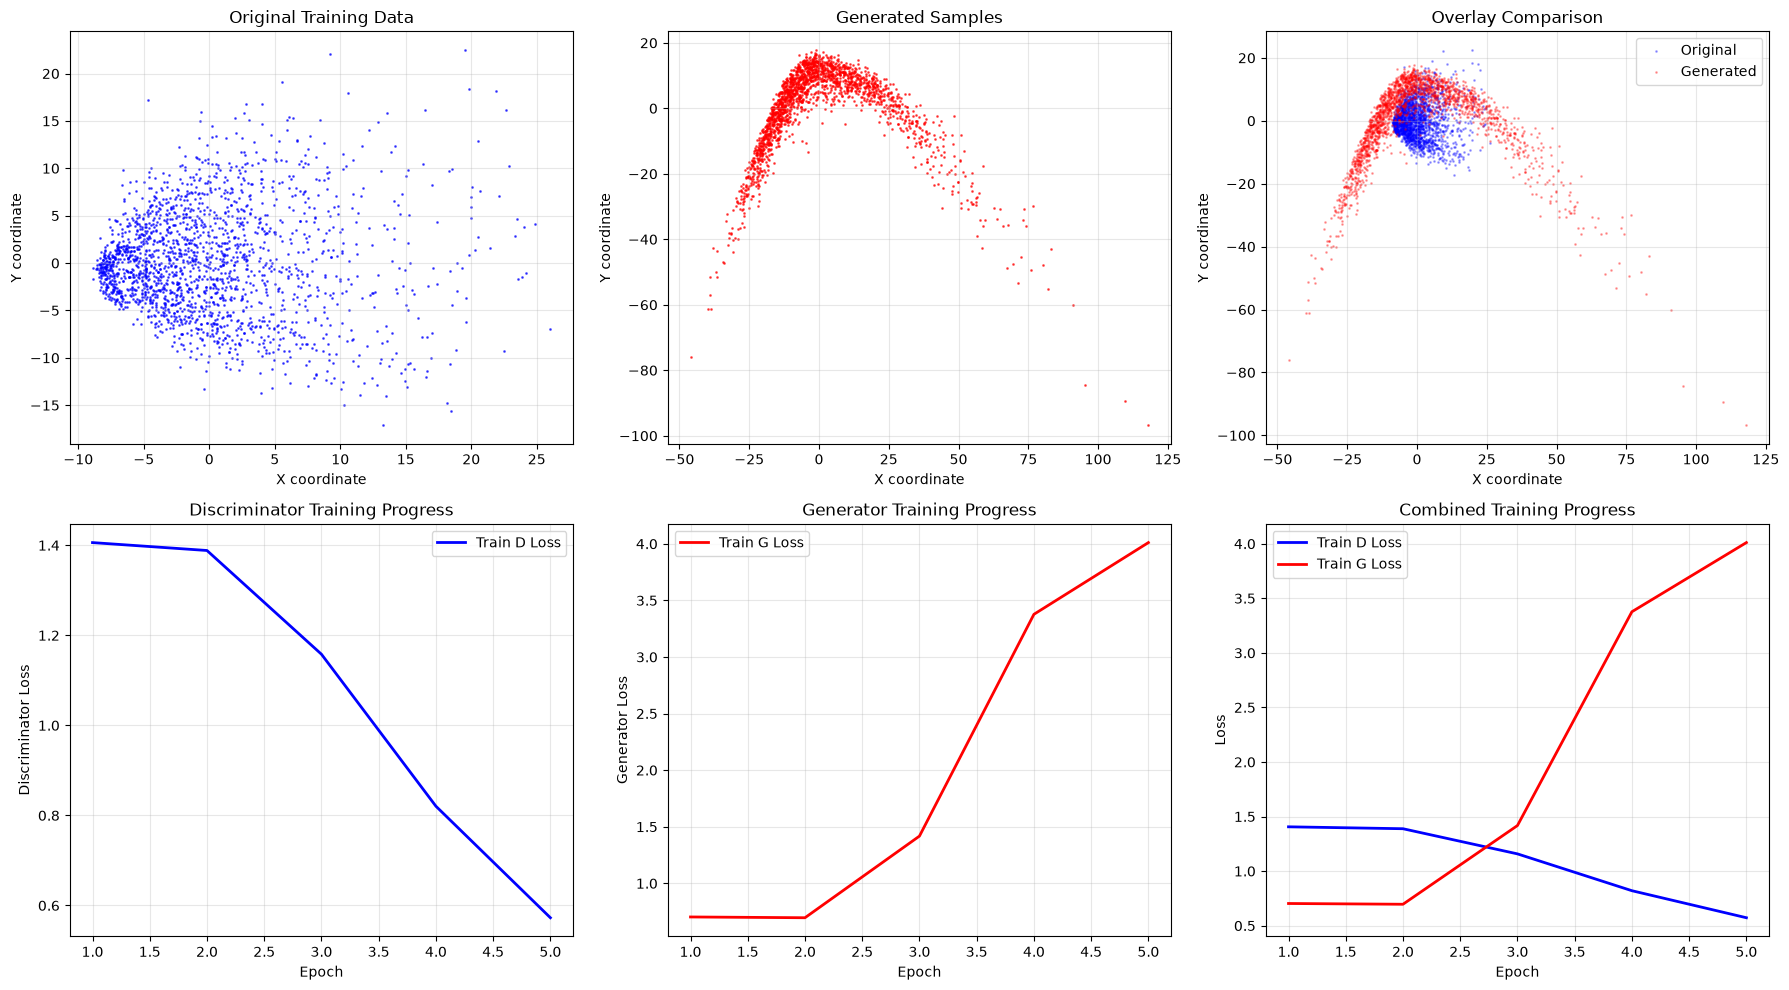

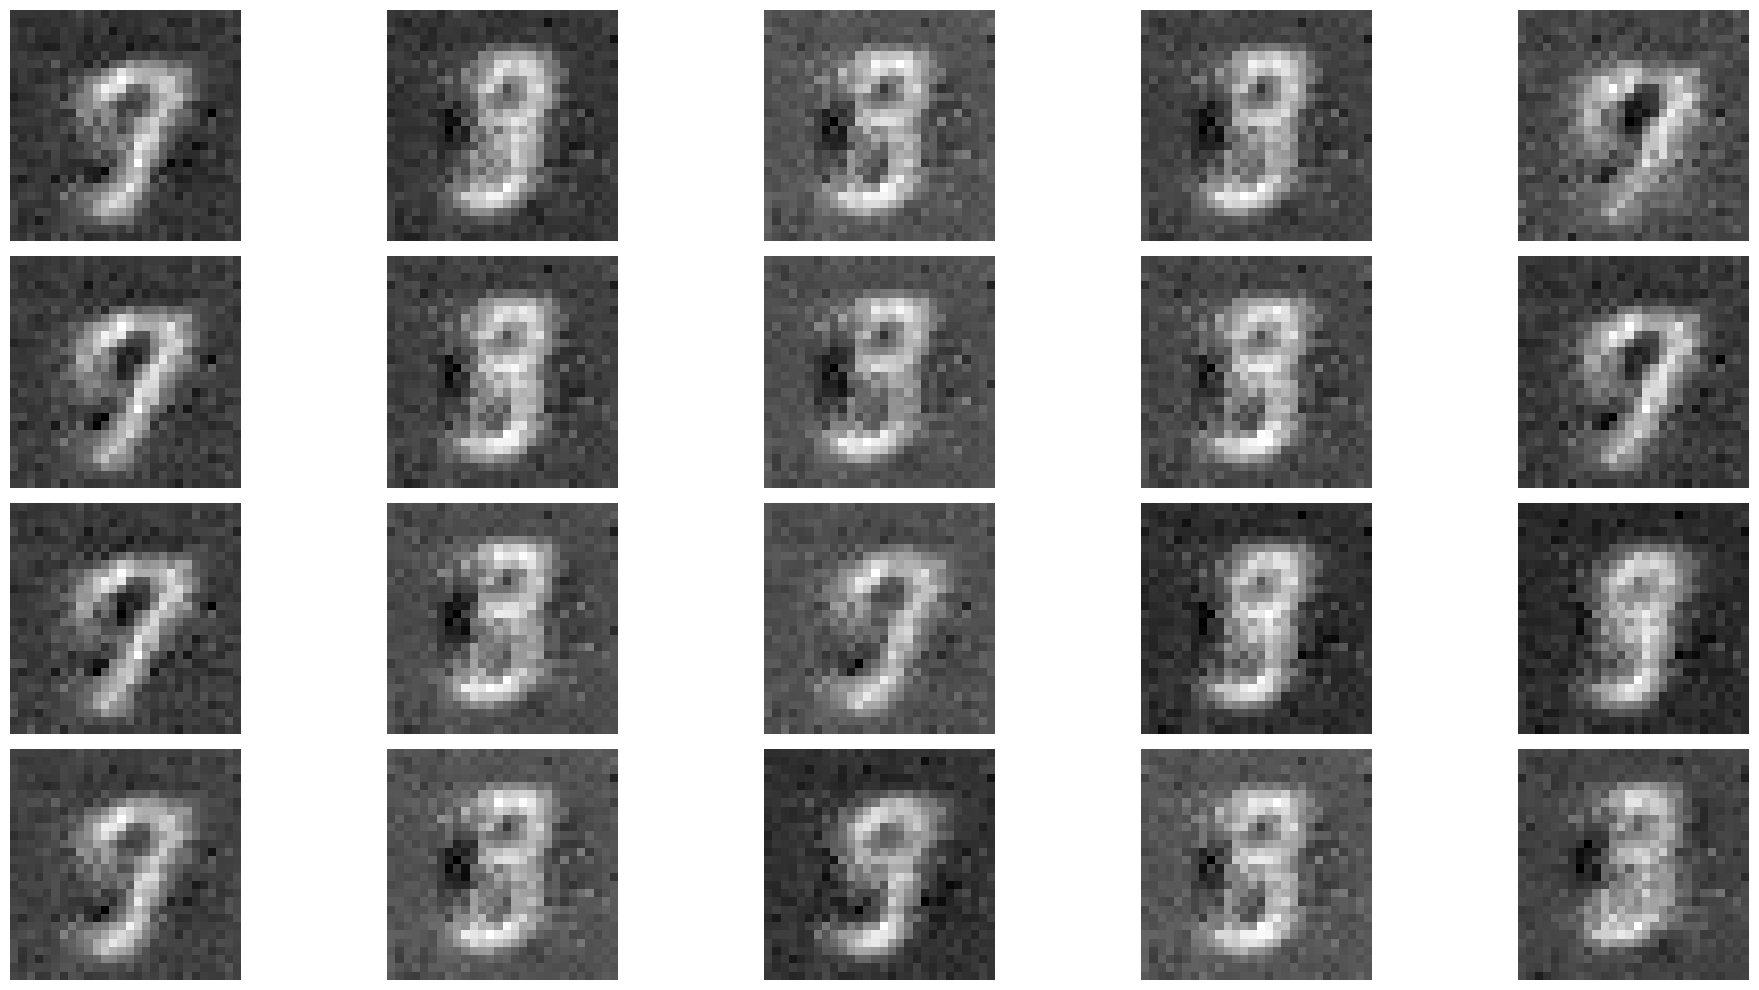

📈 Epoch 5 Summary:
   Train D Loss: 0.5727, Val D Loss: 0.3415
   Train G Loss: 4.0108, Val G Loss: 3.1655

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.348779	G_loss: 4.076484
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.297371	G_loss: 4.693635
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.333909	G_loss: 3.002691
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.367151	G_loss: 4.647931
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.223166	G_loss: 4.057584
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.360803	G_loss: 3.494473
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.320531	G_loss: 3.448807
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.329230	G_loss: 4.218723
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.402528	G_loss: 3.478101
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.252475	G_loss: 3.664513
====> Epoch: 6 Train D_loss: 0.4079, Train G_loss: 4.3844
====> Epoch: 6 Val D_loss: 0.3588, Val G_loss: 2.6508
📈 Epoch 6 Summary:
   Train D Loss: 0.4079, Val D Loss: 0.3588
   Train G Loss: 4.3844, Val G Loss: 2

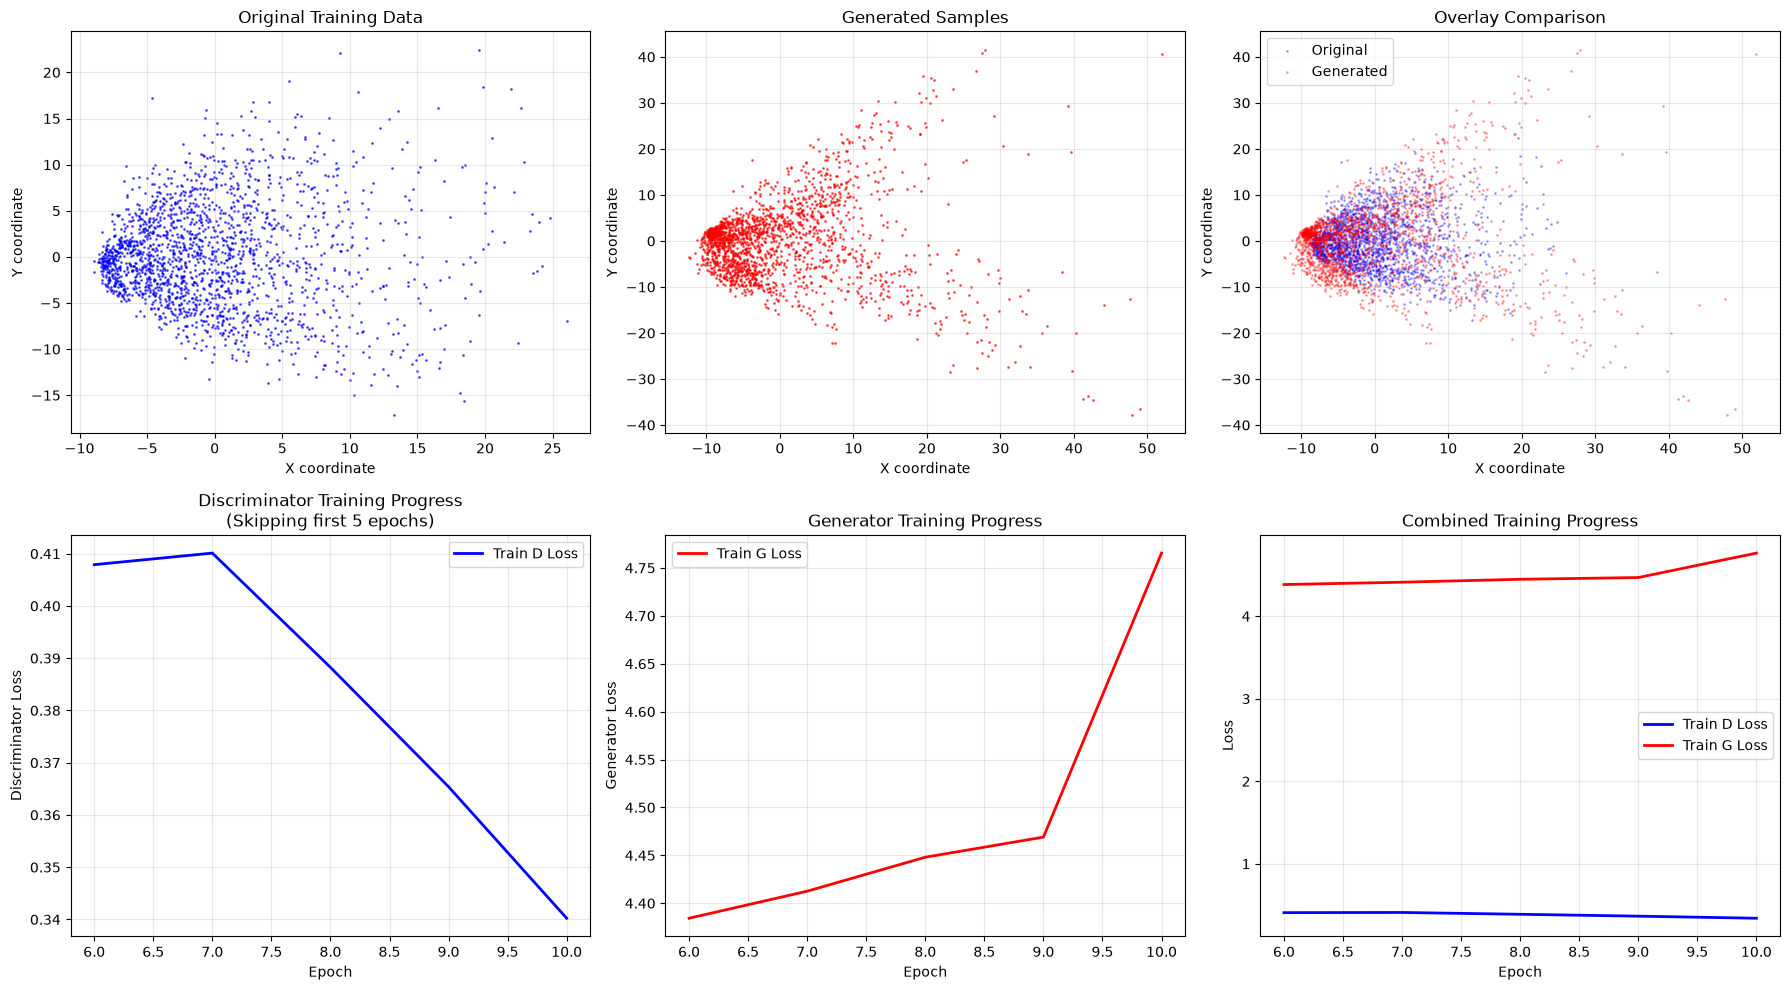

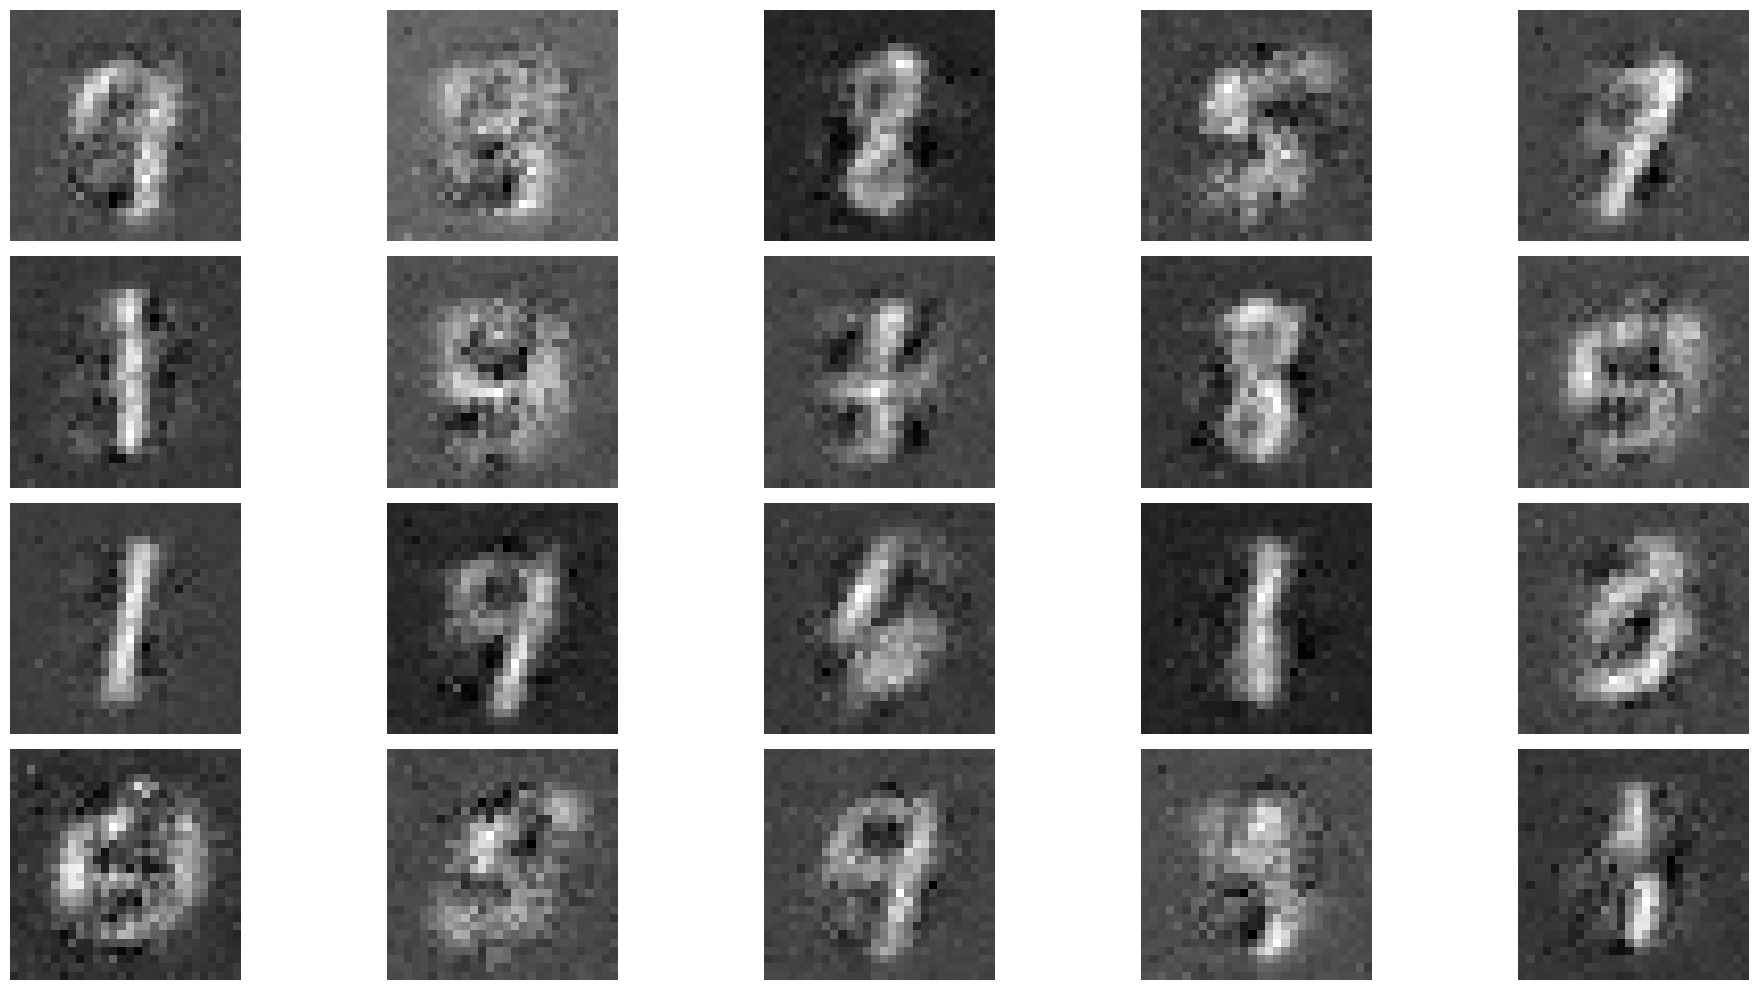

📈 Epoch 10 Summary:
   Train D Loss: 0.3402, Val D Loss: 0.3453
   Train G Loss: 4.7655, Val G Loss: 2.7668

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.328253	G_loss: 4.383347
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.239160	G_loss: 3.998159
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.228967	G_loss: 4.699118
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.176346	G_loss: 3.820889
Epoch: 11 [25600/60000 (43%)]	D_loss: 3.110793	G_loss: 3.609553
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.199502	G_loss: 3.790119
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.132510	G_loss: 4.814333
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.377527	G_loss: 3.008043
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.131979	G_loss: 5.308272
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.445877	G_loss: 3.131356
====> Epoch: 11 Train D_loss: 0.3770, Train G_loss: 4.5506
====> Epoch: 11 Val D_loss: 0.2040, Val G_loss: 3.6220
📈 Epoch 11 Summary:
   Train D Loss: 0.3770, Val D Loss: 0.2040
   Train G Loss: 4.5506

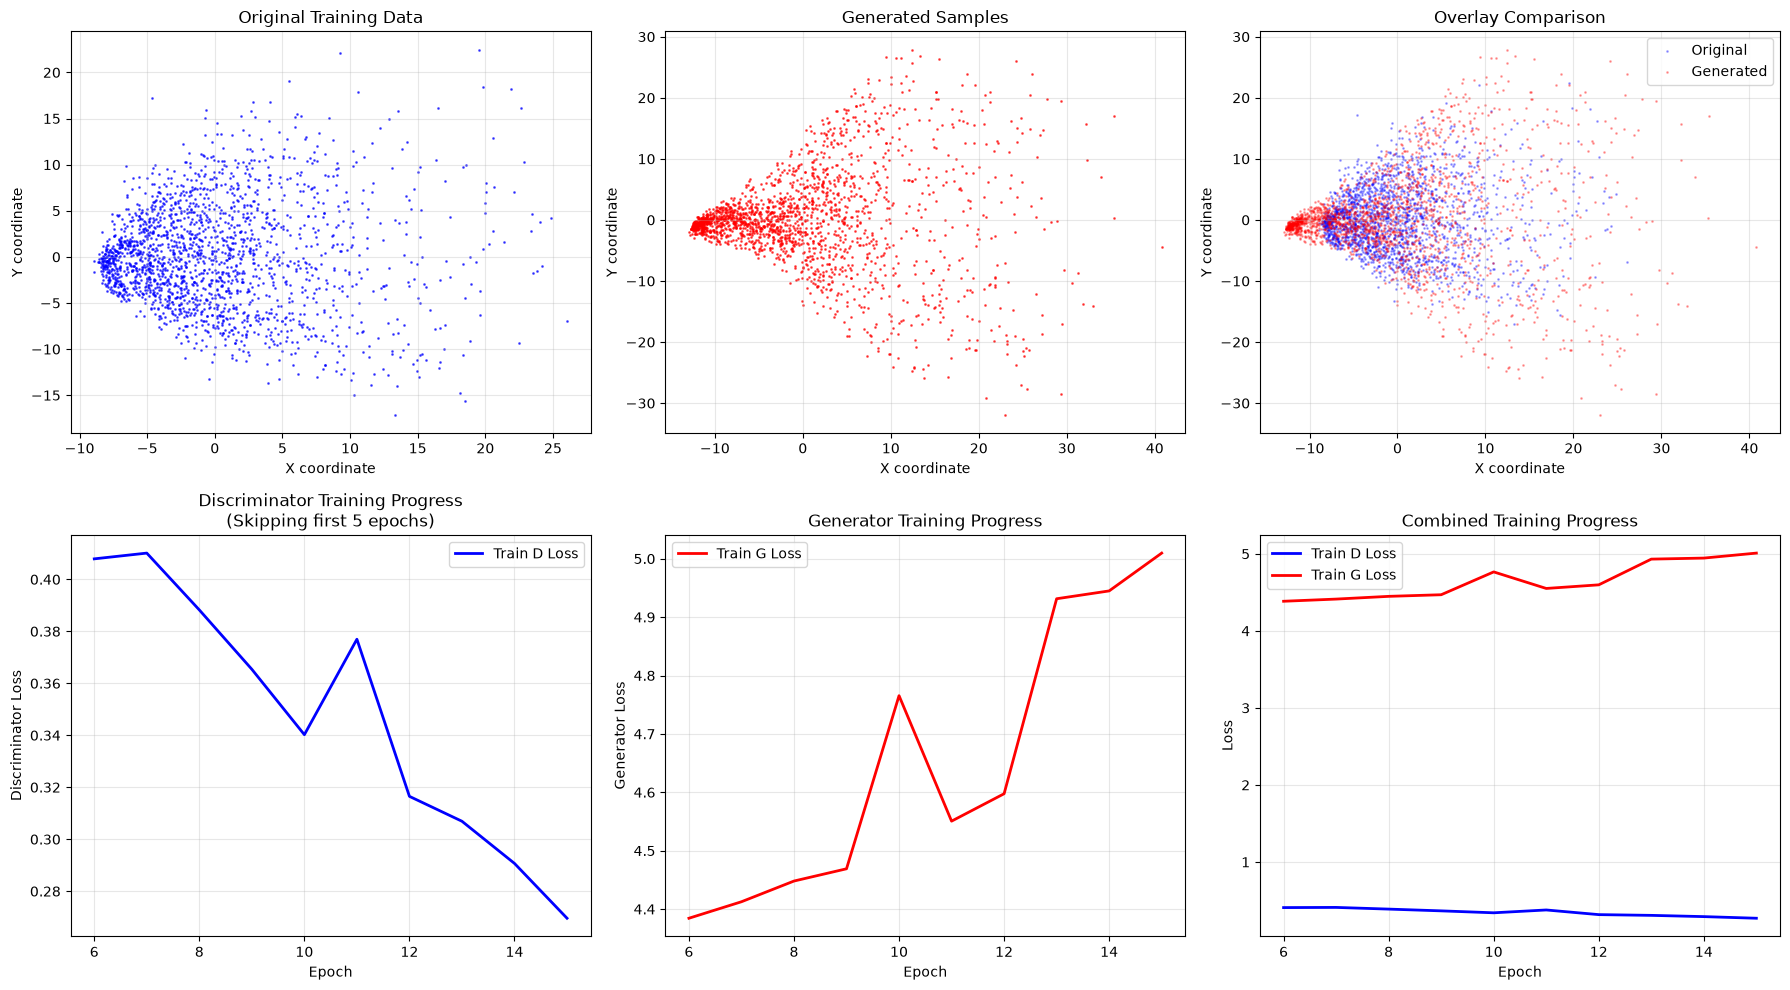

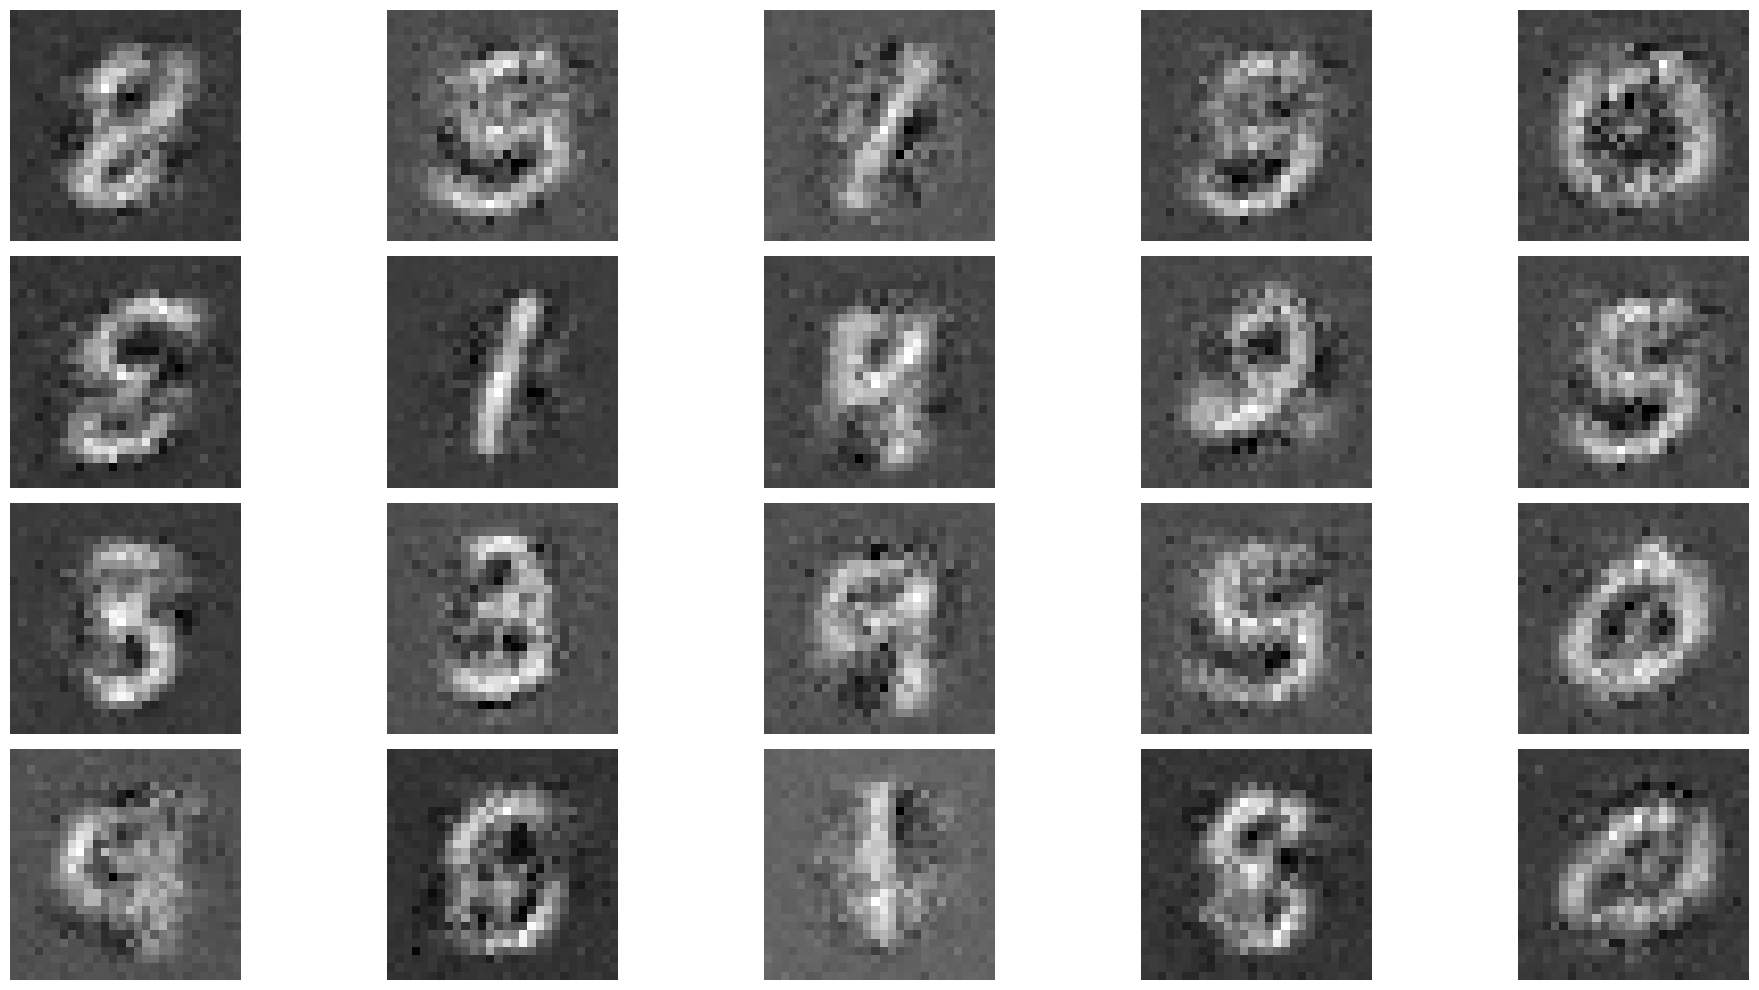

📈 Epoch 15 Summary:
   Train D Loss: 0.2696, Val D Loss: 0.2760
   Train G Loss: 5.0096, Val G Loss: 3.2824

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.317304	G_loss: 9.086342
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.110096	G_loss: 5.068423
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.222936	G_loss: 4.806212
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.097754	G_loss: 5.203617
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.261405	G_loss: 7.483183
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.145335	G_loss: 5.943911
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.342763	G_loss: 6.650705
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.555472	G_loss: 5.571941
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.128663	G_loss: 5.020831
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.510439	G_loss: 5.374972
====> Epoch: 16 Train D_loss: 0.2910, Train G_loss: 5.1715
====> Epoch: 16 Val D_loss: 0.3463, Val G_loss: 3.7142
📈 Epoch 16 Summary:
   Train D Loss: 0.2910, Val D Loss: 0.3463
   Train G Loss: 5.1715

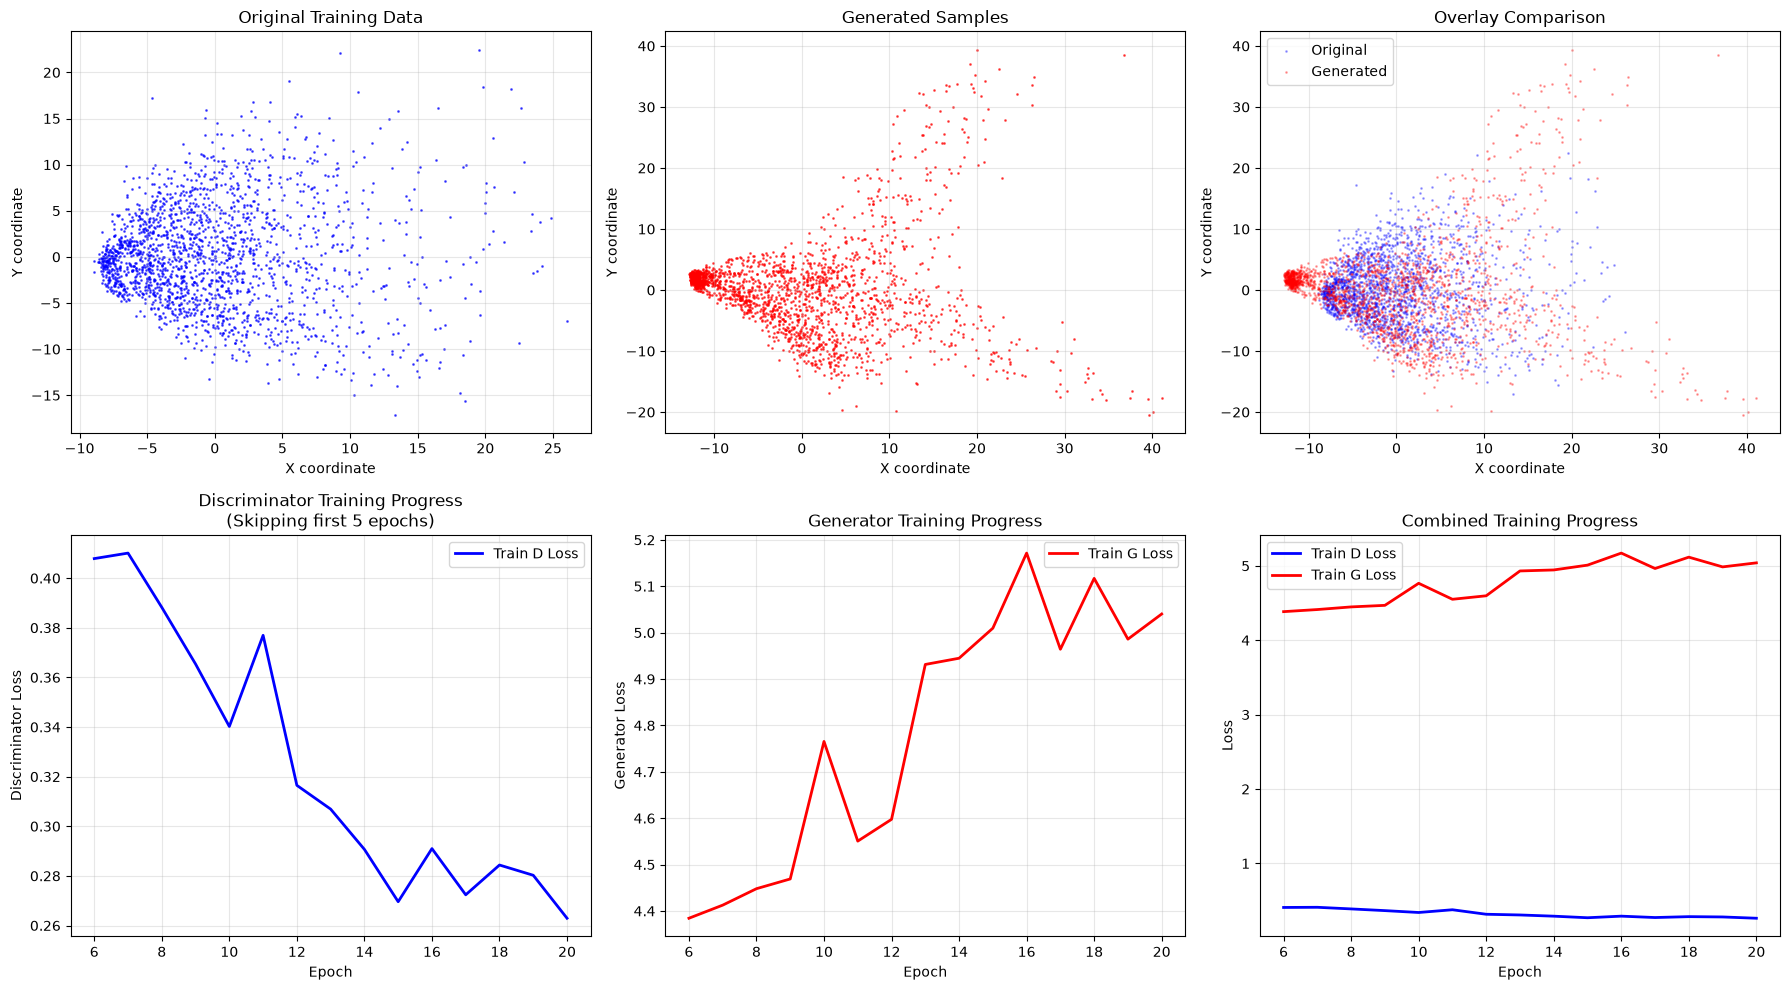

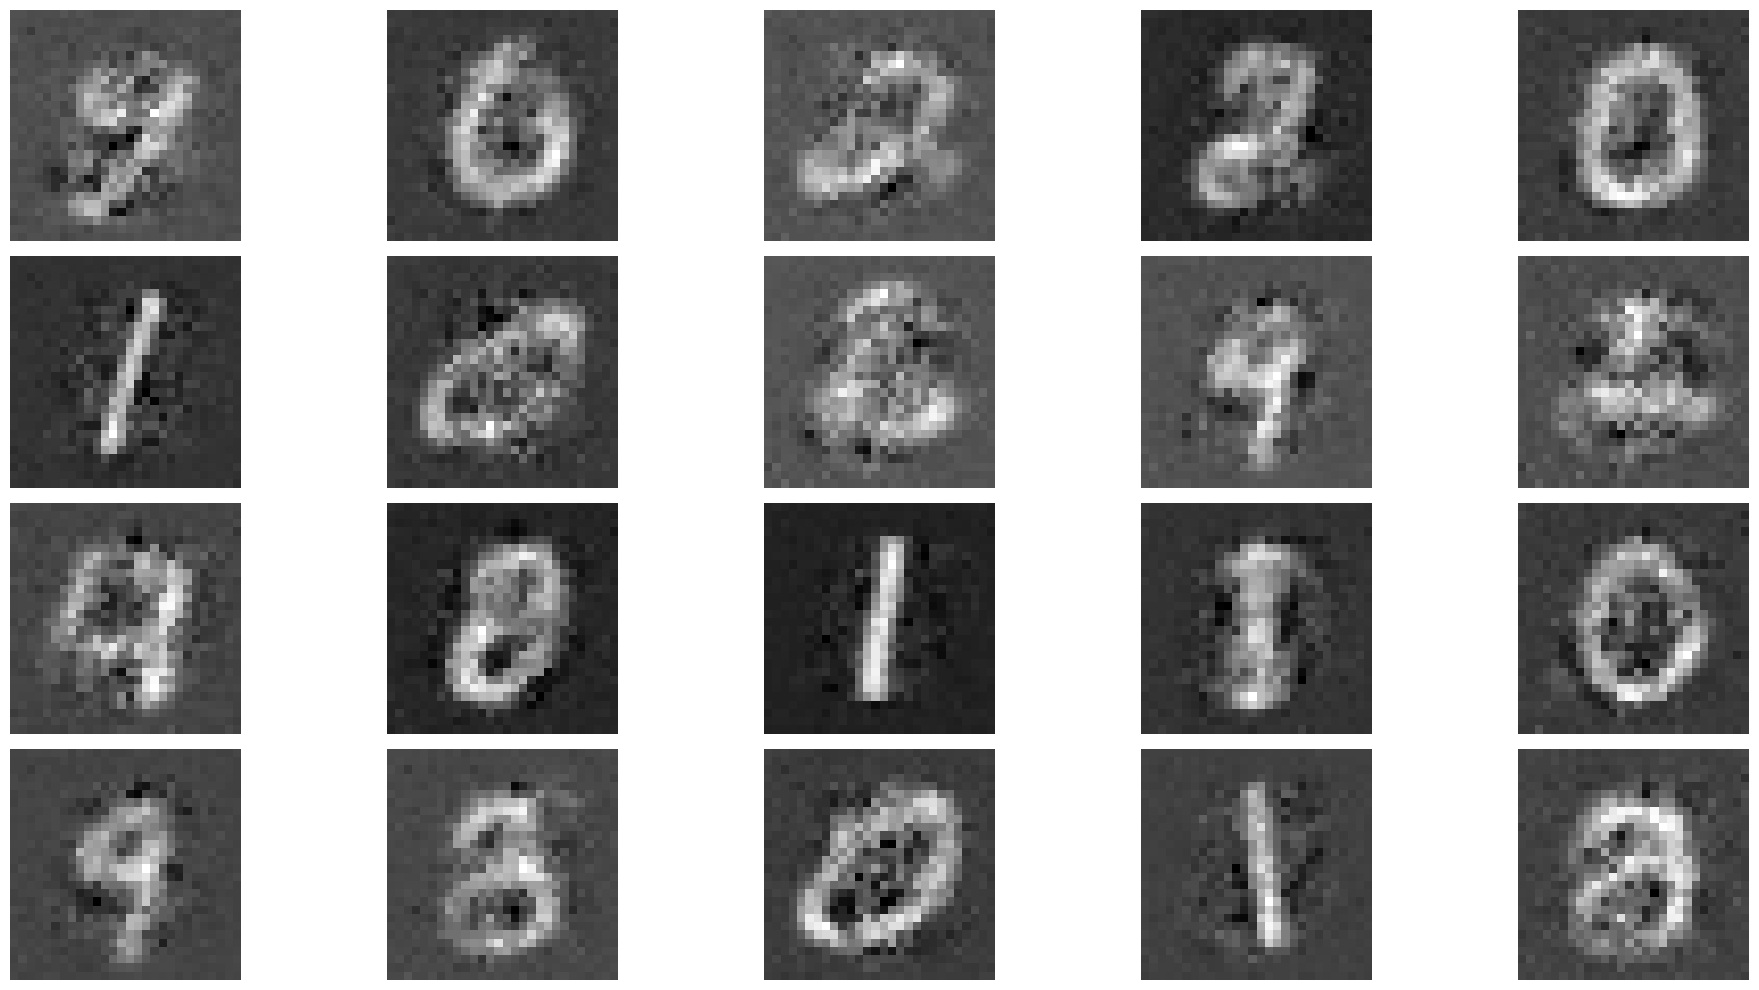

📈 Epoch 20 Summary:
   Train D Loss: 0.2629, Val D Loss: 0.4321
   Train G Loss: 5.0402, Val G Loss: 2.5455

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.410389	G_loss: 8.482172
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.156801	G_loss: 4.479181
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.312061	G_loss: 4.471360
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.311332	G_loss: 5.029251
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.105805	G_loss: 4.328420
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.155341	G_loss: 5.816175
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.118731	G_loss: 5.895772
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.194397	G_loss: 4.410305
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.379242	G_loss: 5.063388
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.551297	G_loss: 5.763937
====> Epoch: 21 Train D_loss: 0.2899, Train G_loss: 5.0119
====> Epoch: 21 Val D_loss: 0.2736, Val G_loss: 2.6453
📈 Epoch 21 Summary:
   Train D Loss: 0.2899, Val D Loss: 0.2736
   Train G Loss: 5.0119

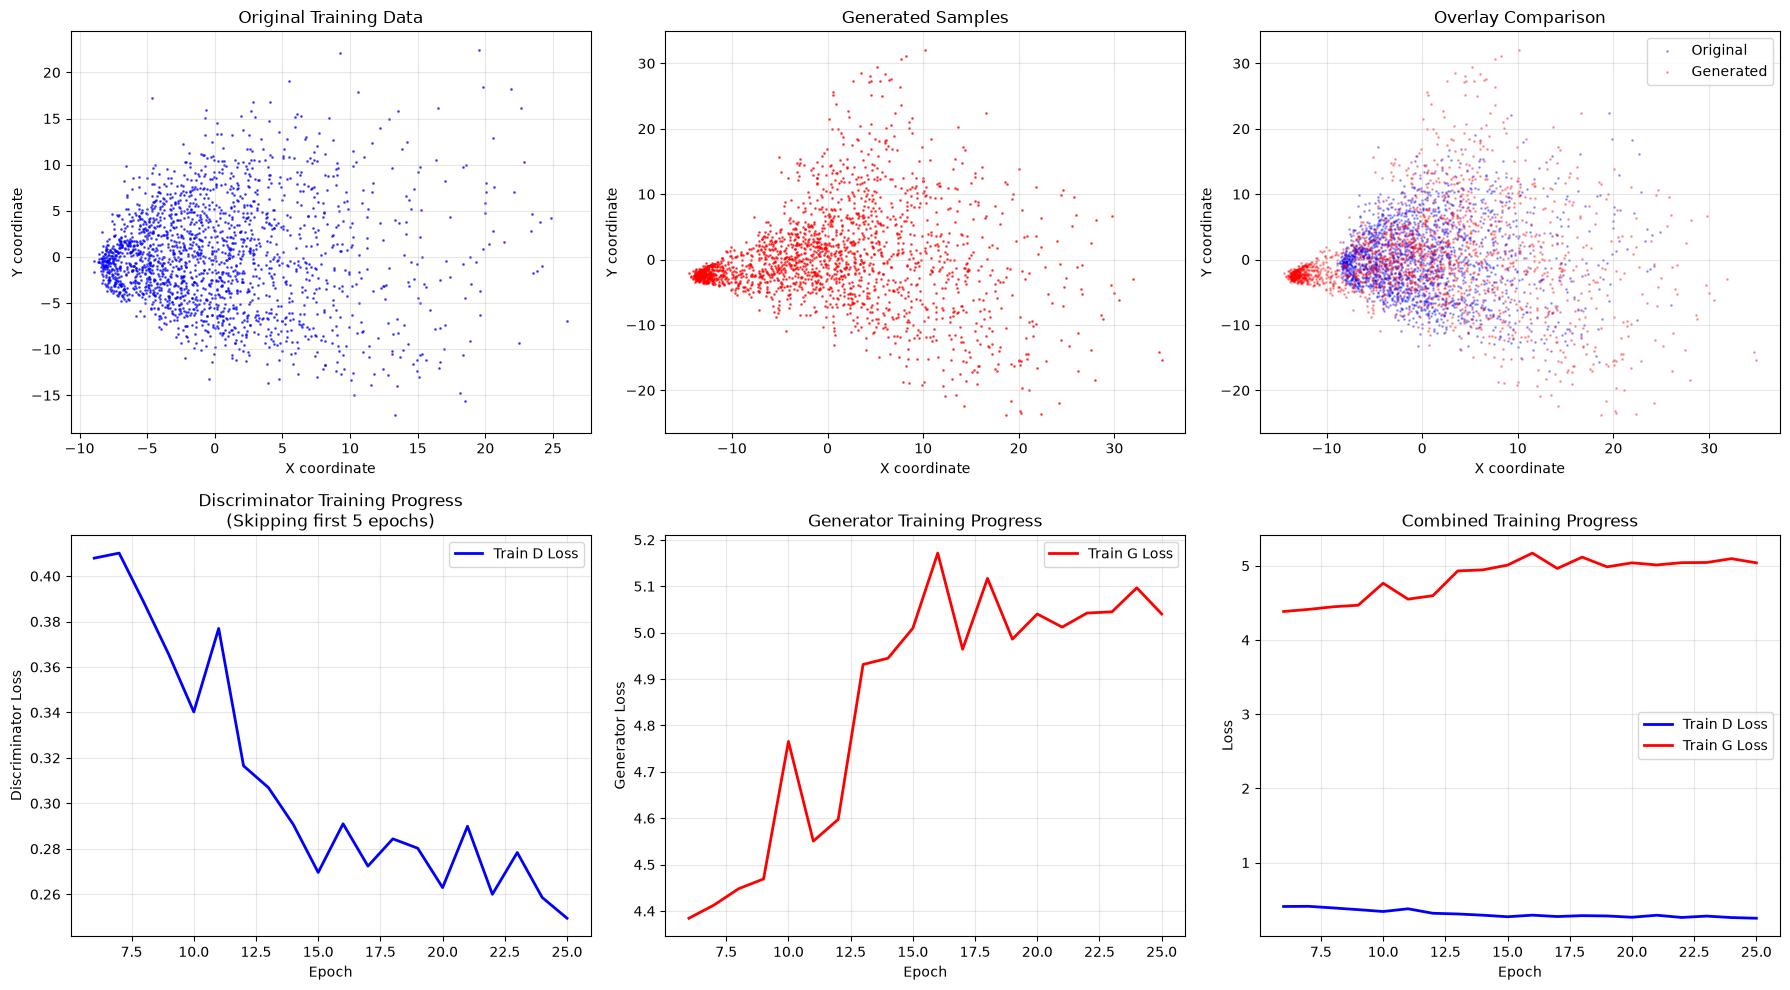

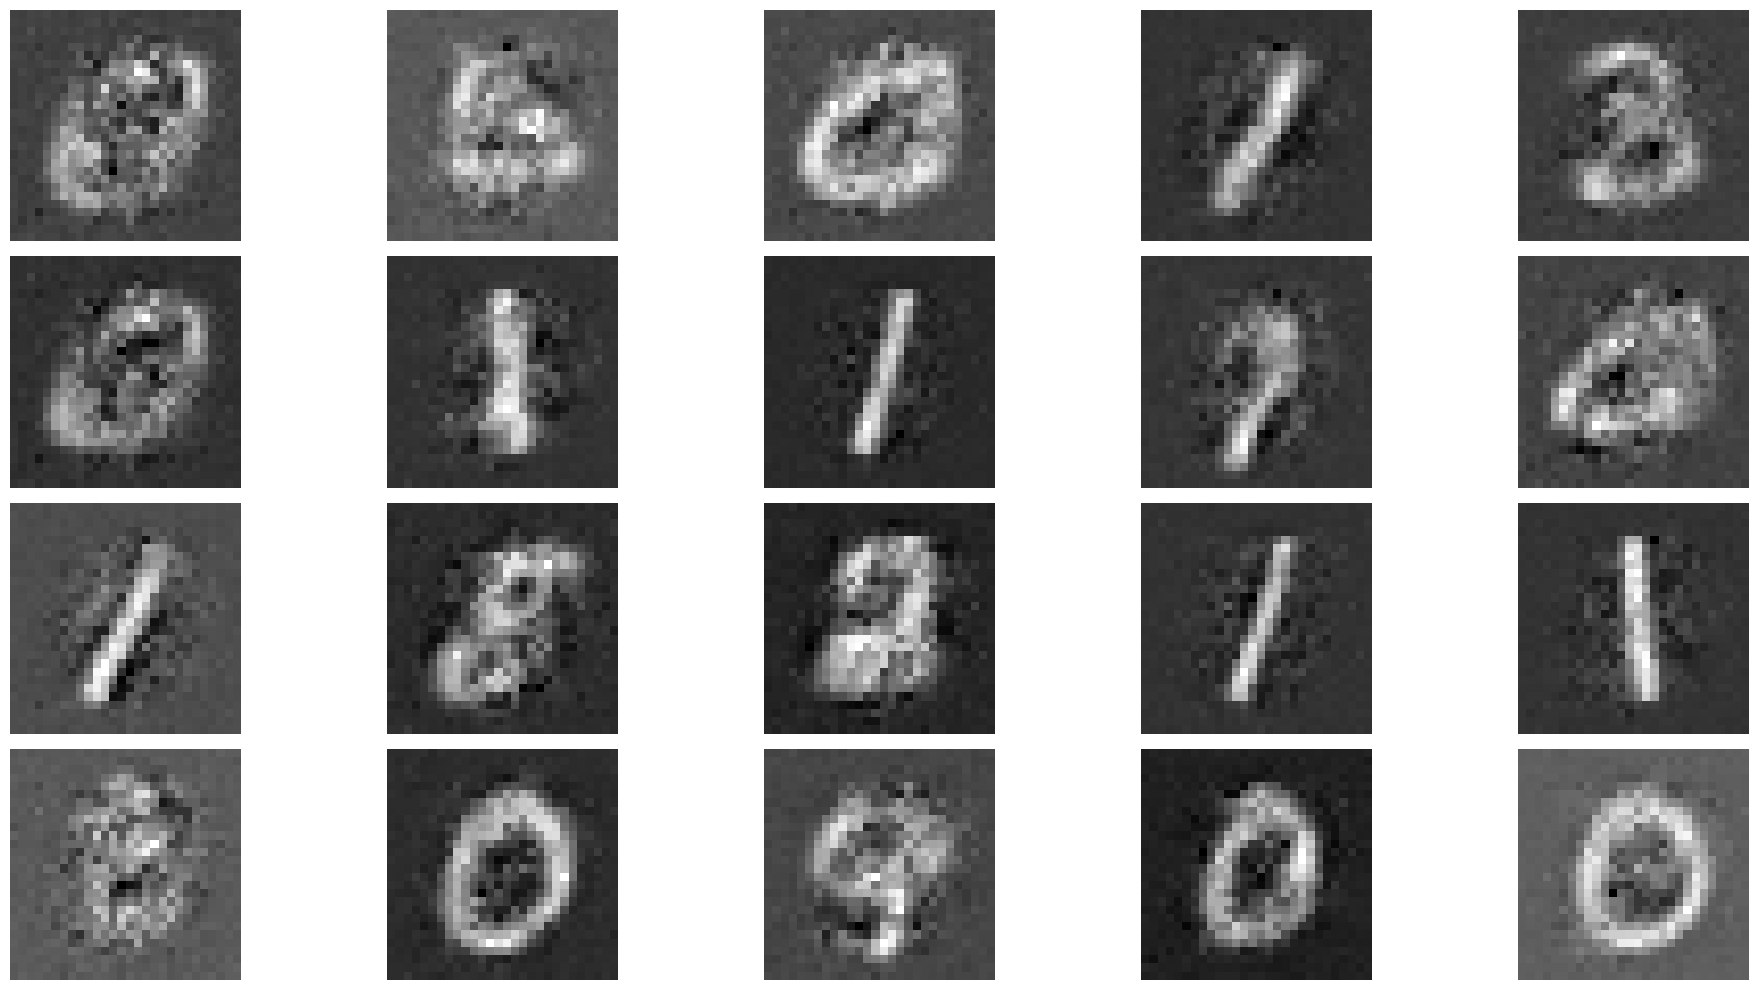

📈 Epoch 25 Summary:
   Train D Loss: 0.2494, Val D Loss: 0.3543
   Train G Loss: 5.0403, Val G Loss: 6.2129

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.281858	G_loss: 5.008590
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.146308	G_loss: 6.071733
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.107909	G_loss: 5.039971
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.076989	G_loss: 5.437627
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.121524	G_loss: 6.131871
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.281922	G_loss: 3.767967
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.187078	G_loss: 3.770694
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.250600	G_loss: 6.248773
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.131829	G_loss: 4.013348
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.330144	G_loss: 4.599623
====> Epoch: 26 Train D_loss: 0.2558, Train G_loss: 5.1412
====> Epoch: 26 Val D_loss: 0.3191, Val G_loss: 3.8941
📈 Epoch 26 Summary:
   Train D Loss: 0.2558, Val D Loss: 0.3191
   Train G Loss: 5.1412

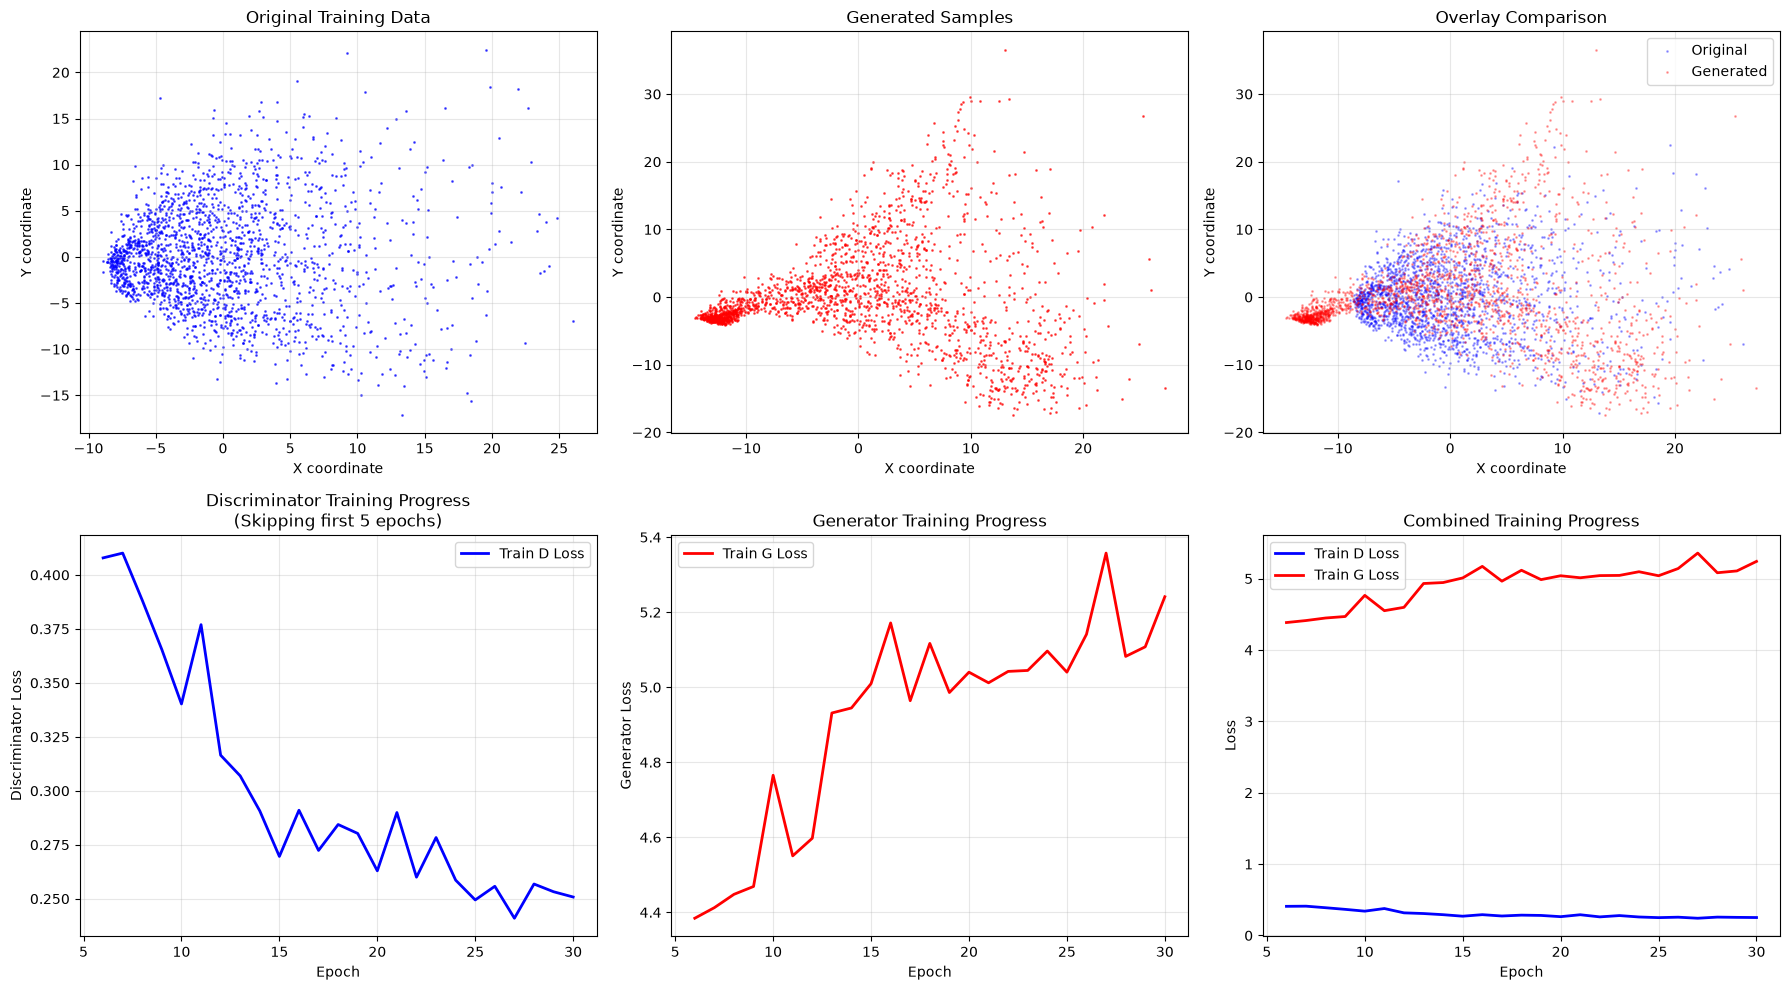

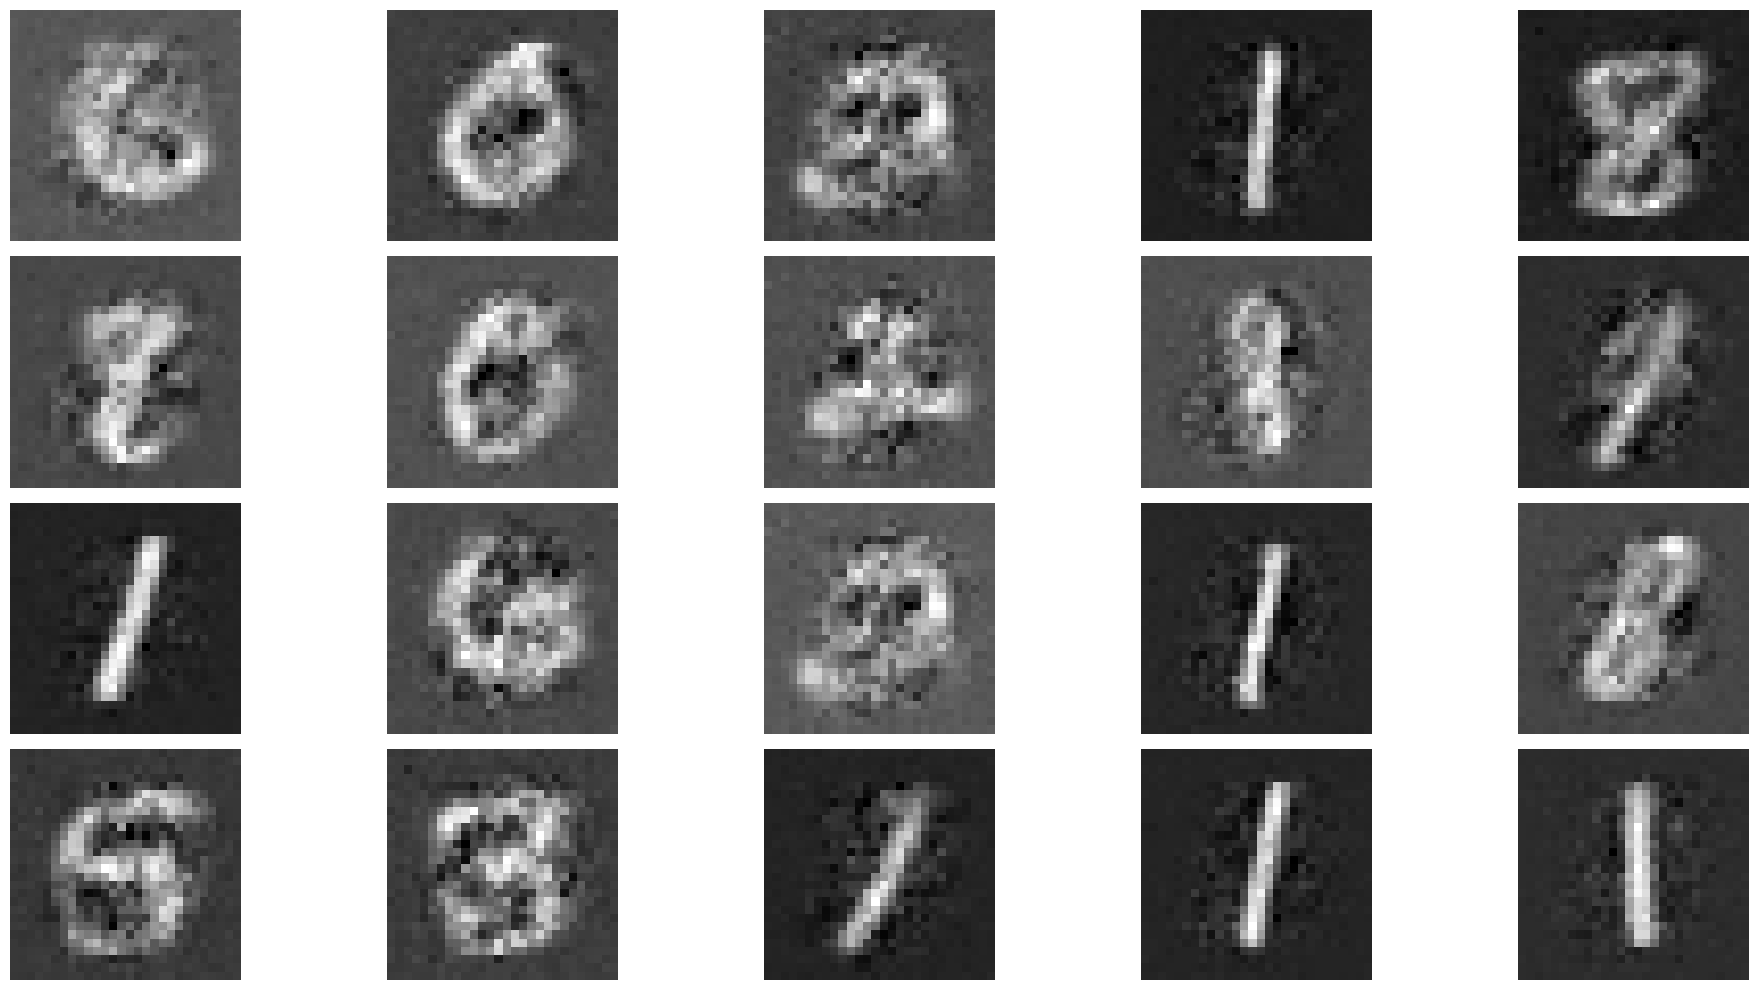

📈 Epoch 30 Summary:
   Train D Loss: 0.2508, Val D Loss: 0.1886
   Train G Loss: 5.2413, Val G Loss: 5.6475

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.146820	G_loss: 4.765211
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.297060	G_loss: 6.291968
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.225621	G_loss: 6.360110
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.301250	G_loss: 5.854740
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.122330	G_loss: 5.332709
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.266506	G_loss: 3.487525
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.400780	G_loss: 3.365395
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.186886	G_loss: 3.500288
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.283369	G_loss: 6.886570
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.085053	G_loss: 4.786216
====> Epoch: 31 Train D_loss: 0.2690, Train G_loss: 5.0524
====> Epoch: 31 Val D_loss: 0.3474, Val G_loss: 2.5080
📈 Epoch 31 Summary:
   Train D Loss: 0.2690, Val D Loss: 0.3474
   Train G Loss: 5.0524

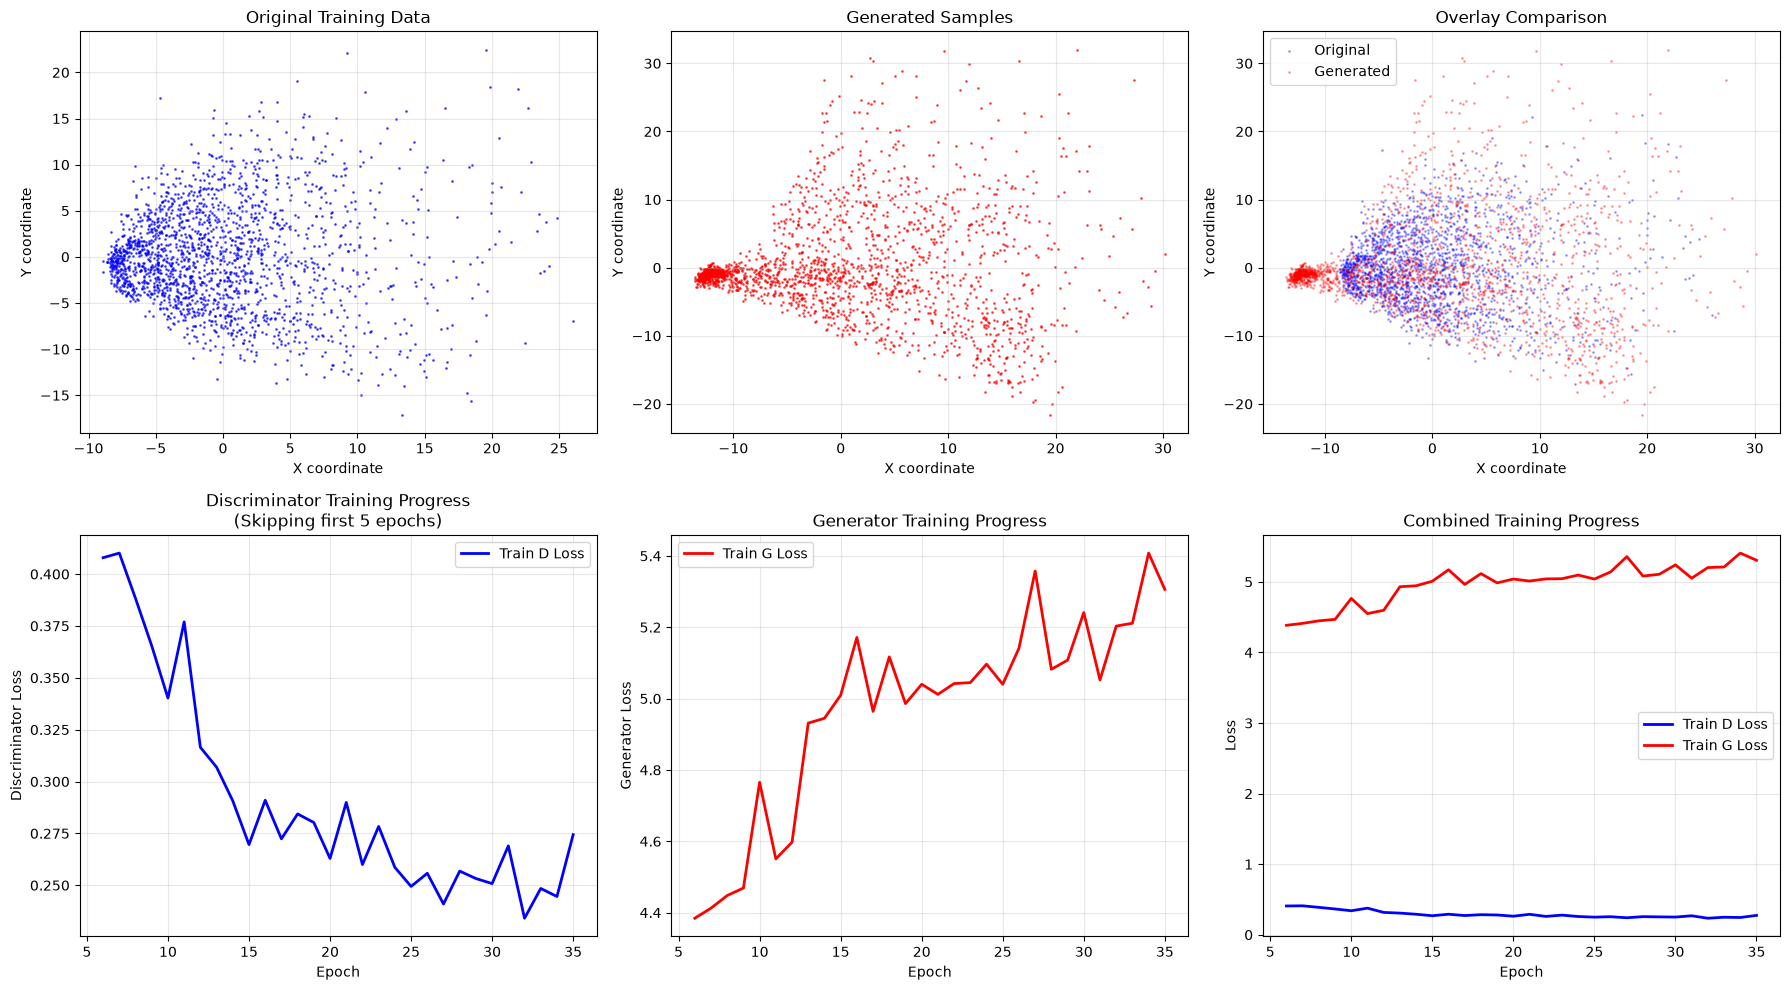

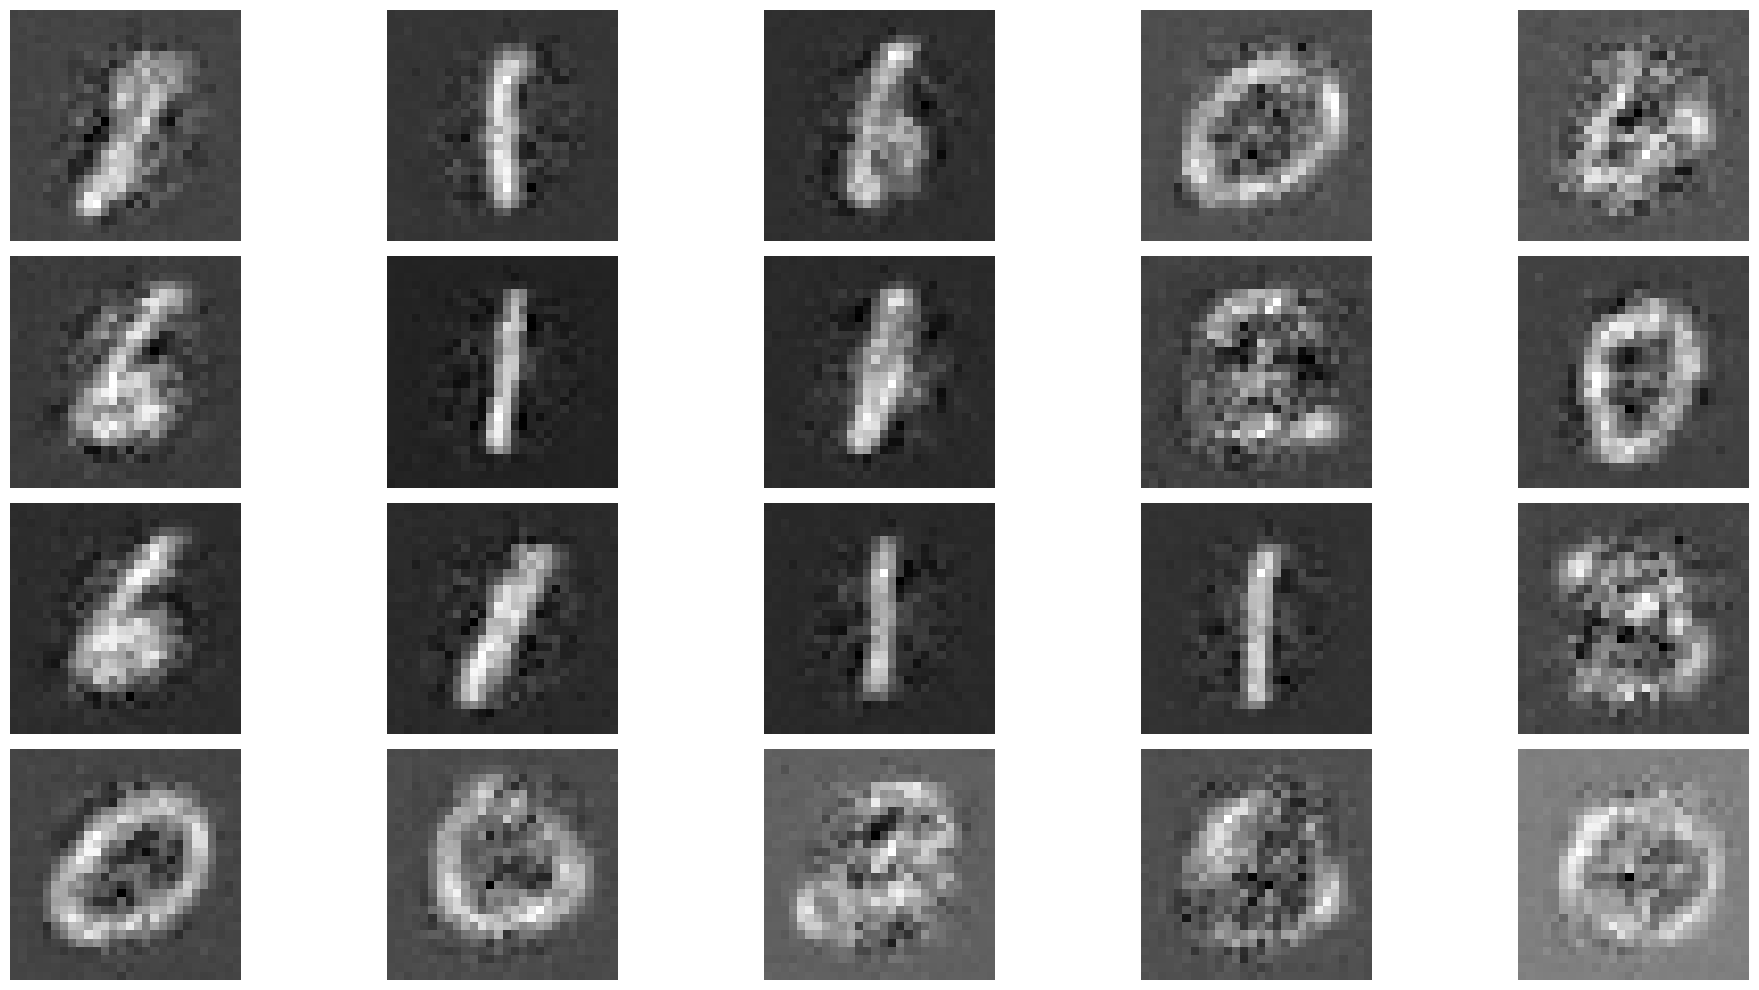

📈 Epoch 35 Summary:
   Train D Loss: 0.2744, Val D Loss: 0.2099
   Train G Loss: 5.3061, Val G Loss: 3.7005

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.216151	G_loss: 4.226194
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.156667	G_loss: 5.464262
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.140816	G_loss: 5.378262
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.139495	G_loss: 4.046418
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.358675	G_loss: 6.593789
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.217672	G_loss: 3.788710
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.185040	G_loss: 3.690308
Epoch: 36 [44800/60000 (75%)]	D_loss: 2.179923	G_loss: 8.768773
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.436148	G_loss: 4.761036
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.155884	G_loss: 5.694391
====> Epoch: 36 Train D_loss: 0.2357, Train G_loss: 5.2132
====> Epoch: 36 Val D_loss: 0.2555, Val G_loss: 2.7205
📈 Epoch 36 Summary:
   Train D Loss: 0.2357, Val D Loss: 0.2555
   Train G Loss: 5.2132

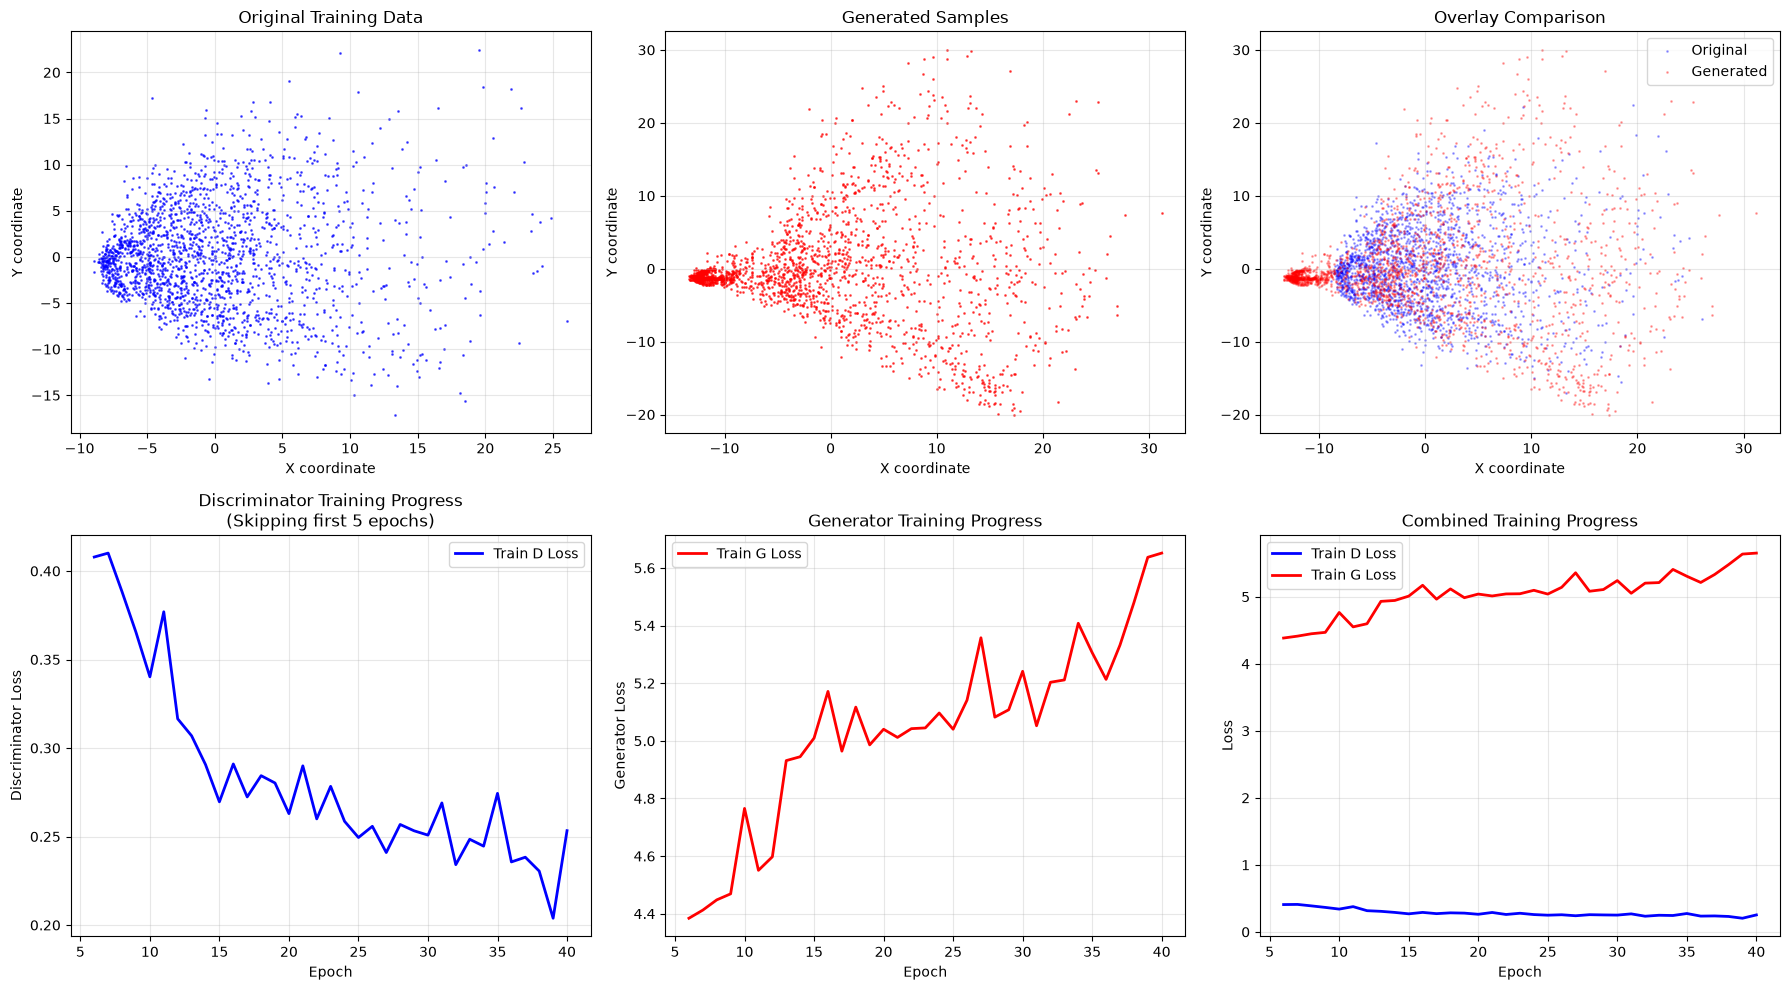

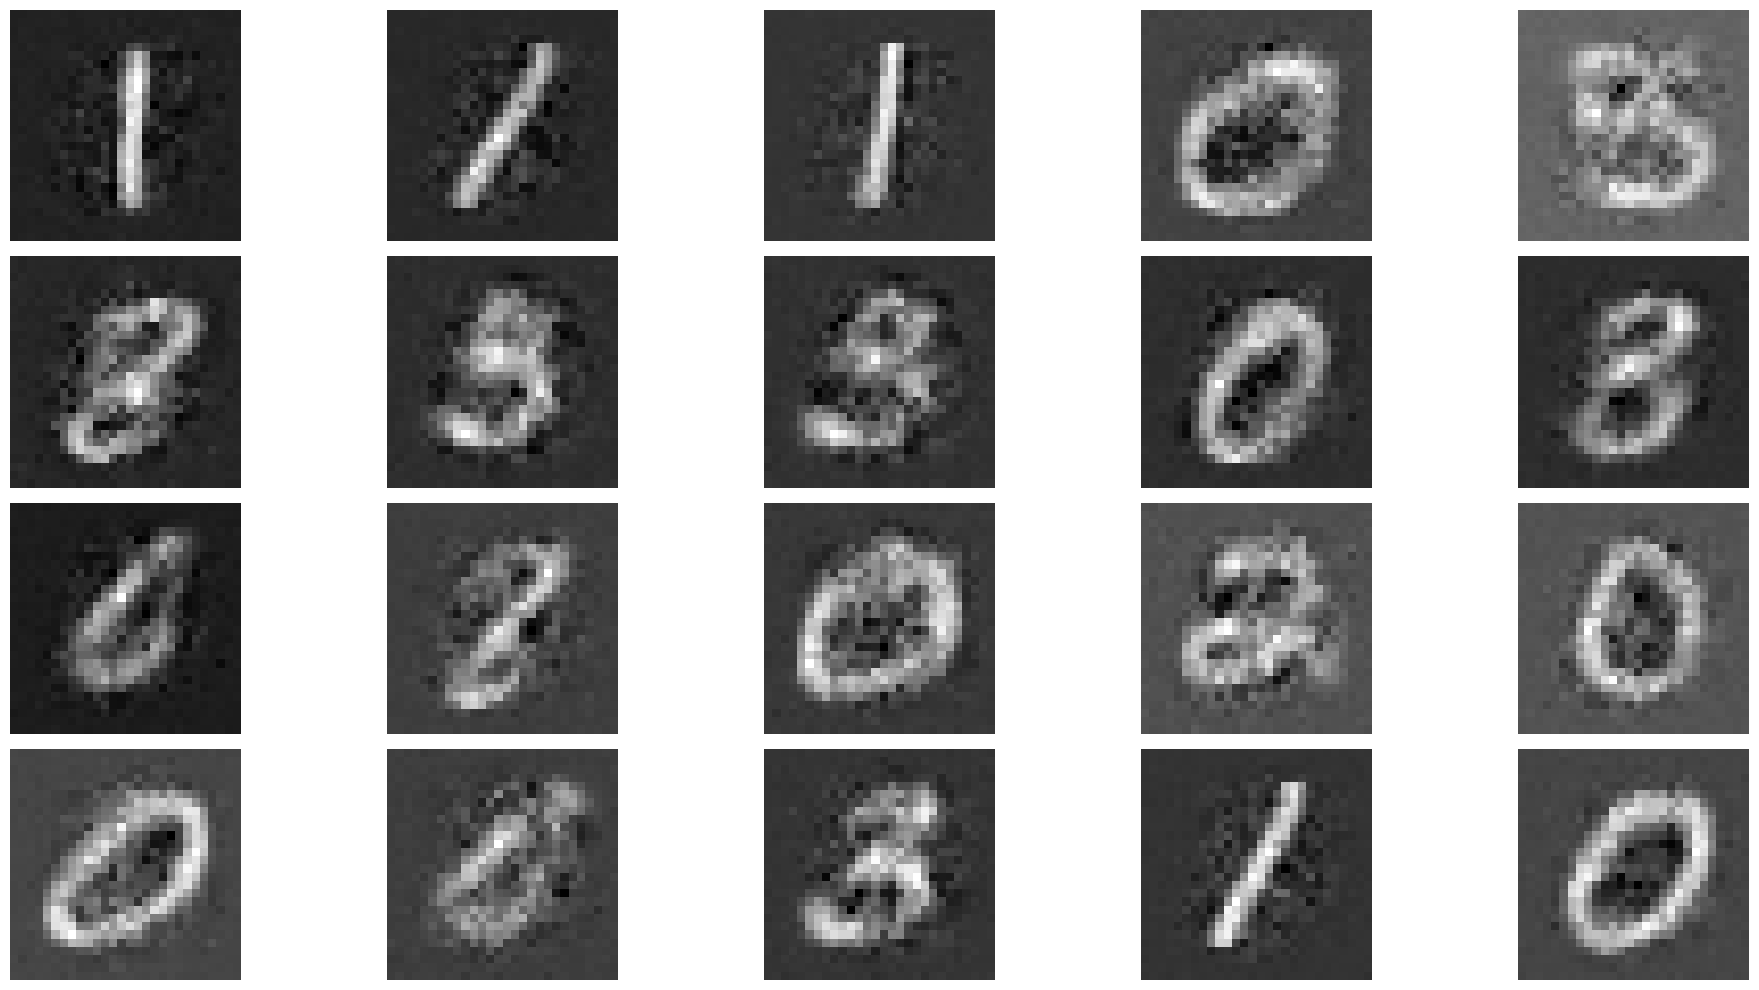

📈 Epoch 40 Summary:
   Train D Loss: 0.2533, Val D Loss: 0.2267
   Train G Loss: 5.6515, Val G Loss: 3.5686

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.171268	G_loss: 4.062037
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.226937	G_loss: 5.772094
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.164545	G_loss: 5.048064
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.190639	G_loss: 5.489558
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.178193	G_loss: 7.620433
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.619038	G_loss: 5.641436
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.213647	G_loss: 4.523542
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.155531	G_loss: 5.683455
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.125098	G_loss: 4.364944
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.268538	G_loss: 4.814625
====> Epoch: 41 Train D_loss: 0.2070, Train G_loss: 5.4169
====> Epoch: 41 Val D_loss: 0.3855, Val G_loss: 2.9545
📈 Epoch 41 Summary:
   Train D Loss: 0.2070, Val D Loss: 0.3855
   Train G Loss: 5.4169

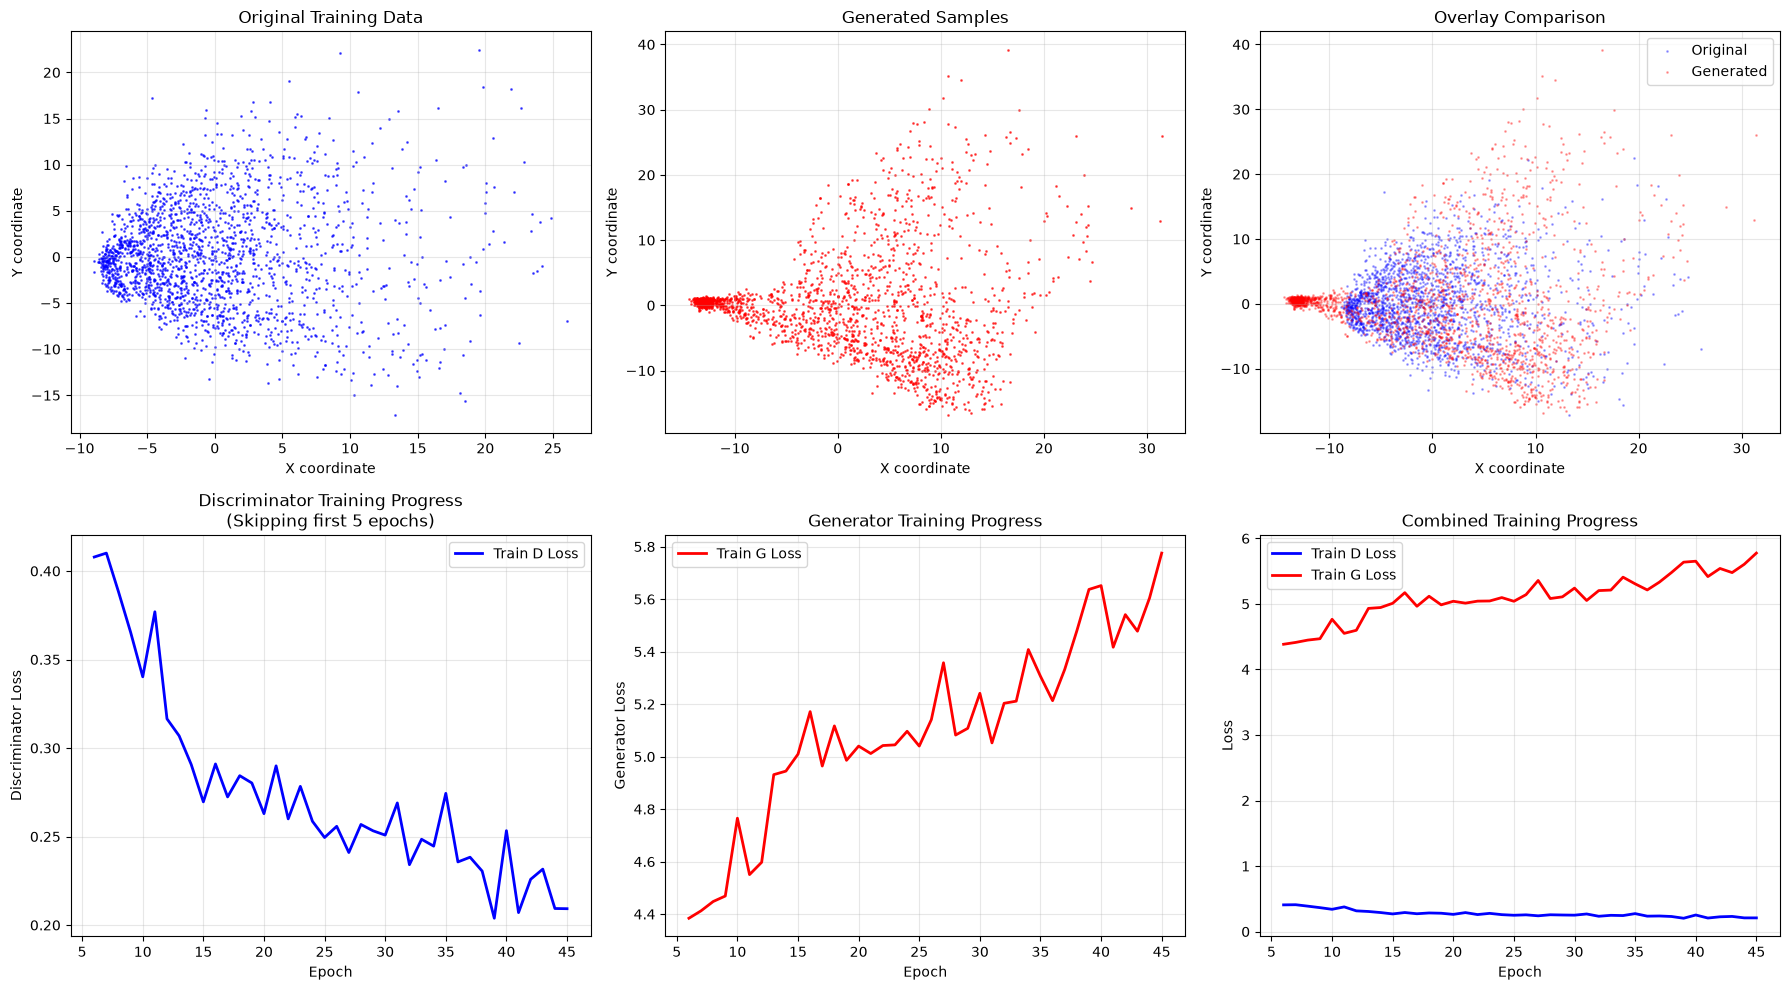

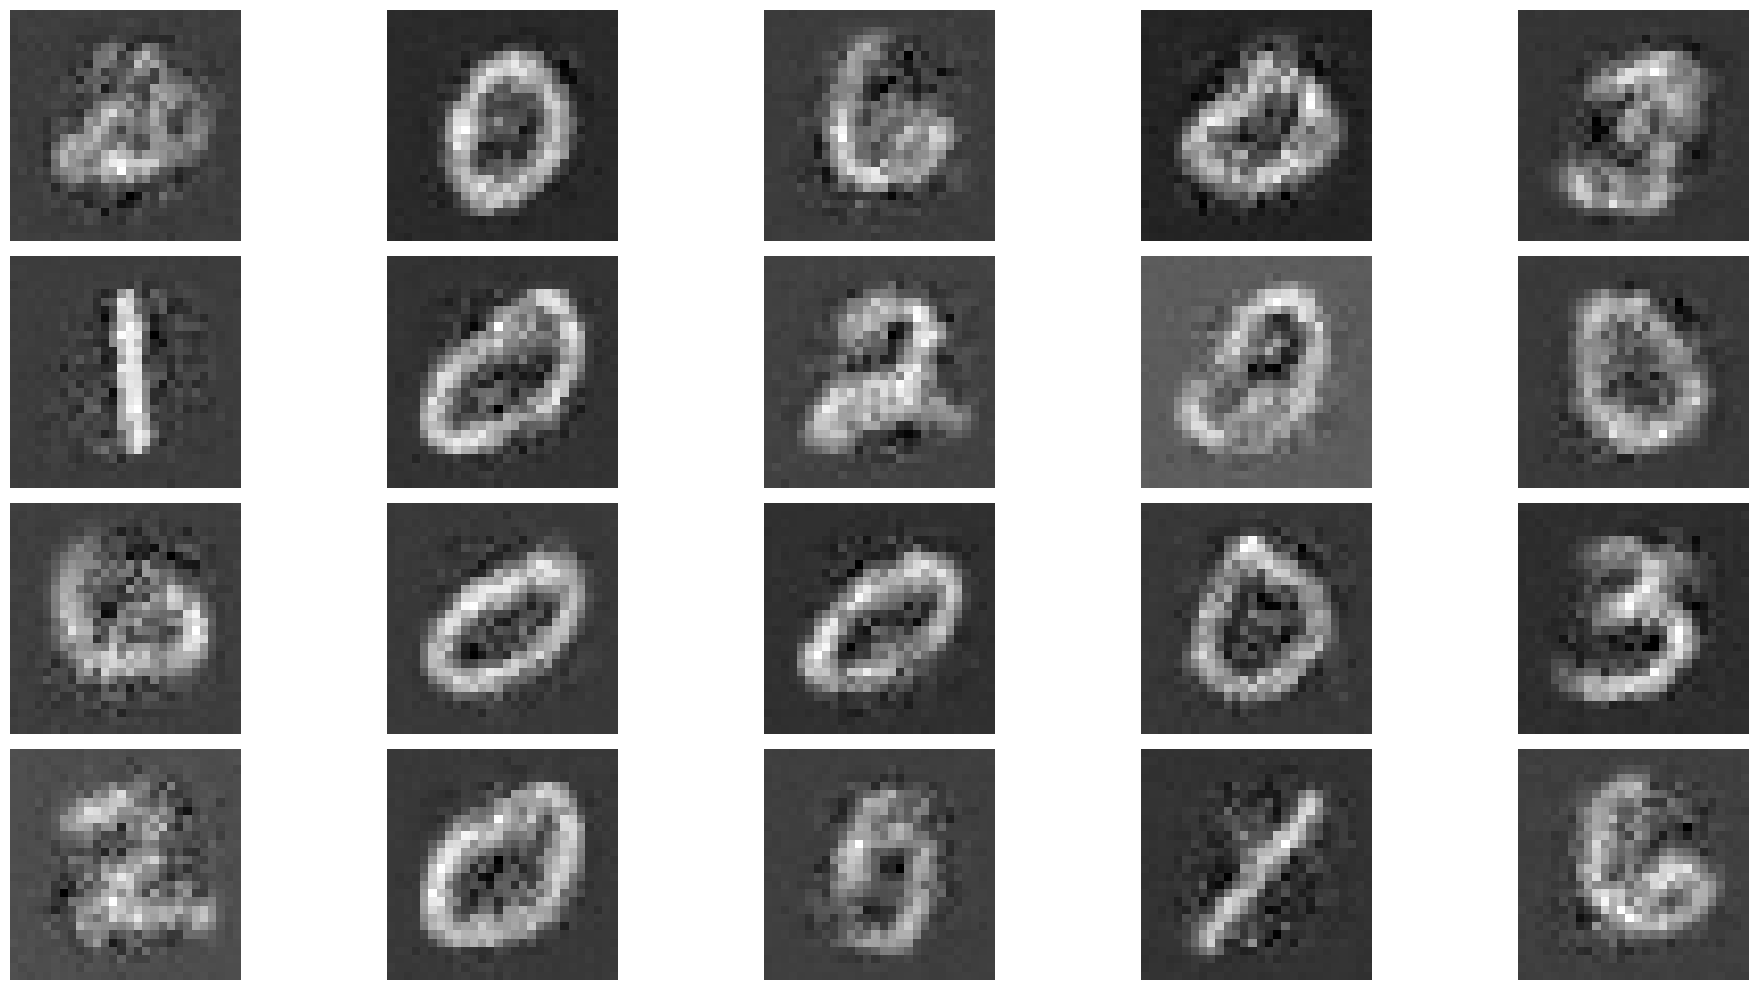

📈 Epoch 45 Summary:
   Train D Loss: 0.2092, Val D Loss: 0.1776
   Train G Loss: 5.7754, Val G Loss: 4.0109

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.140013	G_loss: 5.966313
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.132869	G_loss: 5.123096
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.141551	G_loss: 5.449480
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.187526	G_loss: 4.706868
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.142347	G_loss: 6.235278
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.150219	G_loss: 5.255475
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.256982	G_loss: 7.331343
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.136280	G_loss: 4.410918
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.145884	G_loss: 5.980244
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.286572	G_loss: 7.132400
====> Epoch: 46 Train D_loss: 0.2170, Train G_loss: 5.6249
====> Epoch: 46 Val D_loss: 0.1936, Val G_loss: 4.4220
📈 Epoch 46 Summary:
   Train D Loss: 0.2170, Val D Loss: 0.1936
   Train G Loss: 5.6249

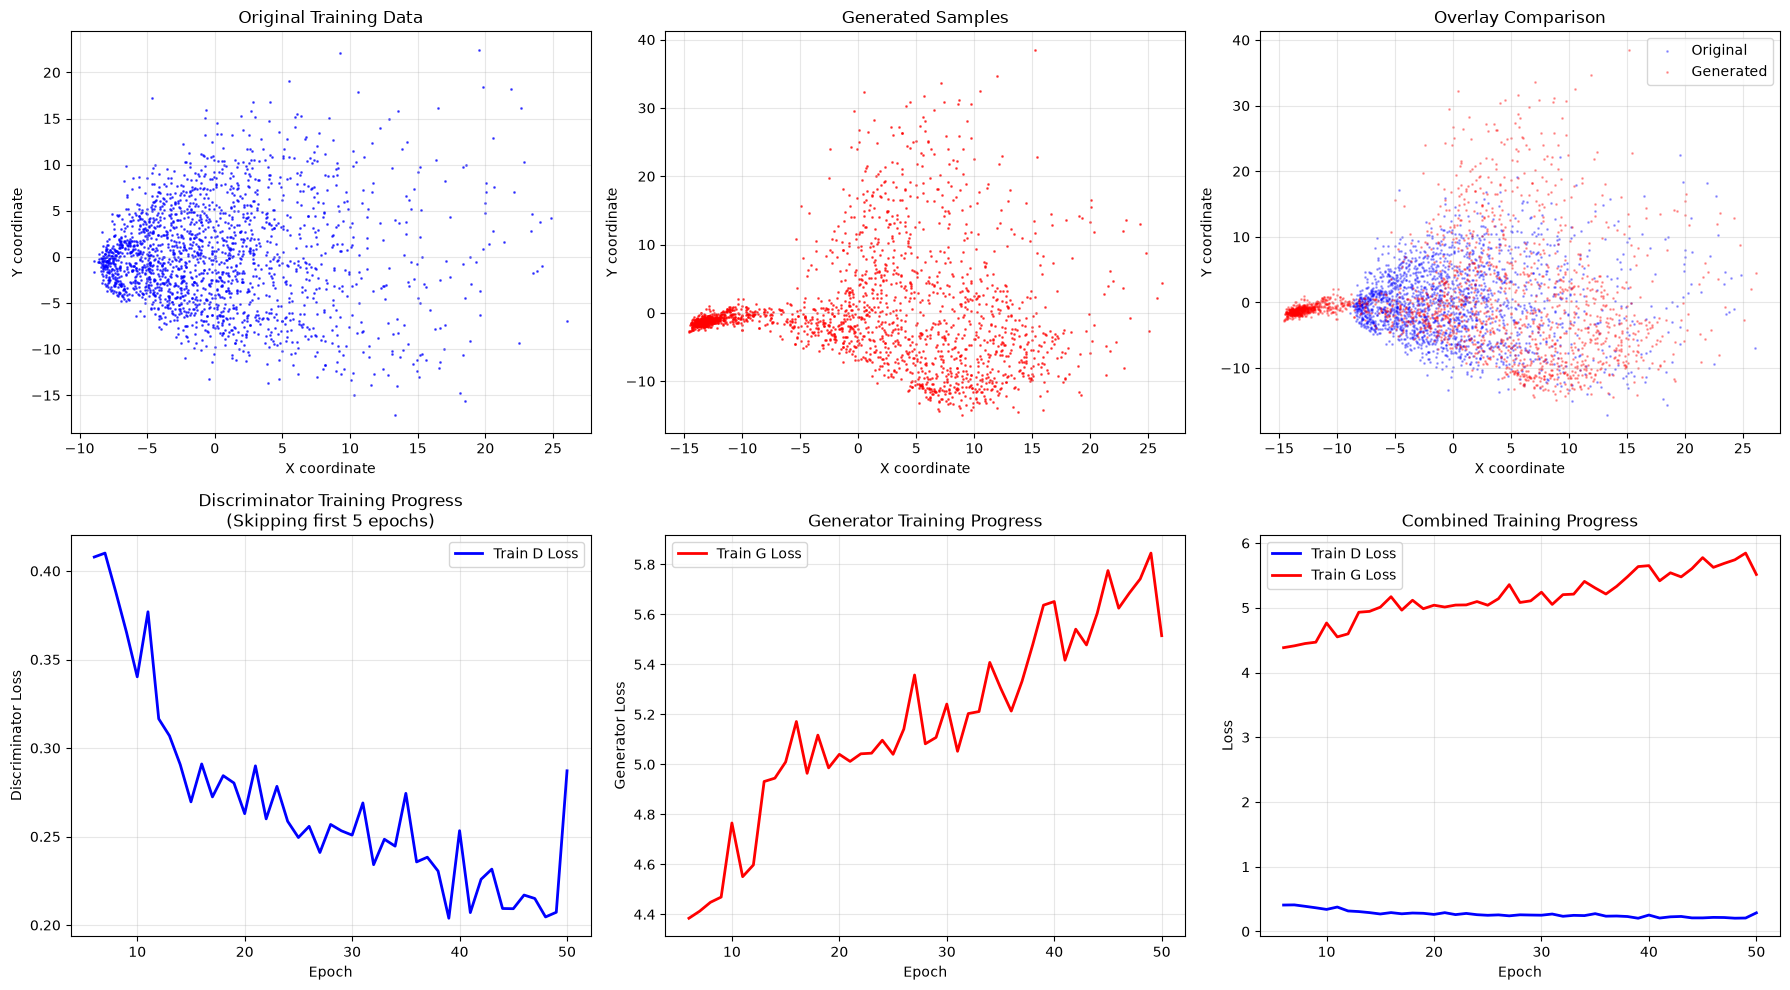

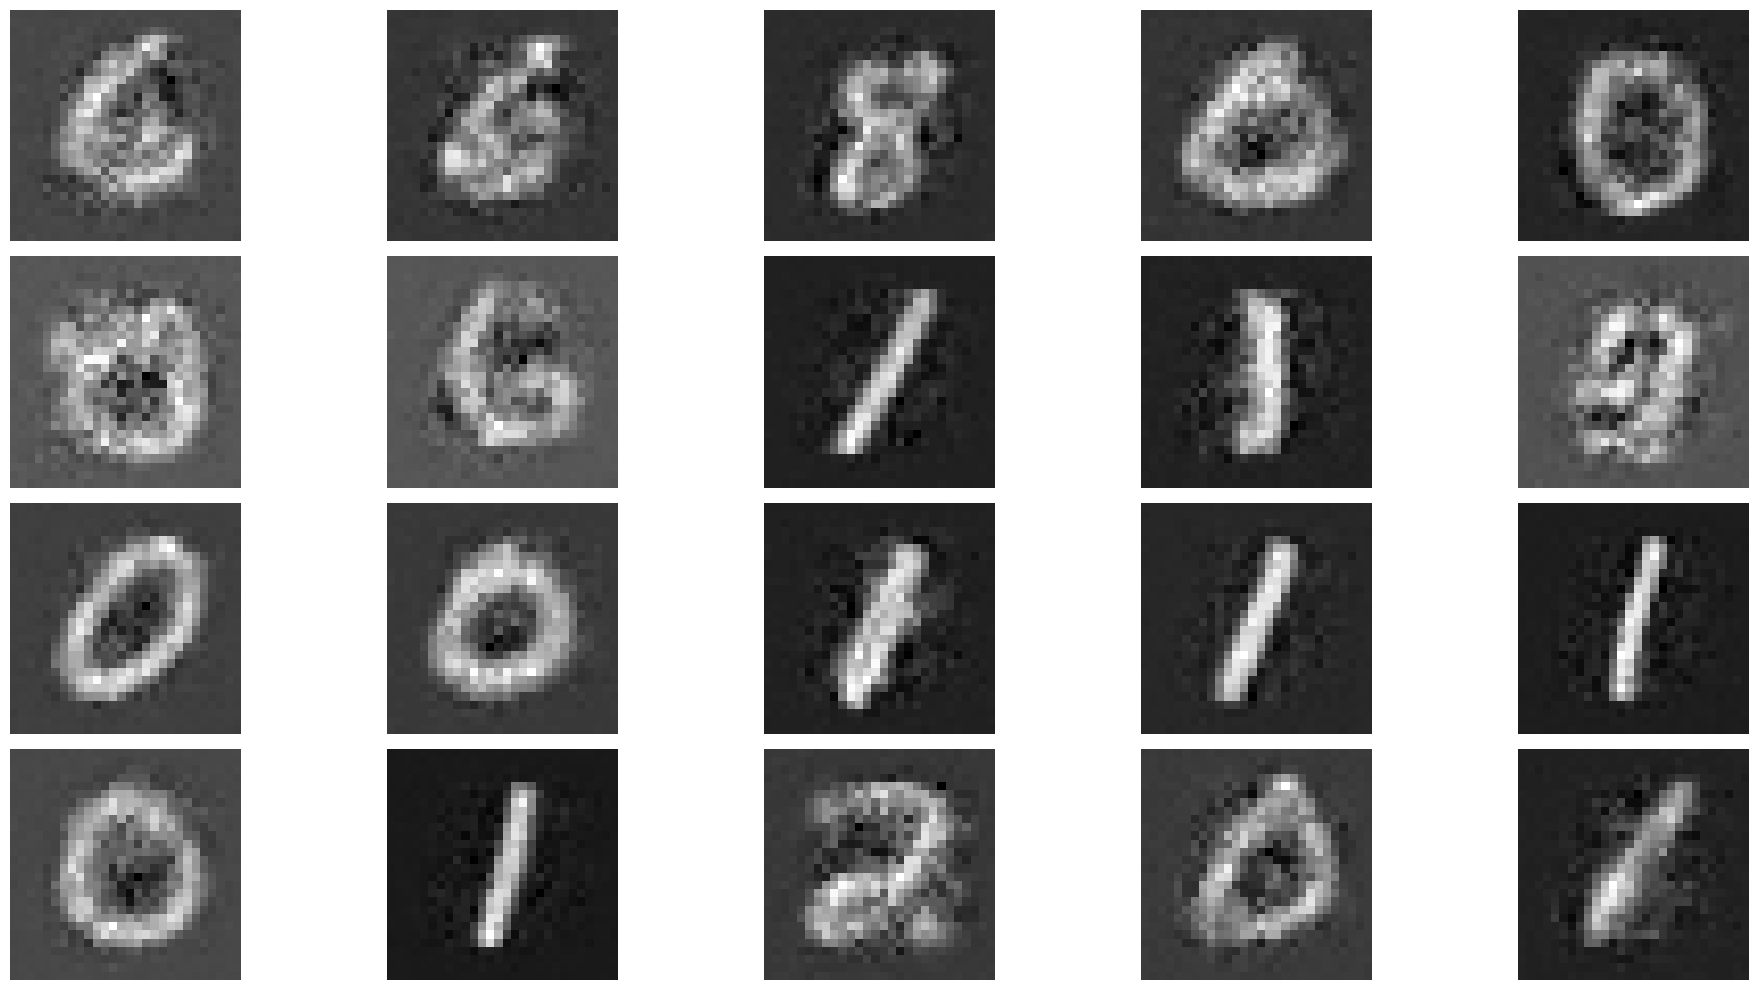

📈 Epoch 50 Summary:
   Train D Loss: 0.2871, Val D Loss: 0.1934
   Train G Loss: 5.5149, Val G Loss: 4.7539

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.127954	G_loss: 4.436862
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.121974	G_loss: 4.752631
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.235425	G_loss: 5.783376
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.110008	G_loss: 6.199002
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.277332	G_loss: 7.488407
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.406903	G_loss: 6.537141
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.148220	G_loss: 4.596166
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.118773	G_loss: 4.611901
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.270842	G_loss: 4.809624
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.175789	G_loss: 6.145630
====> Epoch: 51 Train D_loss: 0.2060, Train G_loss: 5.6118
====> Epoch: 51 Val D_loss: 0.4662, Val G_loss: 5.9937
📈 Epoch 51 Summary:
   Train D Loss: 0.2060, Val D Loss: 0.4662
   Train G Loss: 5.6118

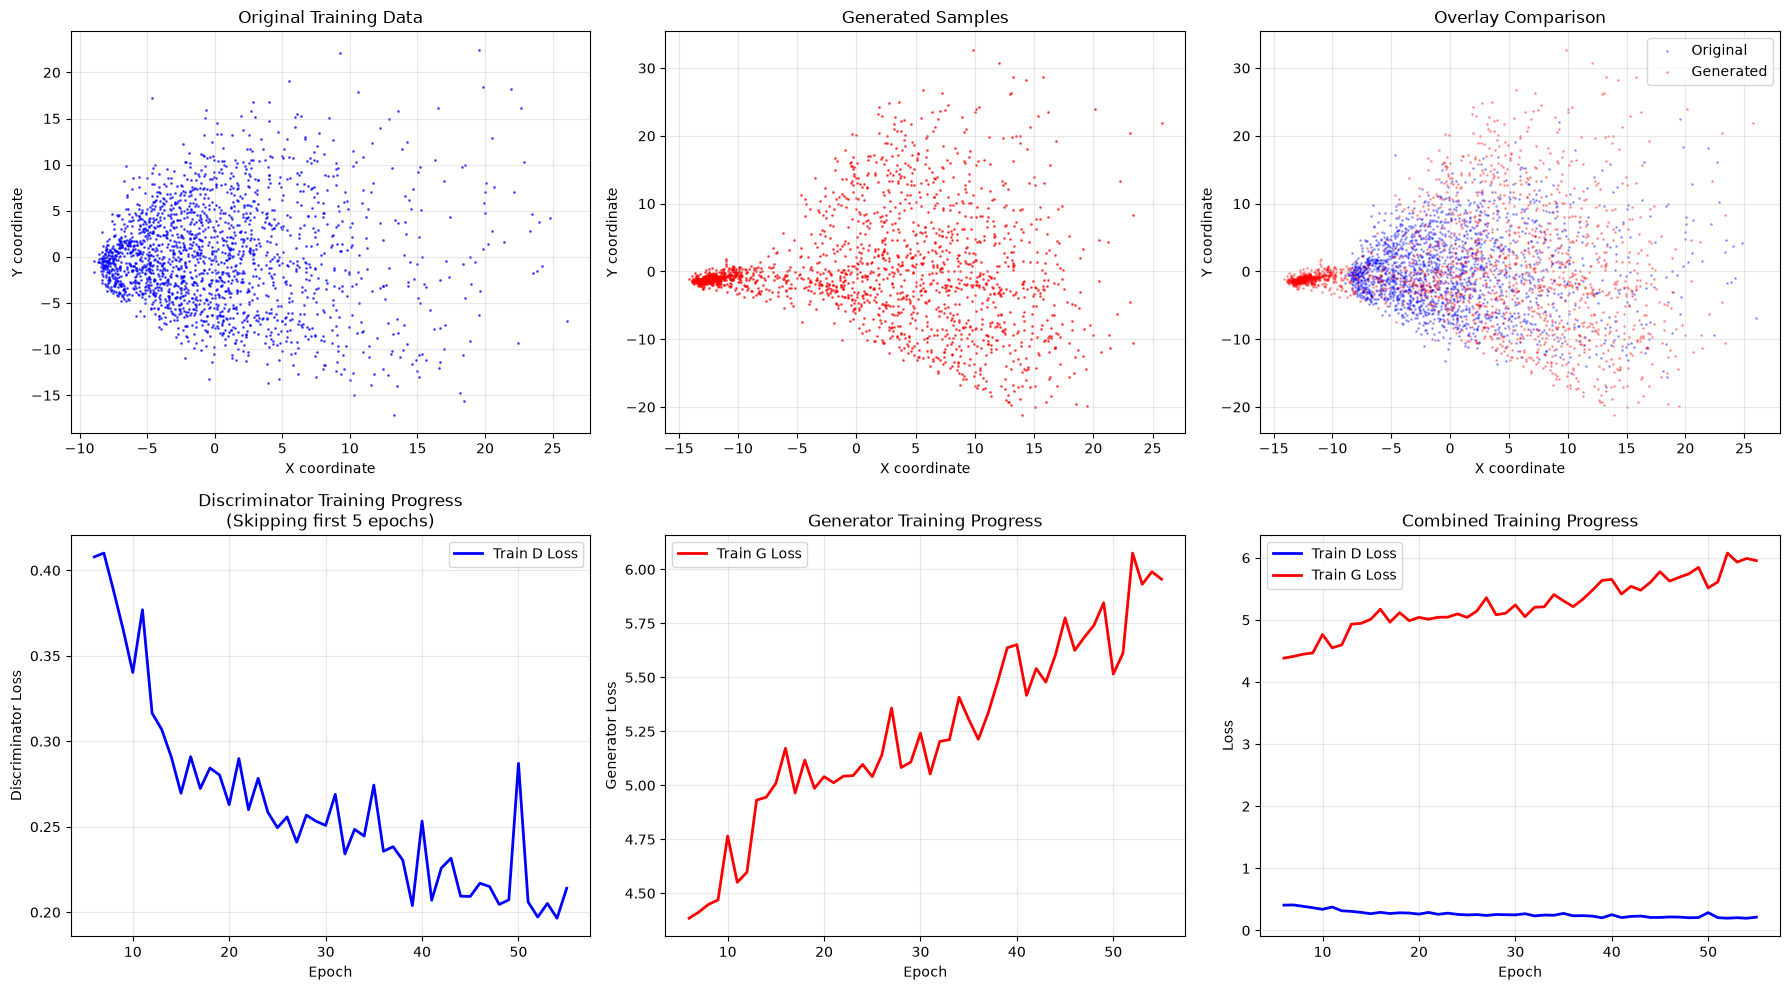

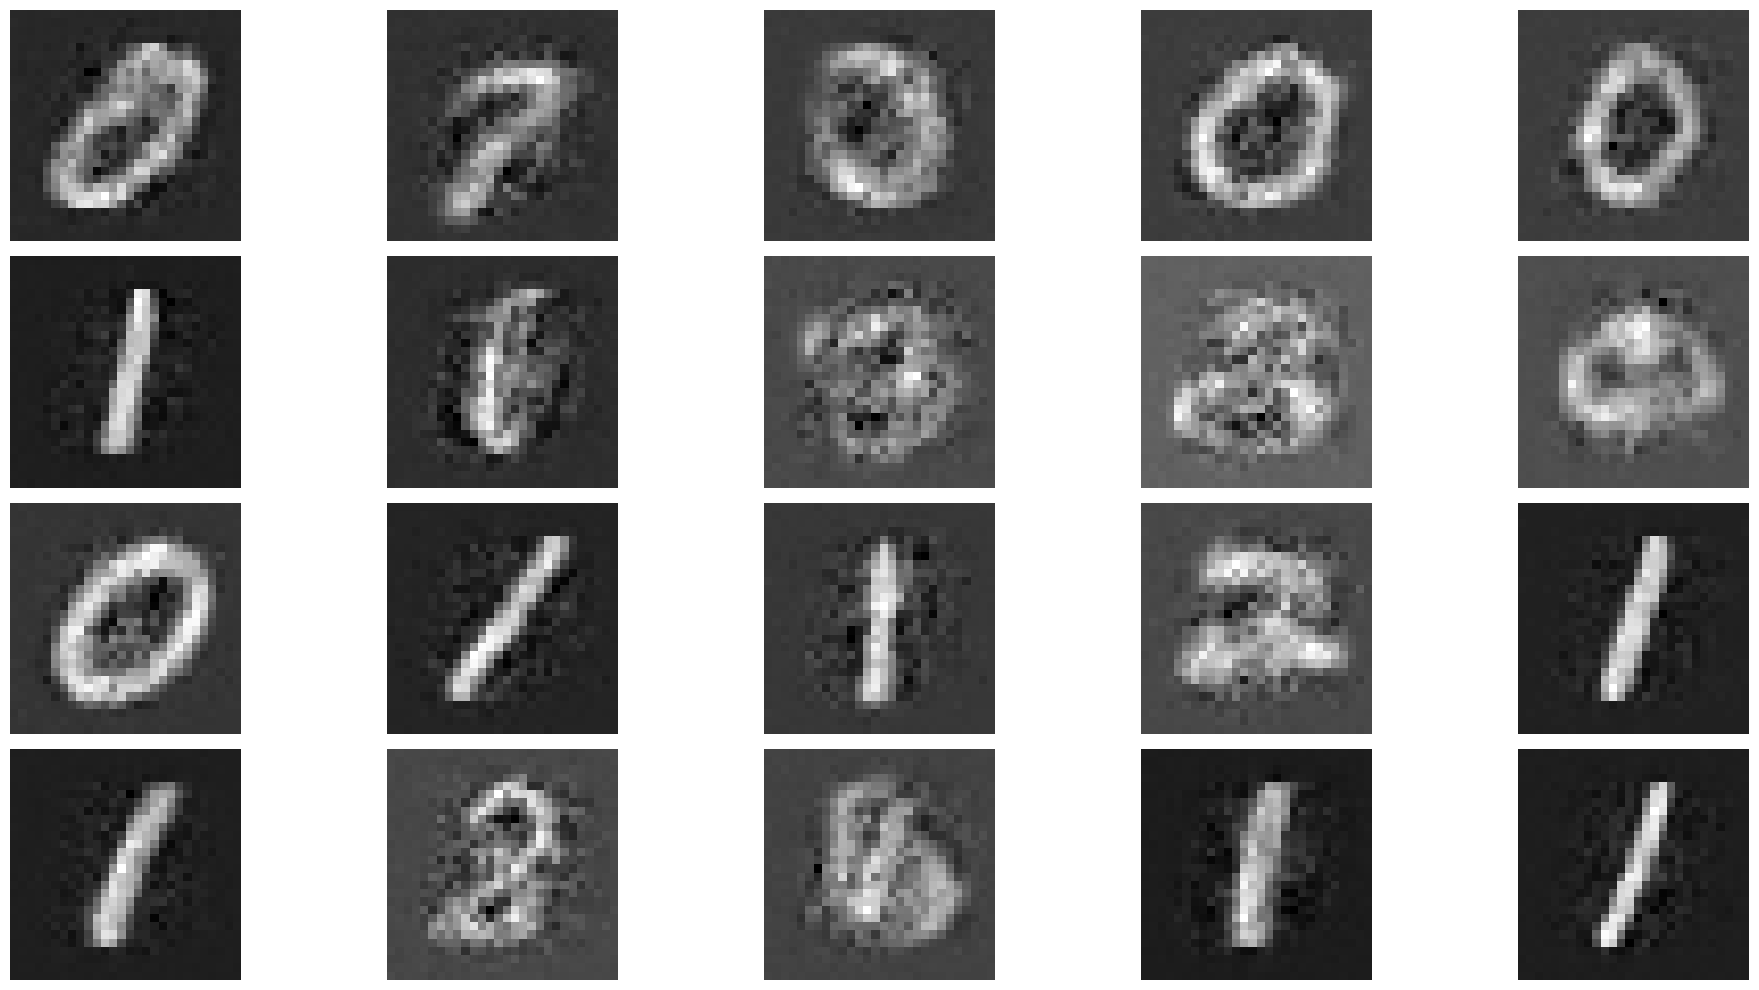

📈 Epoch 55 Summary:
   Train D Loss: 0.2140, Val D Loss: 0.3797
   Train G Loss: 5.9547, Val G Loss: 2.6544

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.269635	G_loss: 4.231859
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.081600	G_loss: 4.091296
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.128413	G_loss: 4.878778
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.114605	G_loss: 7.037419
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.189452	G_loss: 6.170327
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.146183	G_loss: 6.657730
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.073262	G_loss: 5.975511
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.143931	G_loss: 6.515706
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.172140	G_loss: 6.035116
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.201850	G_loss: 4.194478
====> Epoch: 56 Train D_loss: 0.2003, Train G_loss: 6.1635
====> Epoch: 56 Val D_loss: 0.2699, Val G_loss: 3.8233
📈 Epoch 56 Summary:
   Train D Loss: 0.2003, Val D Loss: 0.2699
   Train G Loss: 6.1635

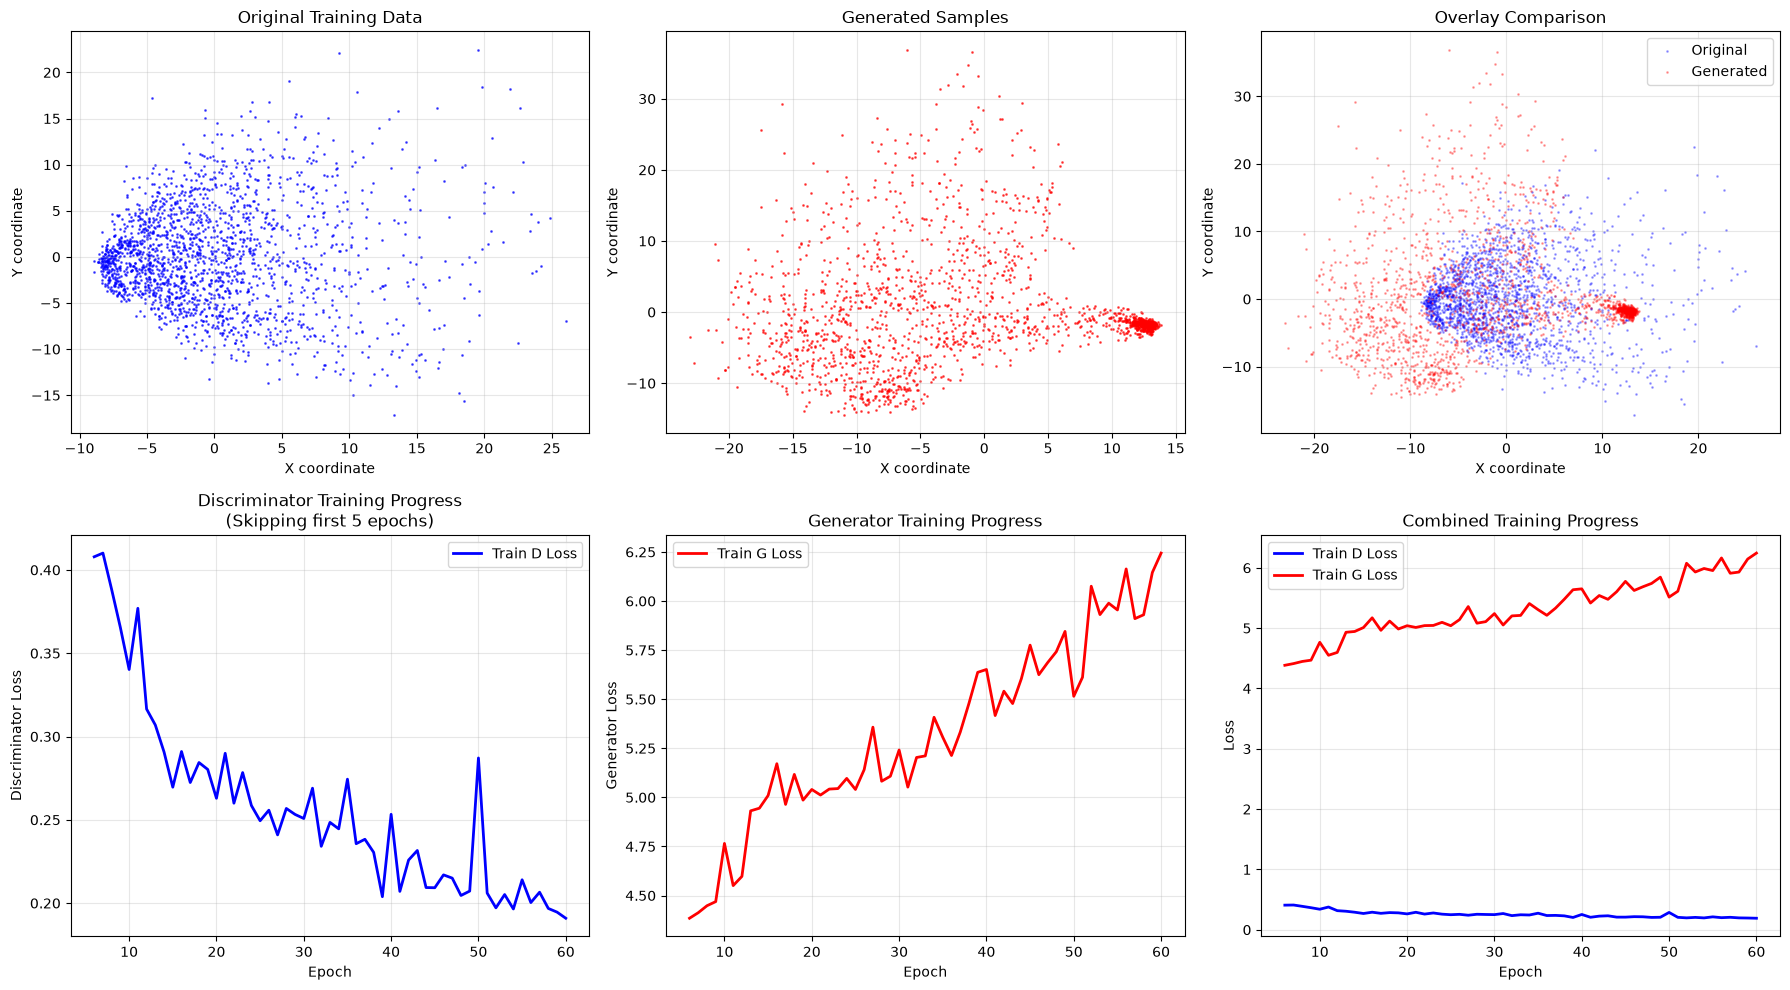

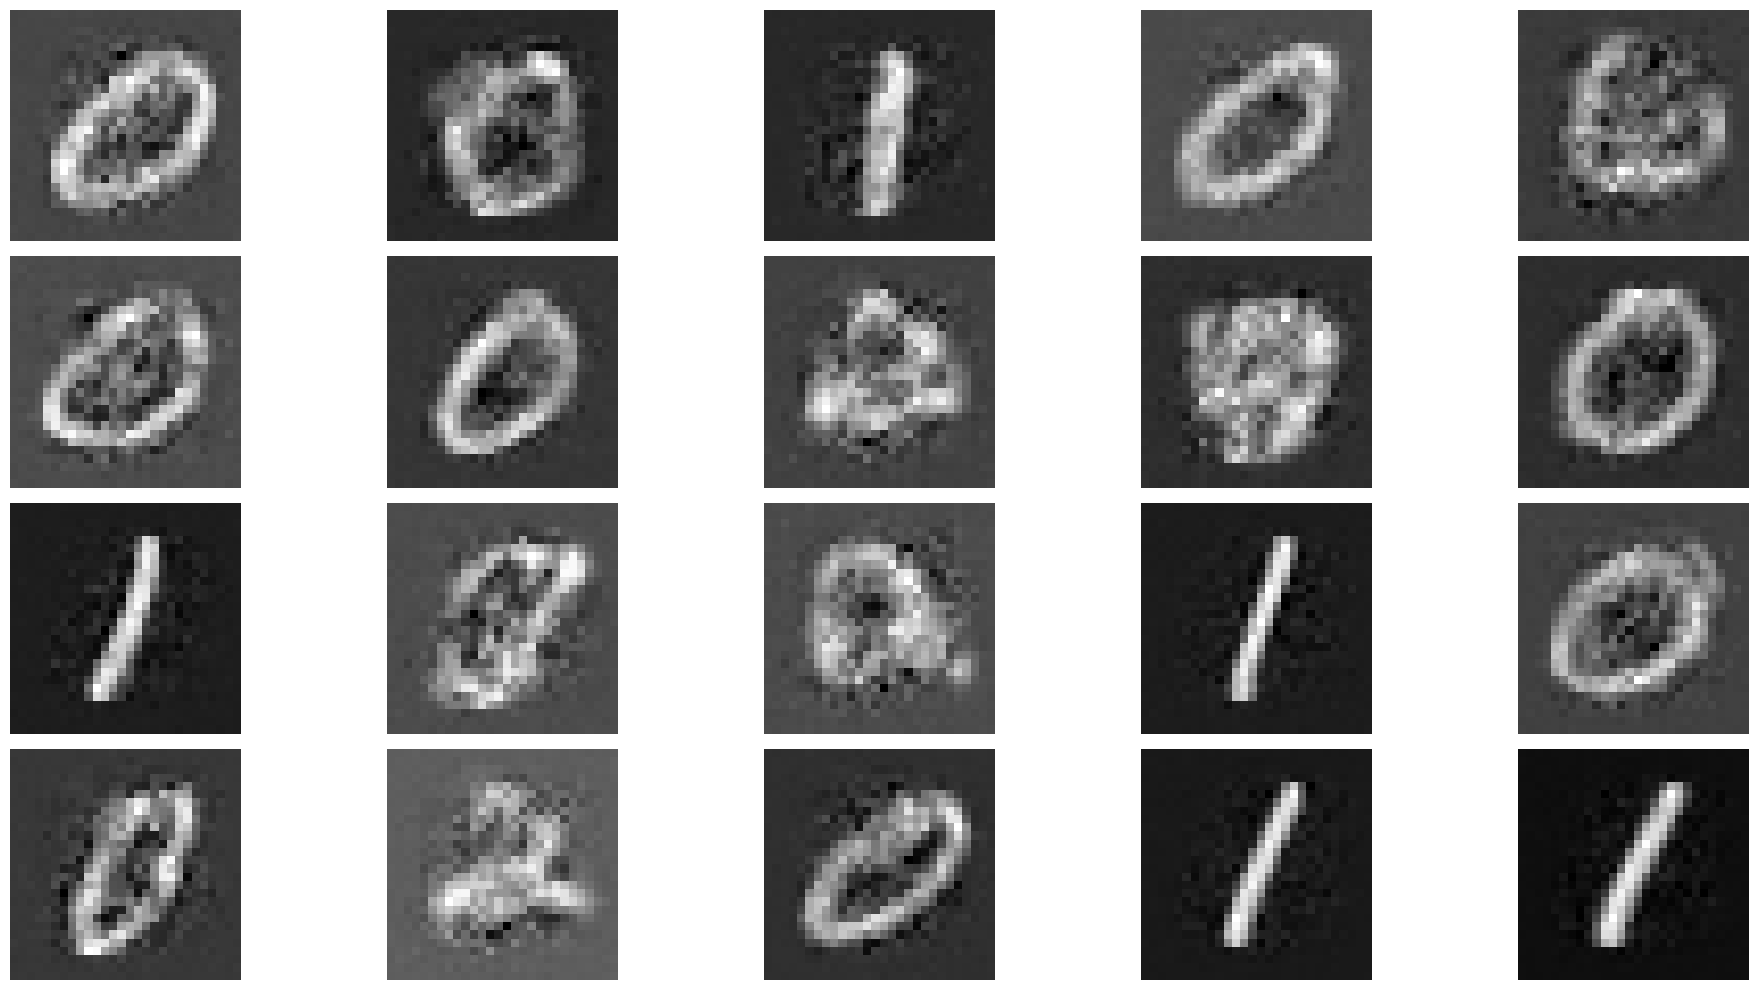

📈 Epoch 60 Summary:
   Train D Loss: 0.1909, Val D Loss: 0.3941
   Train G Loss: 6.2443, Val G Loss: 5.0346

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.450476	G_loss: 4.228924
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.219742	G_loss: 5.050174
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.195265	G_loss: 5.048468
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.160139	G_loss: 4.265269
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.075462	G_loss: 6.021139
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.350724	G_loss: 4.343395
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.231596	G_loss: 4.659555
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.111646	G_loss: 6.609541
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.093404	G_loss: 5.038801
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.115870	G_loss: 5.759356
====> Epoch: 61 Train D_loss: 0.2034, Train G_loss: 6.1465
====> Epoch: 61 Val D_loss: 0.2349, Val G_loss: 5.6965
📈 Epoch 61 Summary:
   Train D Loss: 0.2034, Val D Loss: 0.2349
   Train G Loss: 6.1465

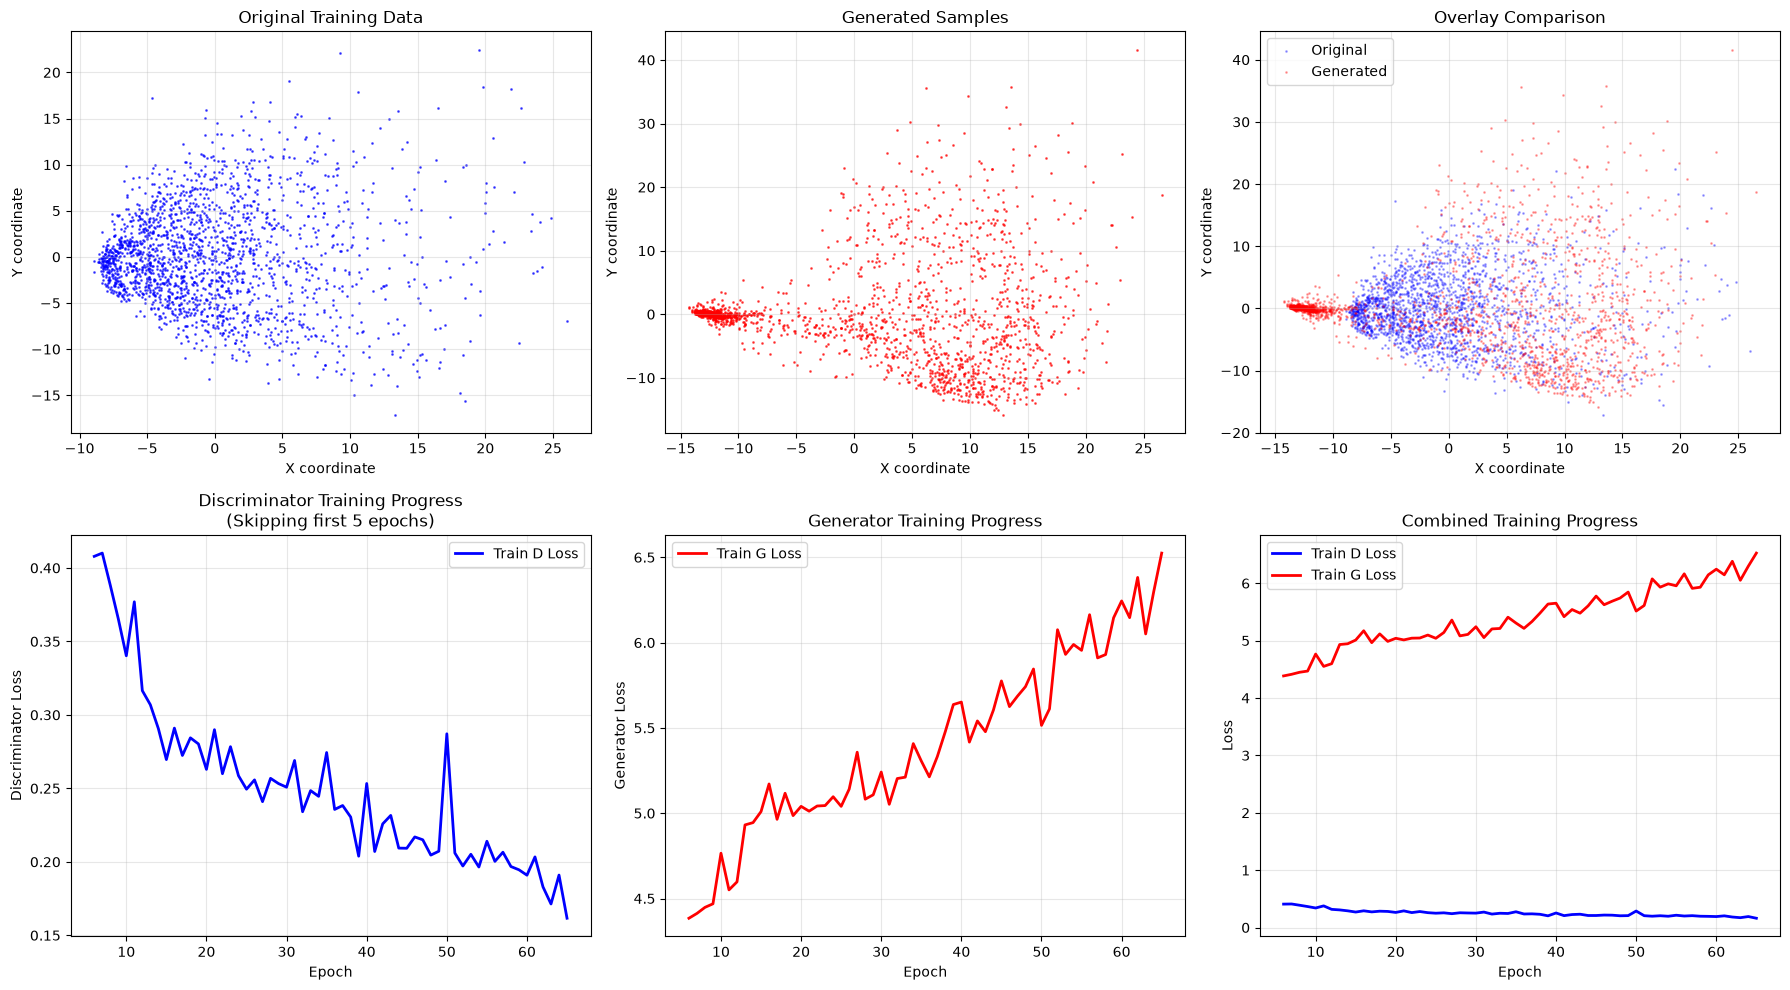

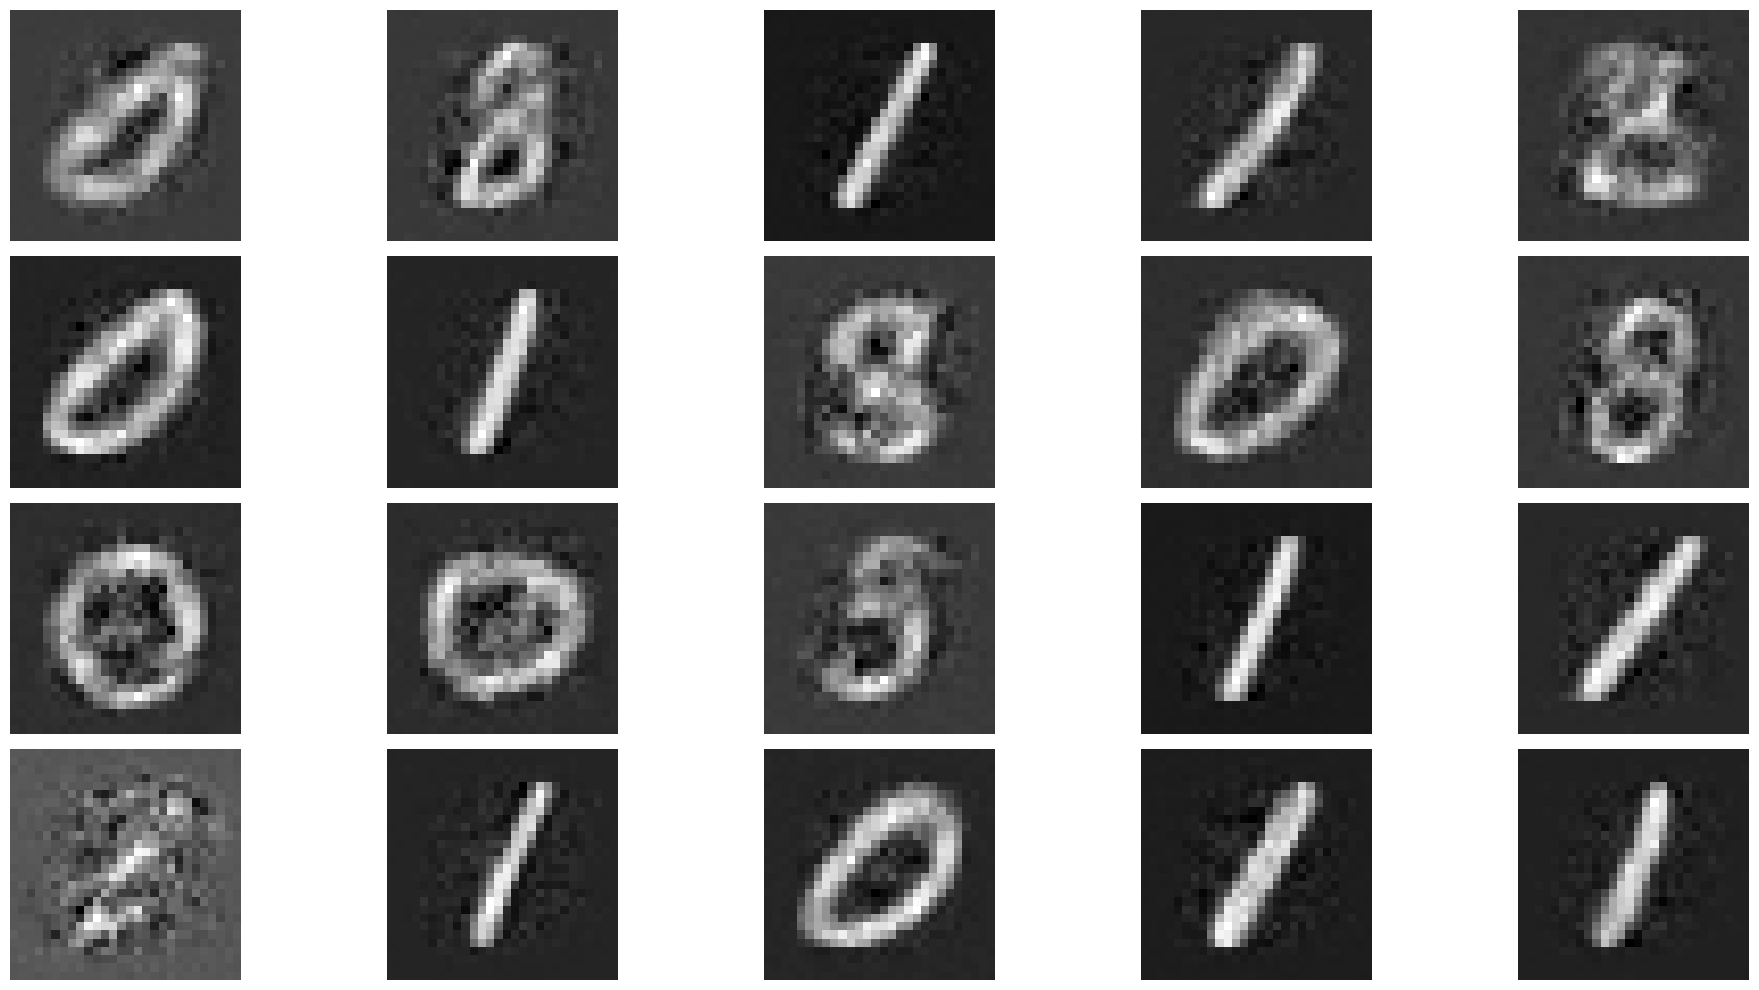

📈 Epoch 65 Summary:
   Train D Loss: 0.1616, Val D Loss: 0.1641
   Train G Loss: 6.5248, Val G Loss: 5.0399

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.105103	G_loss: 6.406964
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.228252	G_loss: 4.642763
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.785967	G_loss: 3.340176
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.257517	G_loss: 9.922339
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.317921	G_loss: 10.405622
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.158847	G_loss: 7.259293
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.146203	G_loss: 5.288587
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.142829	G_loss: 4.565124
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.130350	G_loss: 5.392964
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.148135	G_loss: 5.808066
====> Epoch: 66 Train D_loss: 0.1769, Train G_loss: 6.3207
====> Epoch: 66 Val D_loss: 0.1032, Val G_loss: 6.4196
📈 Epoch 66 Summary:
   Train D Loss: 0.1769, Val D Loss: 0.1032
   Train G Loss: 6.320

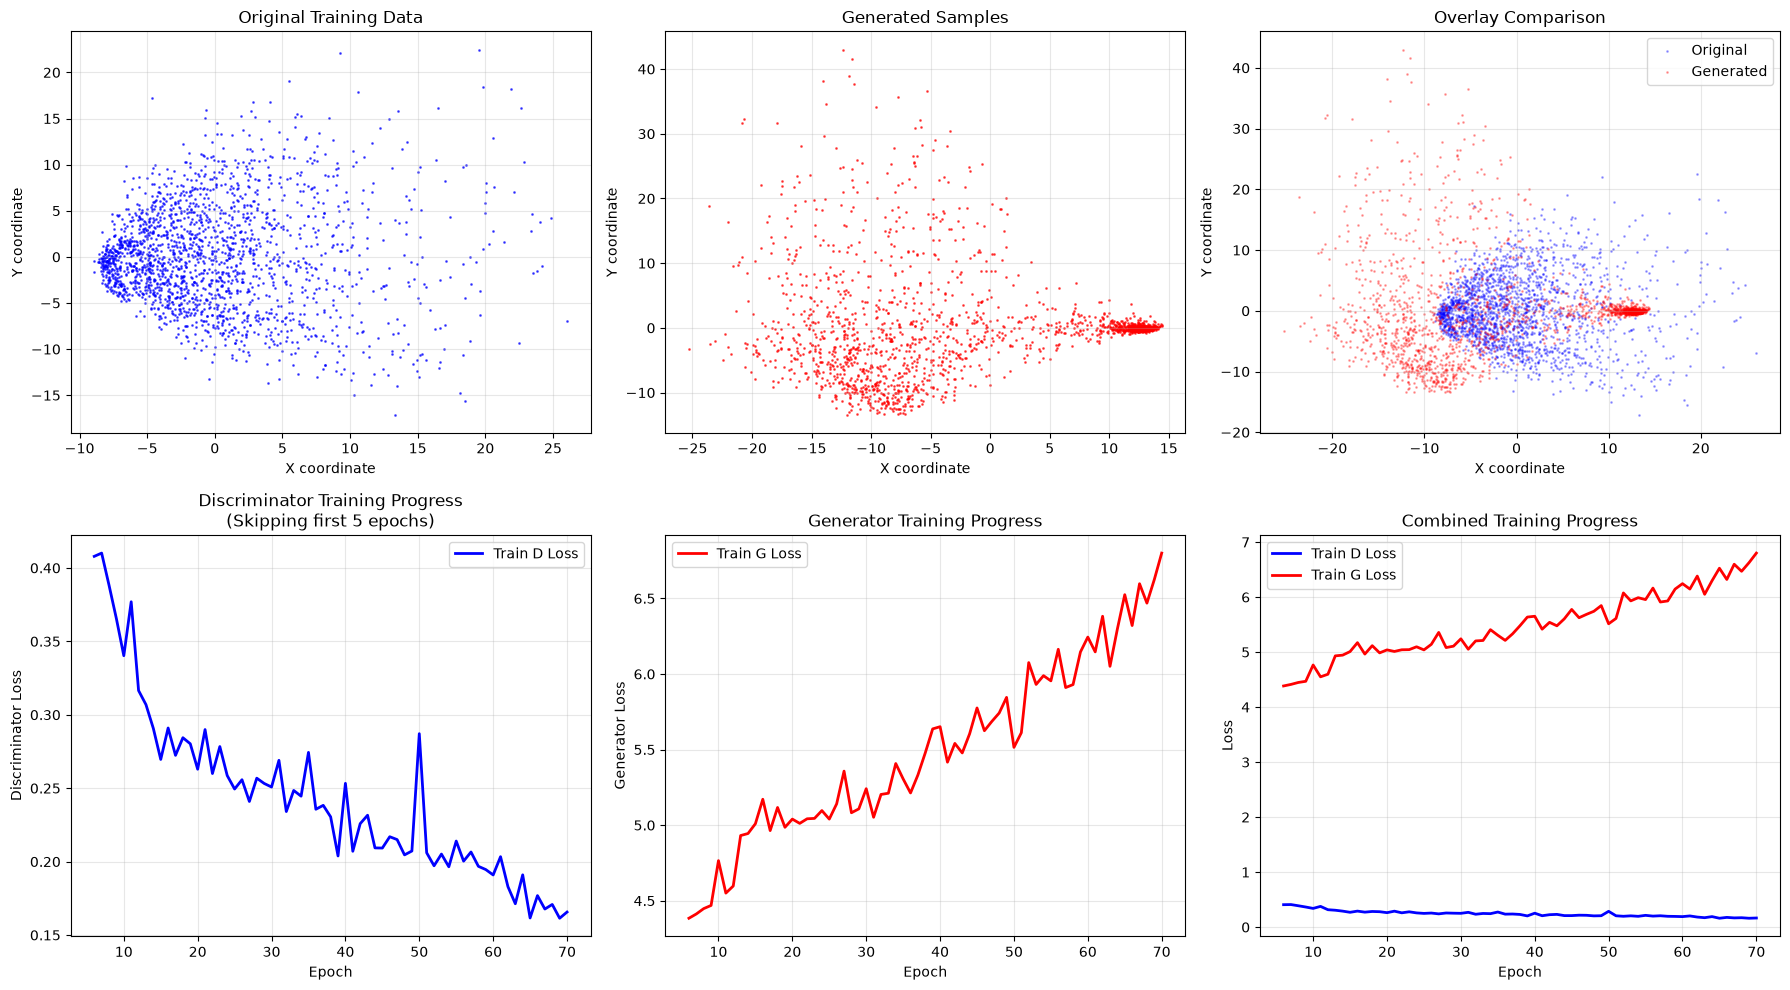

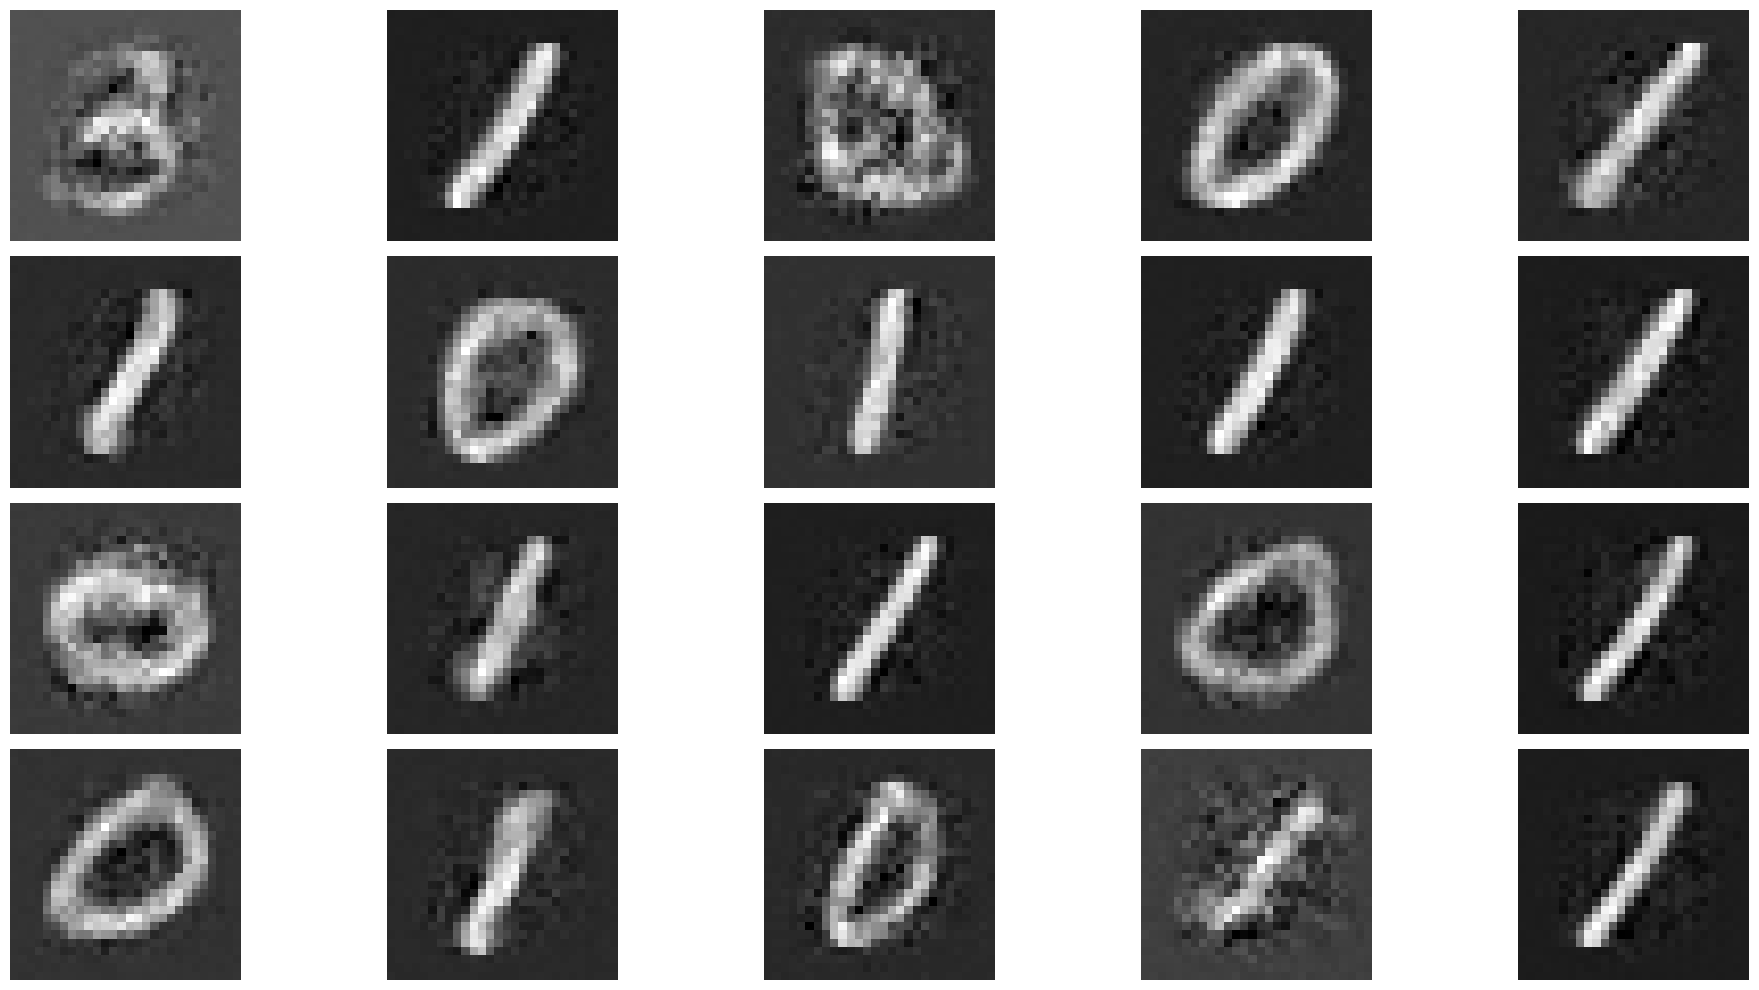

📈 Epoch 70 Summary:
   Train D Loss: 0.1657, Val D Loss: 0.2174
   Train G Loss: 6.7999, Val G Loss: 4.9529

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.216746	G_loss: 6.544338
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.140970	G_loss: 3.837715
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.120646	G_loss: 5.904418
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.195850	G_loss: 6.236035
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.181403	G_loss: 5.801987
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.029430	G_loss: 6.888217
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.079012	G_loss: 6.149123
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.135137	G_loss: 8.311232
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.051941	G_loss: 5.514617
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.166600	G_loss: 5.741767
====> Epoch: 71 Train D_loss: 0.1657, Train G_loss: 6.4002
====> Epoch: 71 Val D_loss: 0.1140, Val G_loss: 7.7575
📈 Epoch 71 Summary:
   Train D Loss: 0.1657, Val D Loss: 0.1140
   Train G Loss: 6.4002

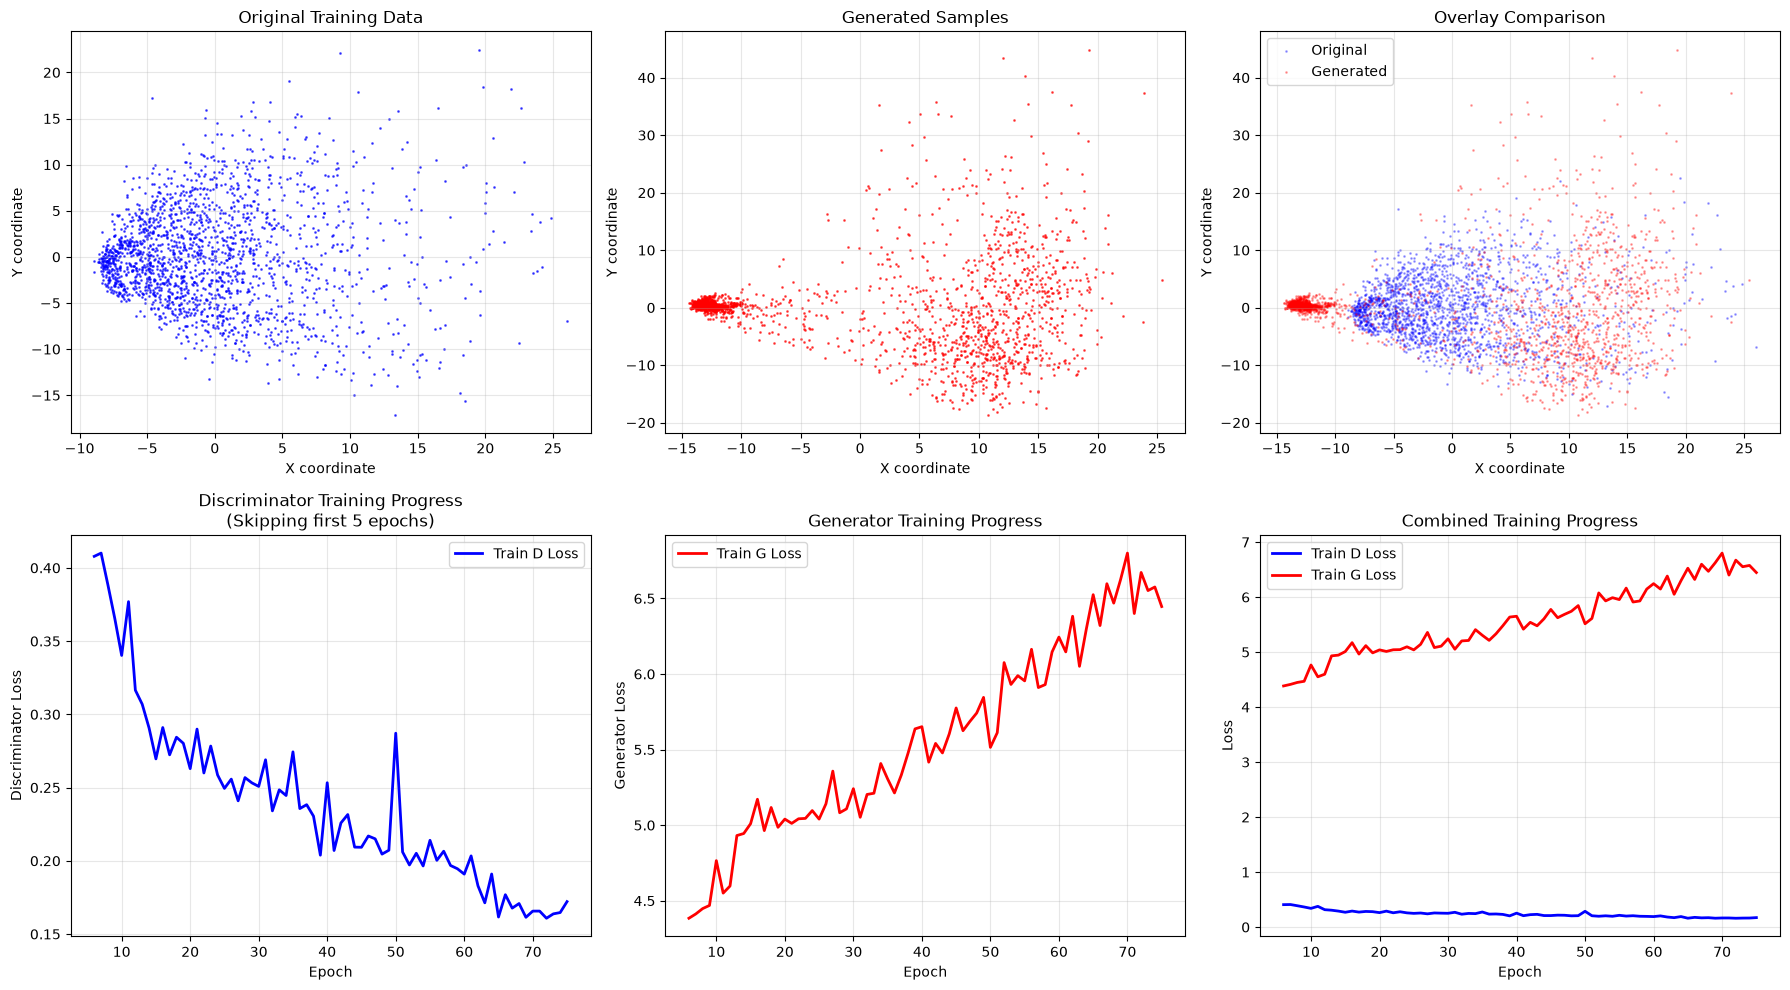

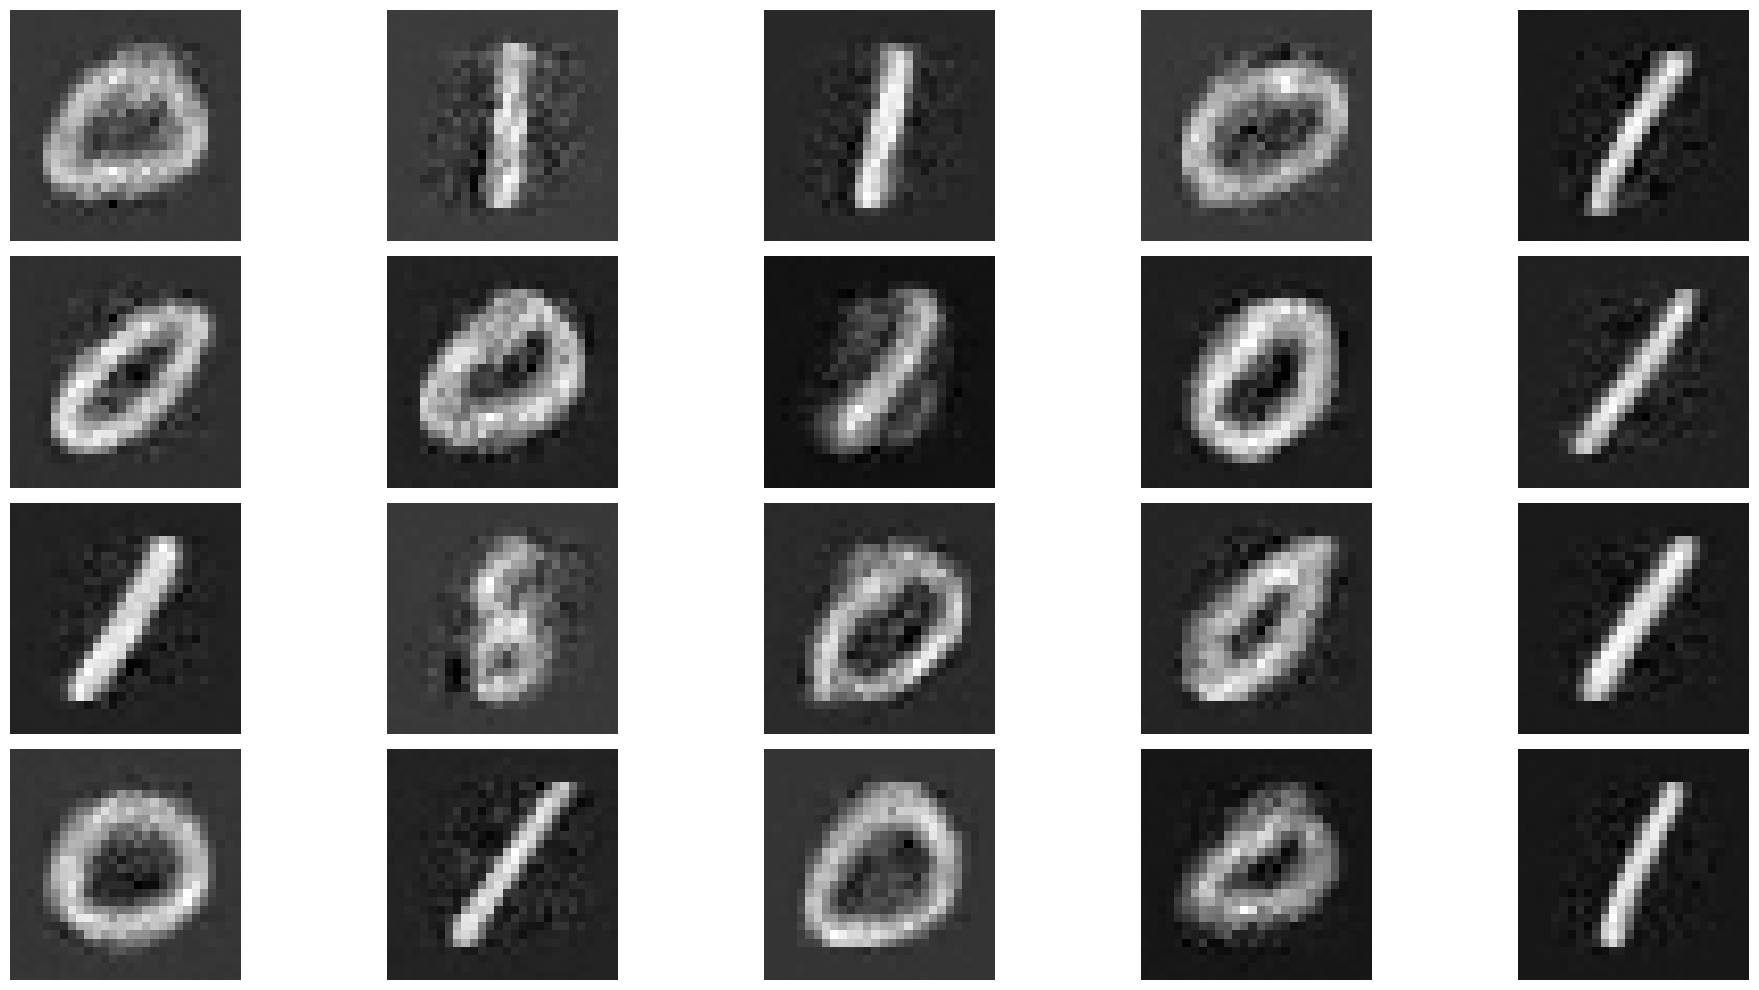

📈 Epoch 75 Summary:
   Train D Loss: 0.1721, Val D Loss: 0.1388
   Train G Loss: 6.4462, Val G Loss: 7.0322

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.089316	G_loss: 6.810445
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.076415	G_loss: 7.269614
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.297017	G_loss: 6.751908
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.157238	G_loss: 5.769511
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.111935	G_loss: 5.995405
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.034111	G_loss: 5.991085
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.134615	G_loss: 6.757610
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.056122	G_loss: 5.649078
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.092017	G_loss: 5.672366
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.149069	G_loss: 7.693840
====> Epoch: 76 Train D_loss: 0.1418, Train G_loss: 6.6489
====> Epoch: 76 Val D_loss: 0.2658, Val G_loss: 4.1383
📈 Epoch 76 Summary:
   Train D Loss: 0.1418, Val D Loss: 0.2658
   Train G Loss: 6.6489

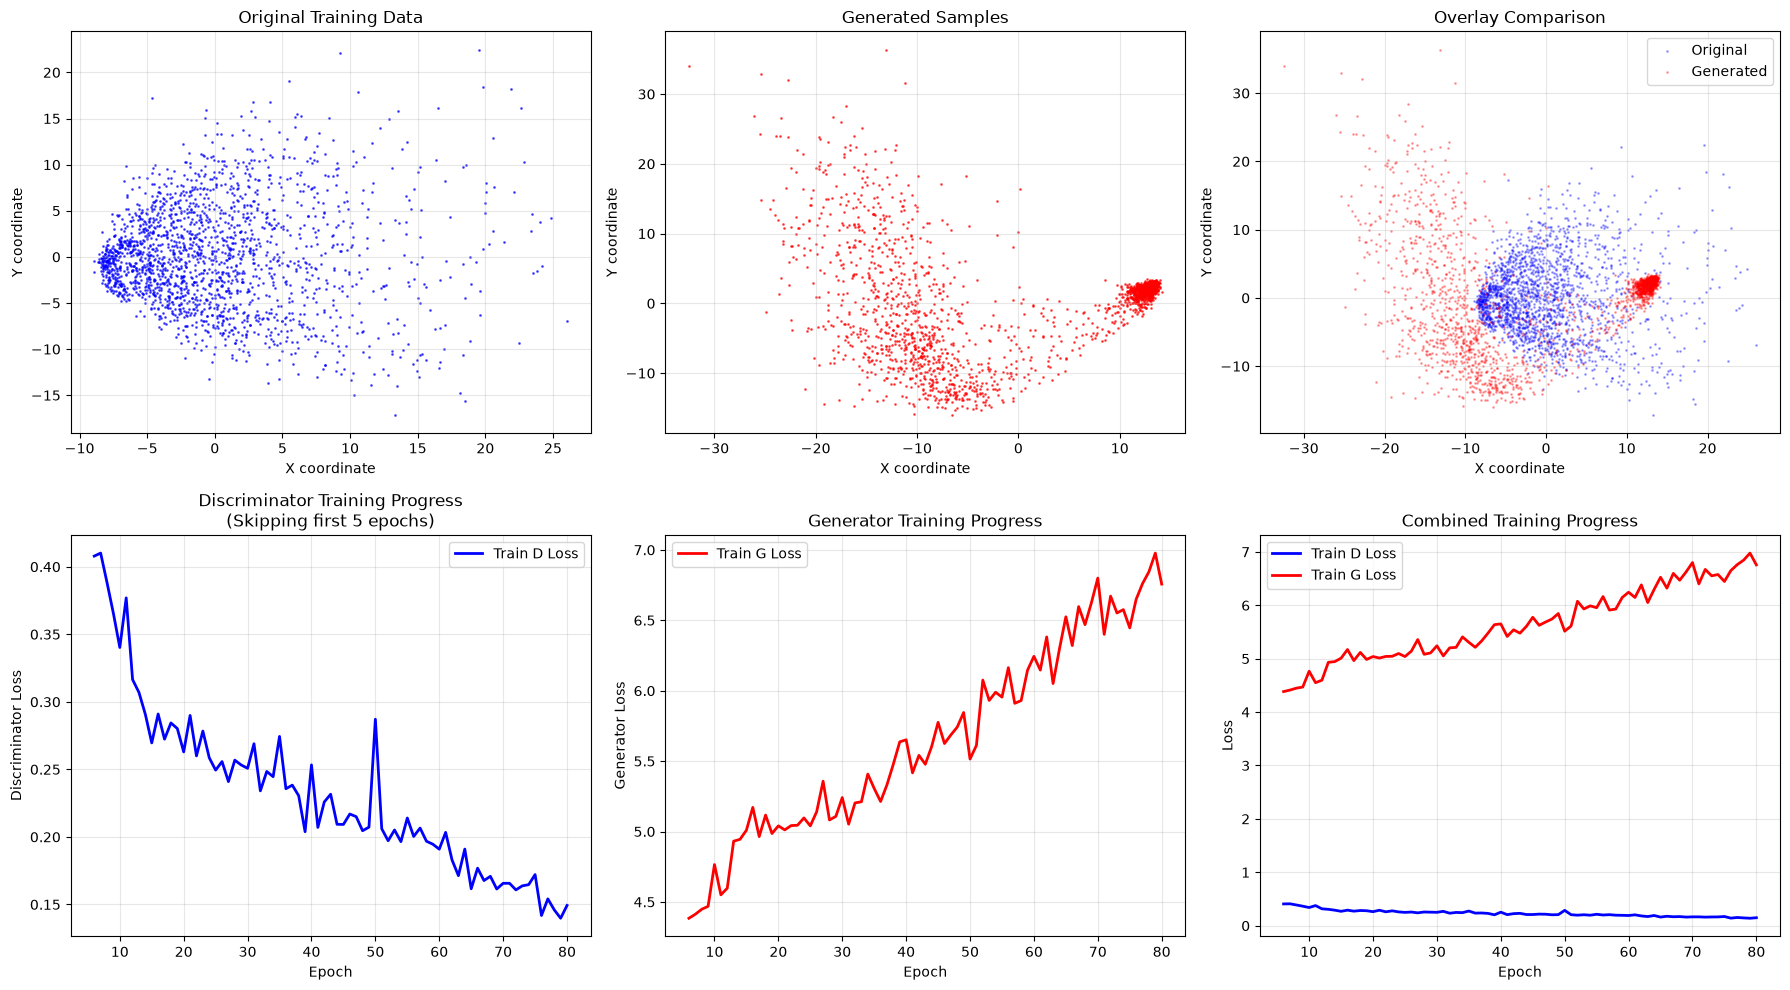

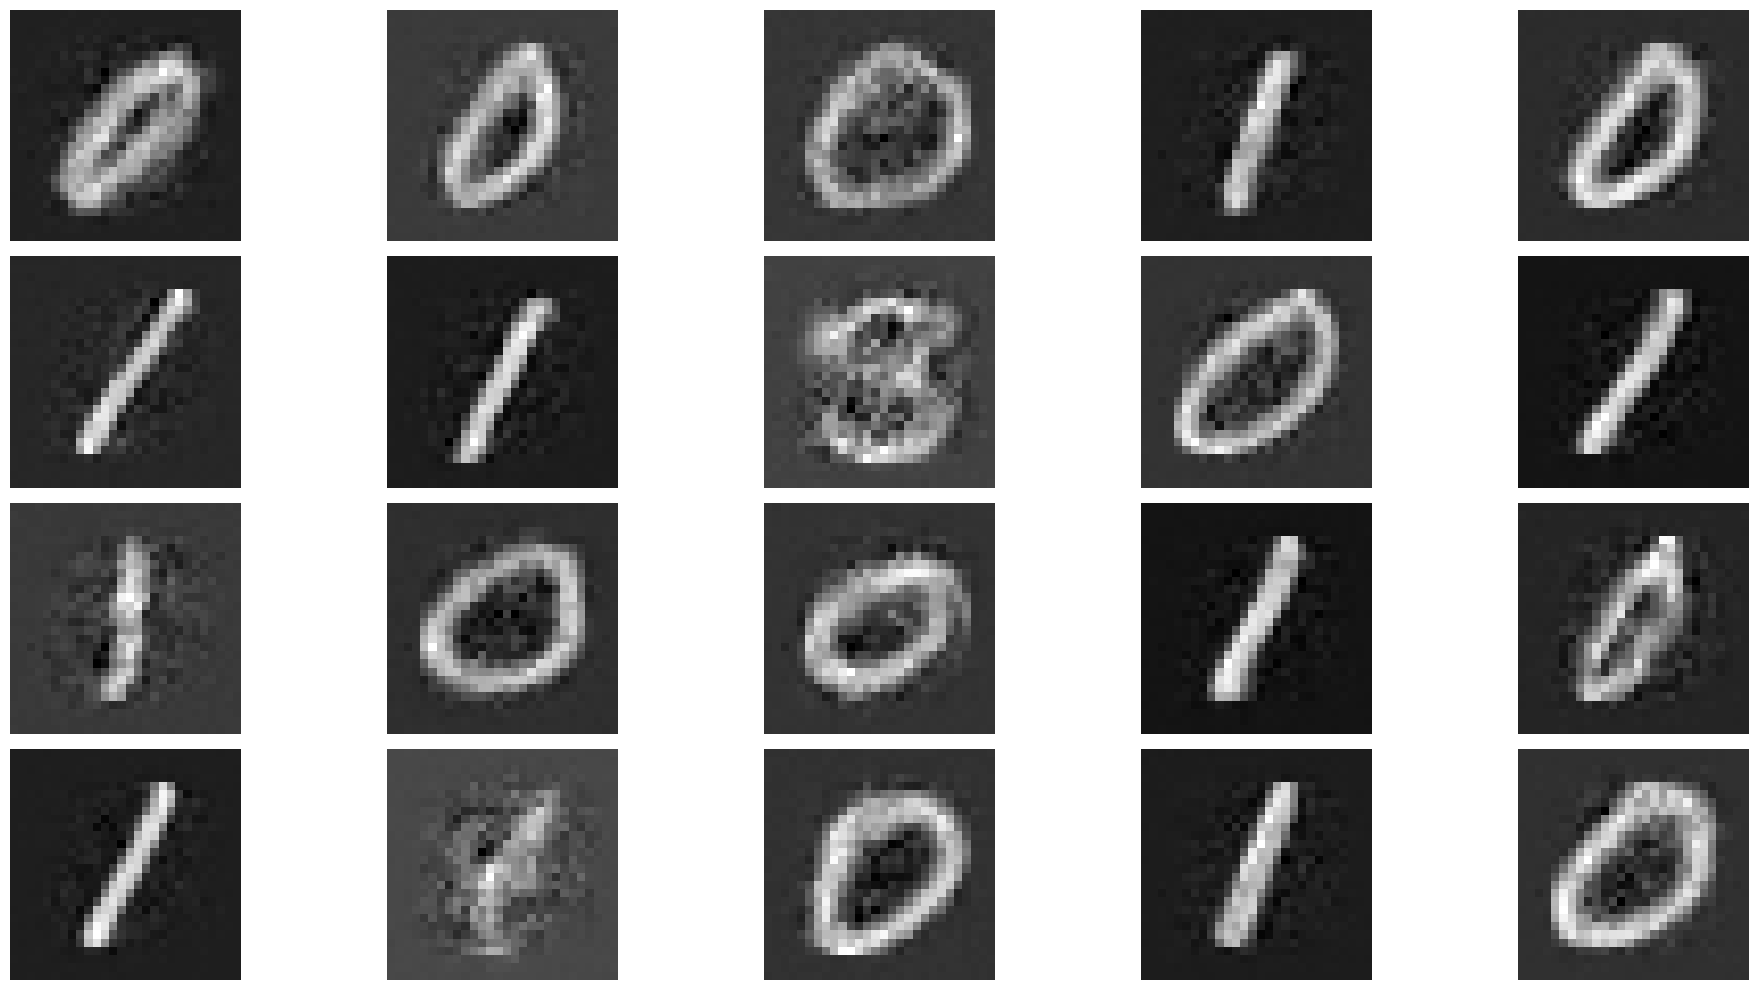

📈 Epoch 80 Summary:
   Train D Loss: 0.1493, Val D Loss: 0.2202
   Train G Loss: 6.7571, Val G Loss: 3.8342

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.261954	G_loss: 7.778552
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.064885	G_loss: 7.022962
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.104214	G_loss: 4.436917
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.112668	G_loss: 7.020932
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.121256	G_loss: 6.903925
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.153886	G_loss: 6.079917
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.046030	G_loss: 7.518401
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.251403	G_loss: 4.340675
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.097906	G_loss: 6.889946
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.183582	G_loss: 5.985777
====> Epoch: 81 Train D_loss: 0.1325, Train G_loss: 7.0678
====> Epoch: 81 Val D_loss: 0.2193, Val G_loss: 5.8629
📈 Epoch 81 Summary:
   Train D Loss: 0.1325, Val D Loss: 0.2193
   Train G Loss: 7.0678

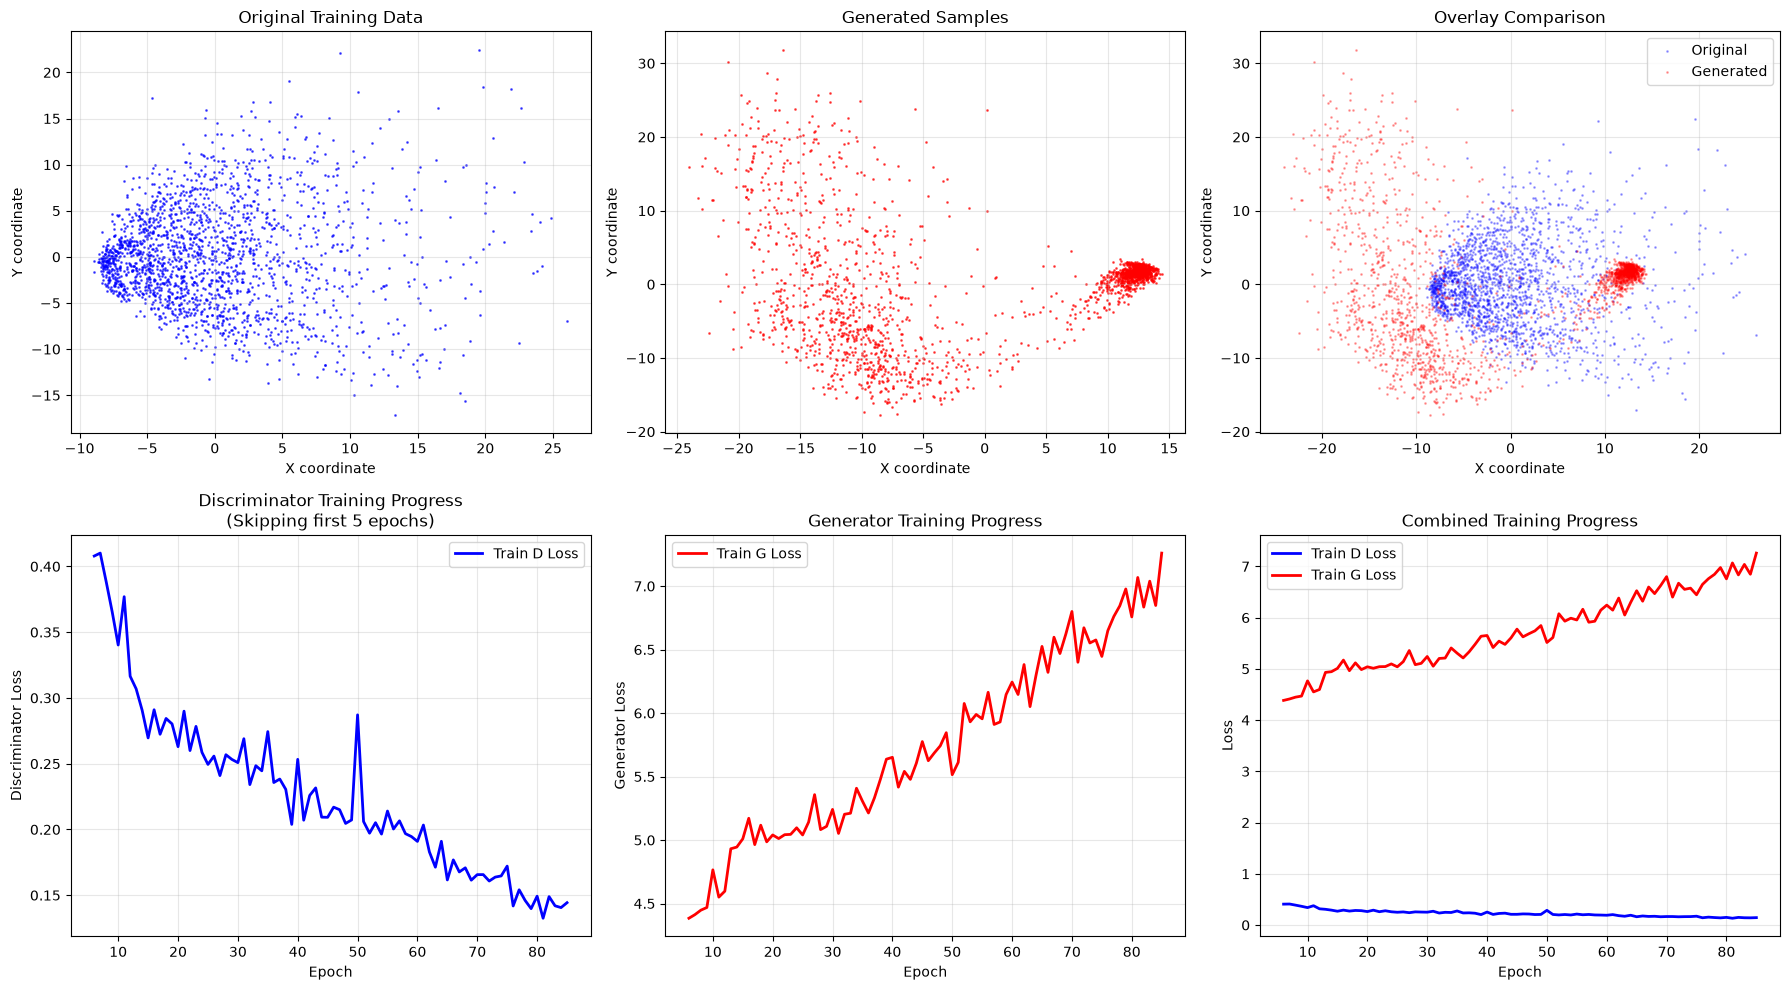

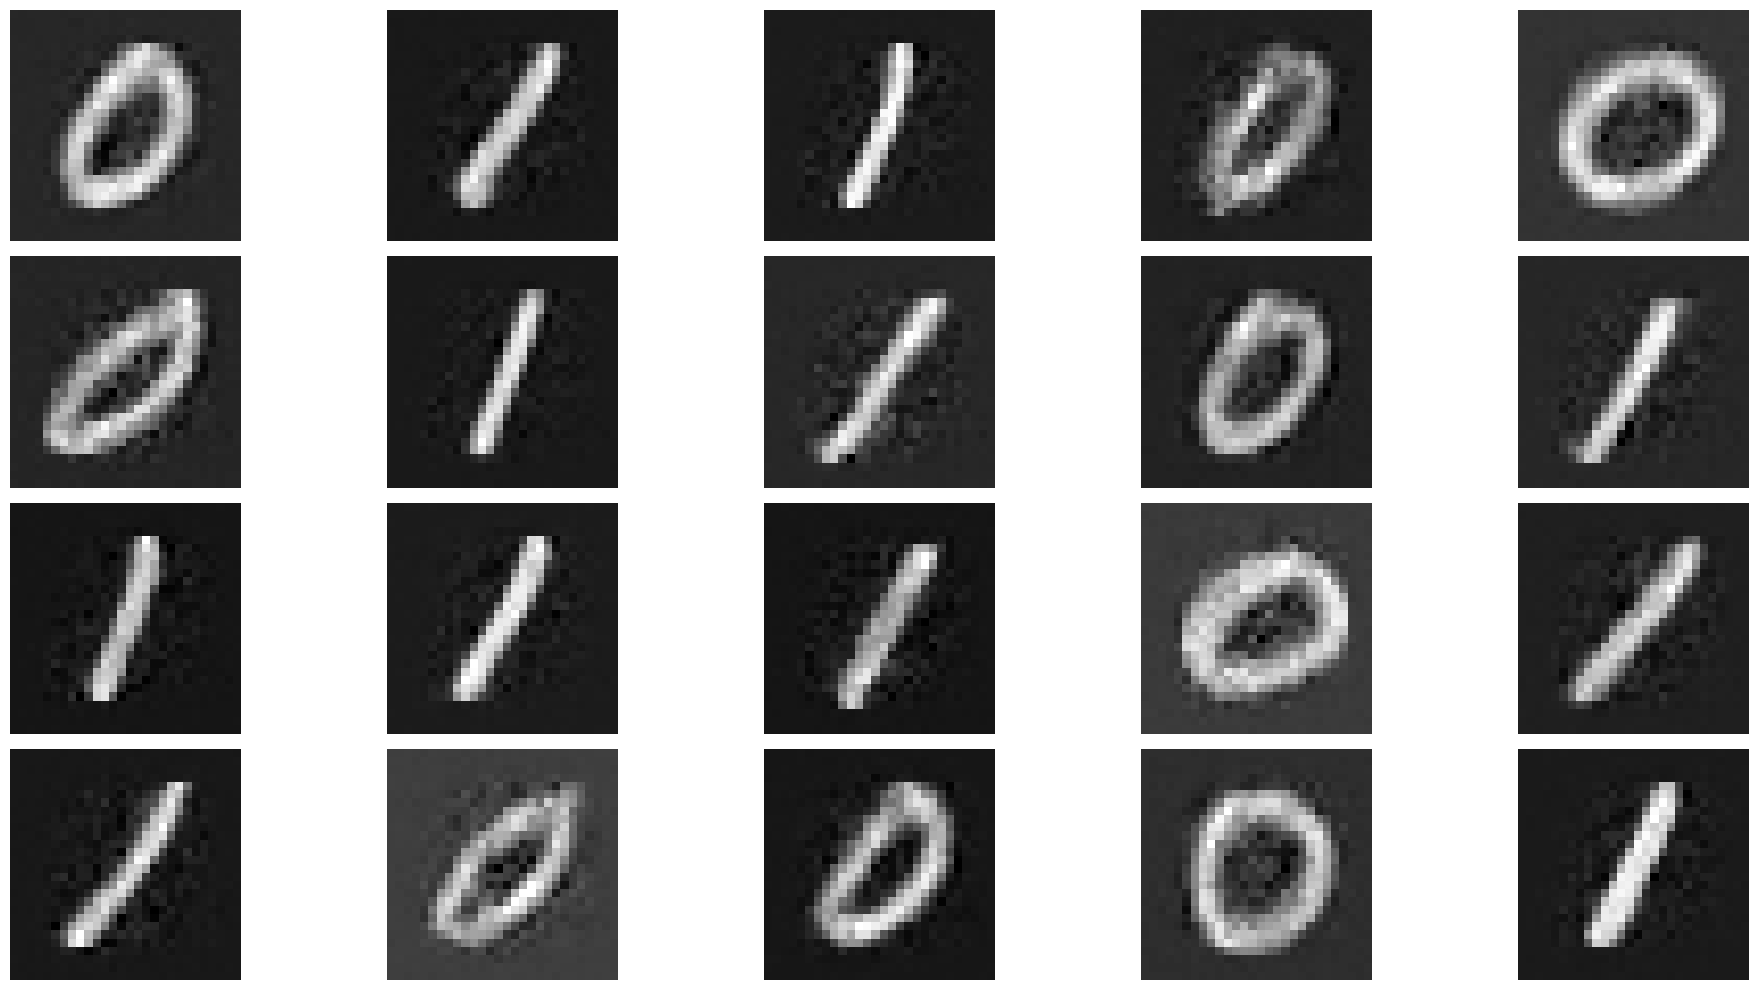

📈 Epoch 85 Summary:
   Train D Loss: 0.1443, Val D Loss: 0.1647
   Train G Loss: 7.2598, Val G Loss: 4.5067

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.083309	G_loss: 6.265687
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.284254	G_loss: 6.927246
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.171811	G_loss: 5.351297
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.091933	G_loss: 6.023745
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.056681	G_loss: 8.727707
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.141070	G_loss: 11.114644
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.234600	G_loss: 9.912068
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.089811	G_loss: 6.692021
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.072038	G_loss: 15.070526
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.106573	G_loss: 5.957335
====> Epoch: 86 Train D_loss: 0.1360, Train G_loss: 7.2928
====> Epoch: 86 Val D_loss: 0.1229, Val G_loss: 6.3630
📈 Epoch 86 Summary:
   Train D Loss: 0.1360, Val D Loss: 0.1229
   Train G Loss: 7.29

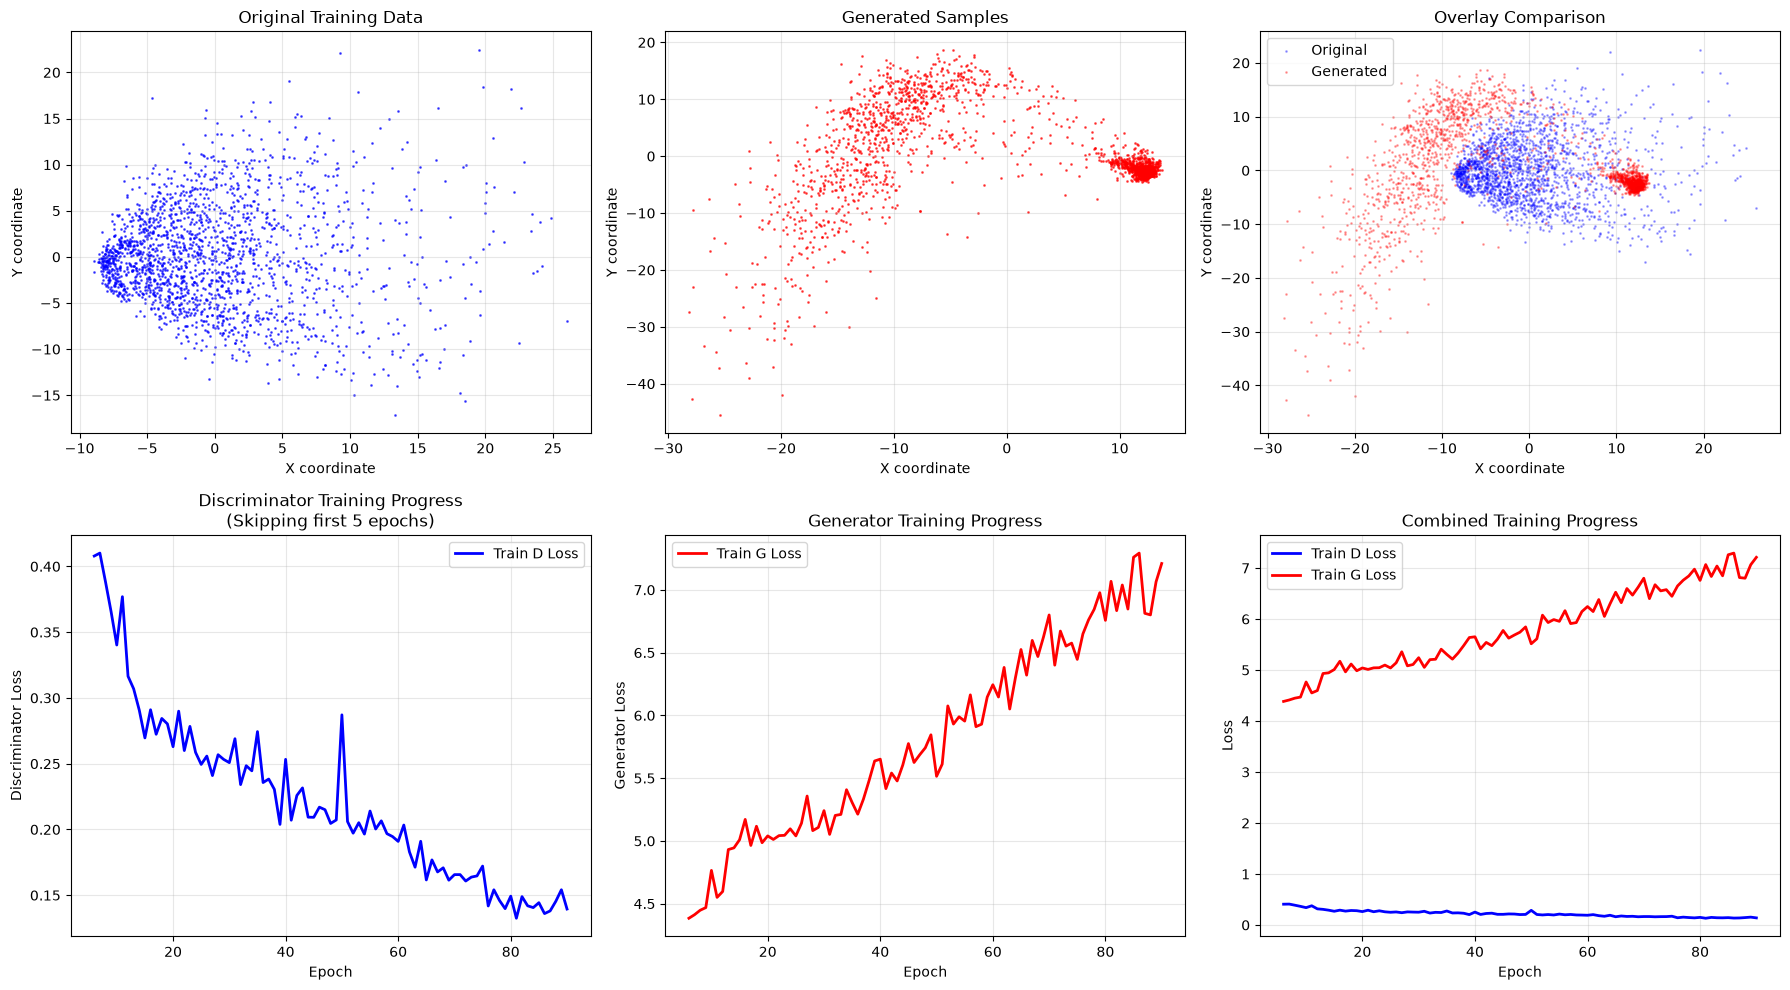

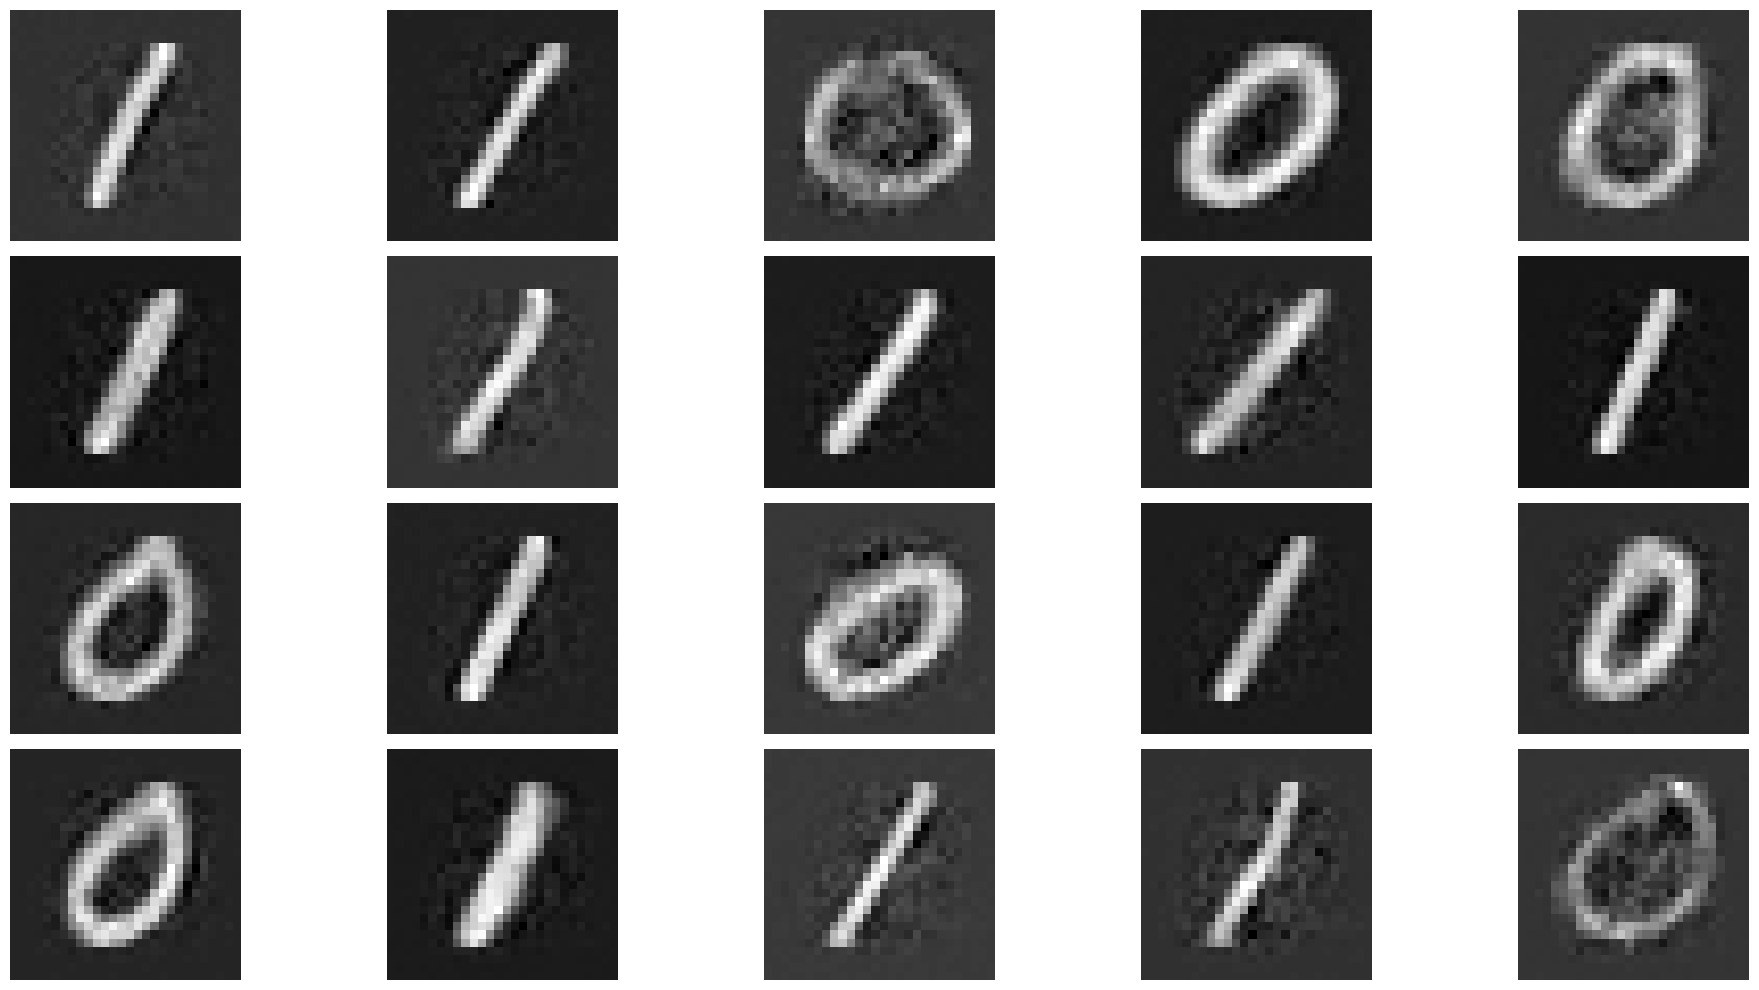

📈 Epoch 90 Summary:
   Train D Loss: 0.1395, Val D Loss: 0.1679
   Train G Loss: 7.2100, Val G Loss: 3.9527

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.134376	G_loss: 4.912653
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.057671	G_loss: 5.743774
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.327441	G_loss: 9.614500
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.069644	G_loss: 5.017964
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.025369	G_loss: 11.998690
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.175686	G_loss: 7.121041
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.051294	G_loss: 7.441193
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.057241	G_loss: 9.005434
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.085874	G_loss: 4.474038
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.153723	G_loss: 4.683380
====> Epoch: 91 Train D_loss: 0.1379, Train G_loss: 7.4303
====> Epoch: 91 Val D_loss: 0.3952, Val G_loss: 6.7999
📈 Epoch 91 Summary:
   Train D Loss: 0.1379, Val D Loss: 0.3952
   Train G Loss: 7.430

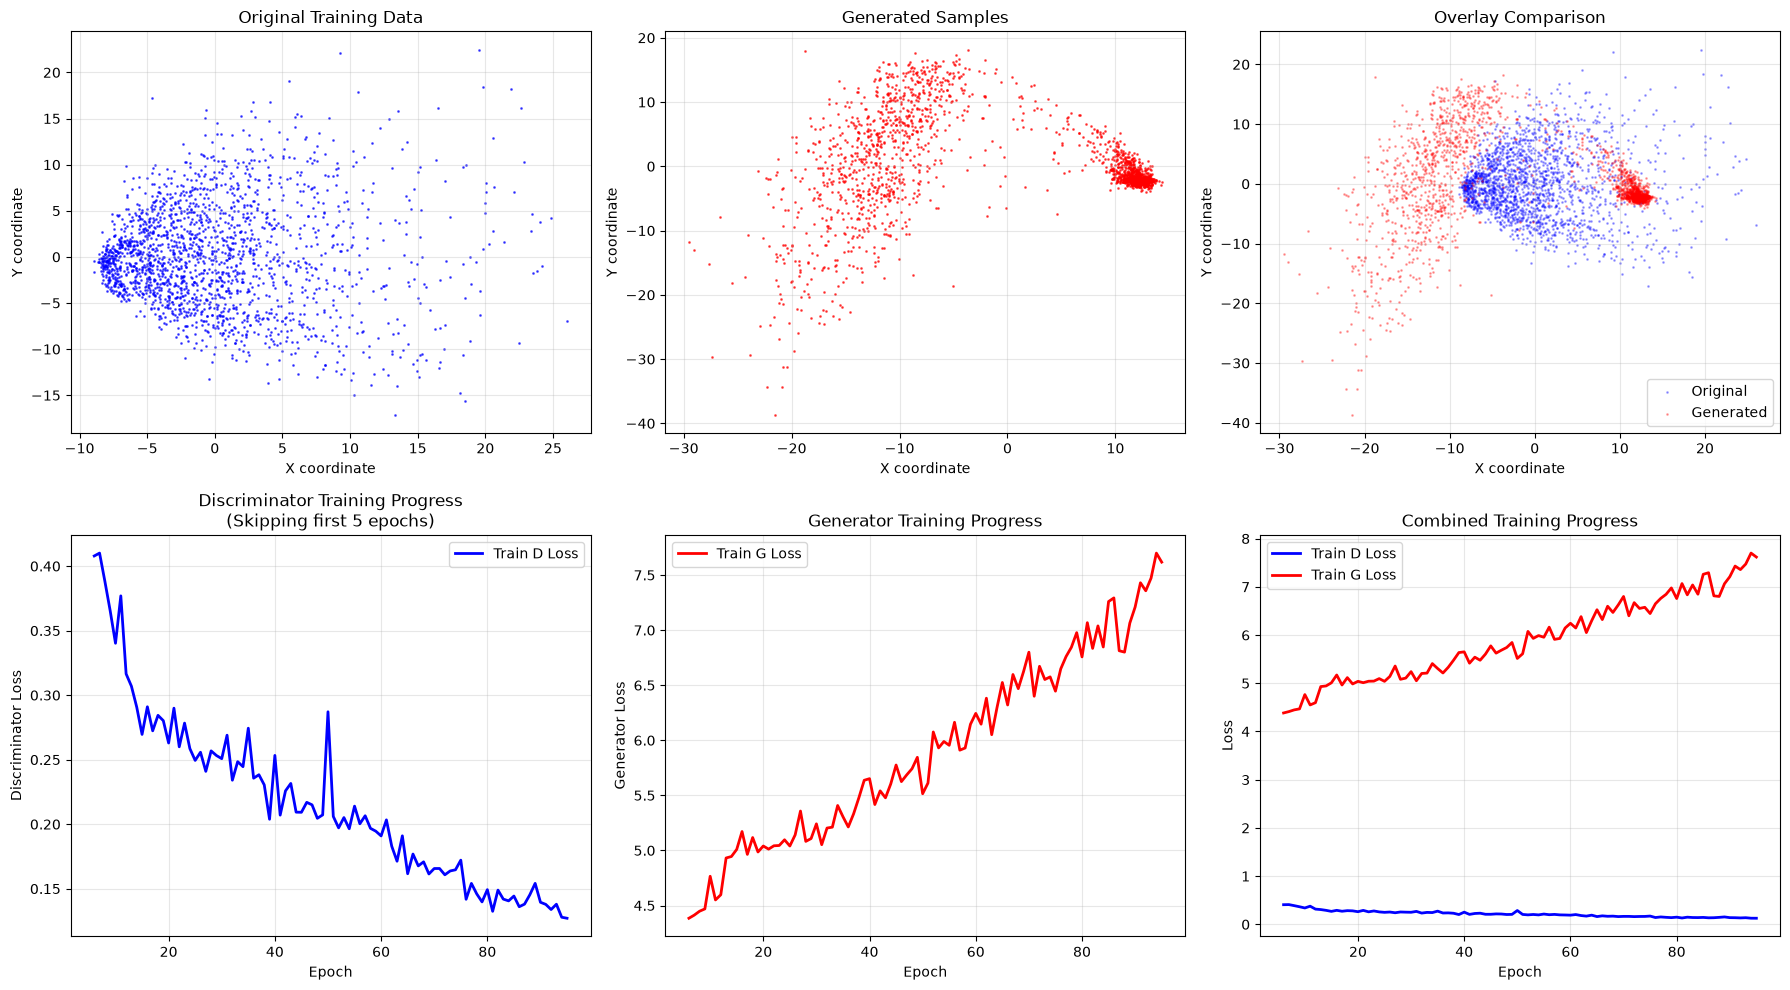

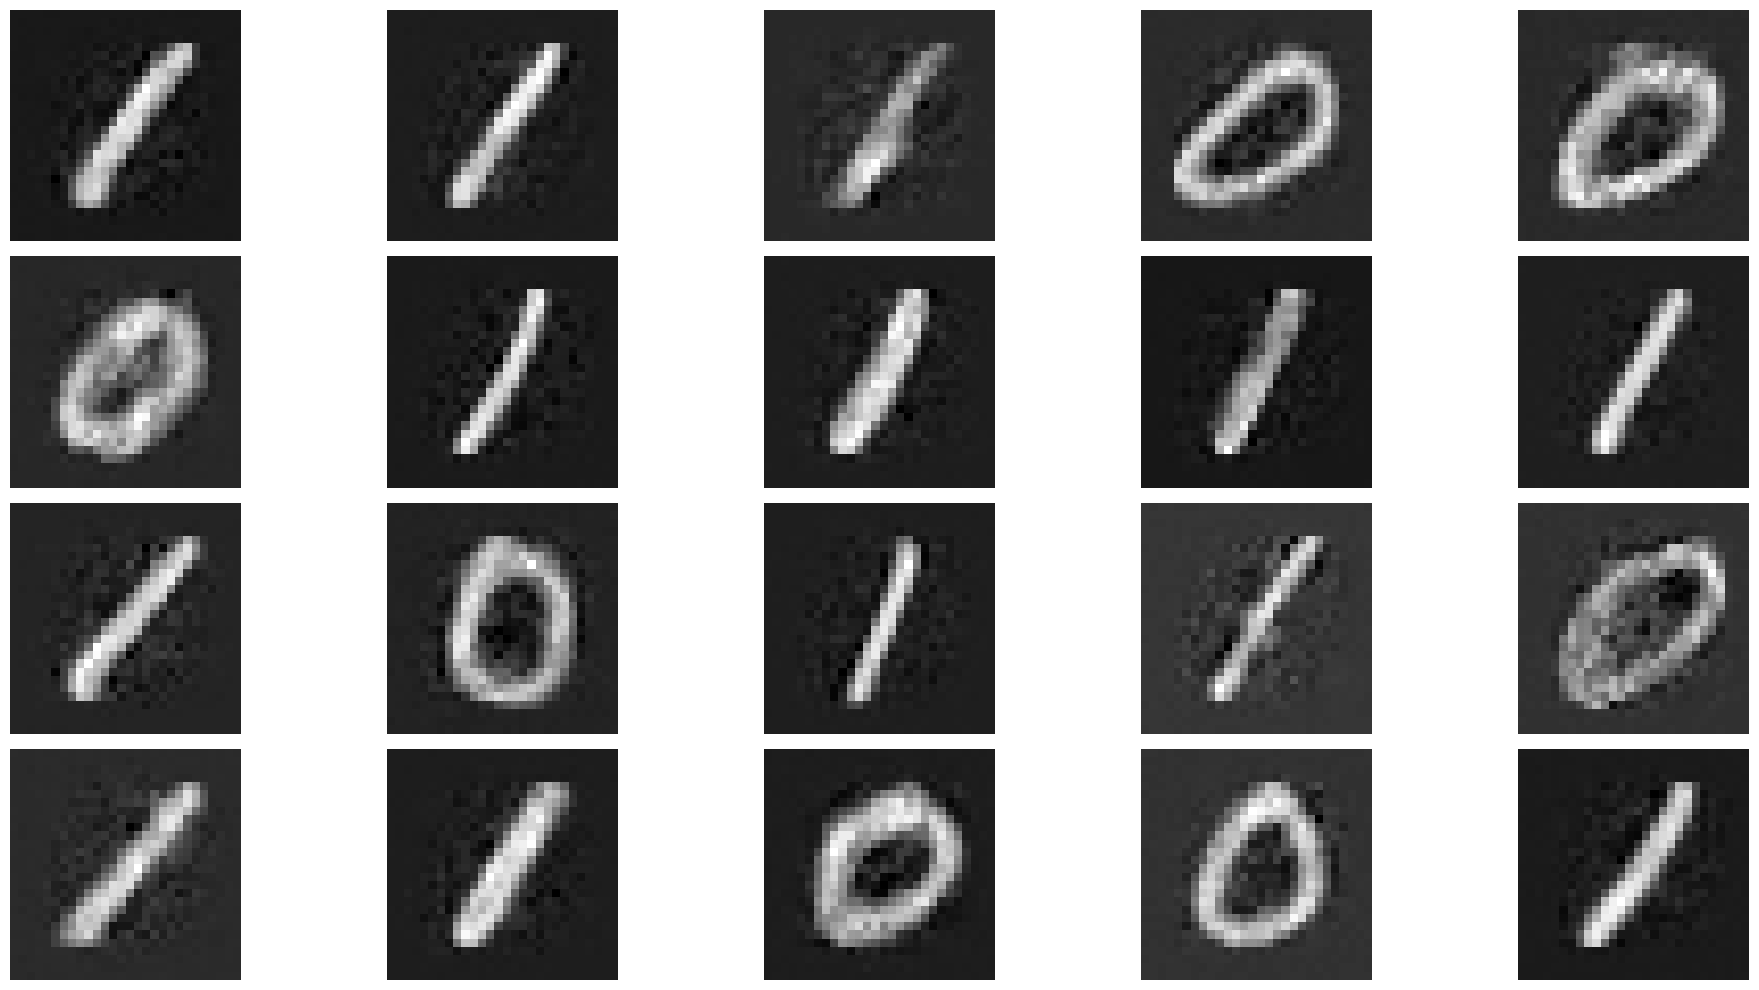

📈 Epoch 95 Summary:
   Train D Loss: 0.1271, Val D Loss: 0.1399
   Train G Loss: 7.6176, Val G Loss: 5.4131

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.095189	G_loss: 5.936034
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.052401	G_loss: 6.712446
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.147117	G_loss: 6.631433
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.206558	G_loss: 7.333052
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.052202	G_loss: 8.513912
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.098533	G_loss: 6.039974
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.084561	G_loss: 10.106030
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.186775	G_loss: 5.545873
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.363090	G_loss: 4.815458
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.199595	G_loss: 6.280402
====> Epoch: 96 Train D_loss: 0.1276, Train G_loss: 7.5313
====> Epoch: 96 Val D_loss: 0.1550, Val G_loss: 6.3432
📈 Epoch 96 Summary:
   Train D Loss: 0.1276, Val D Loss: 0.1550
   Train G Loss: 7.531

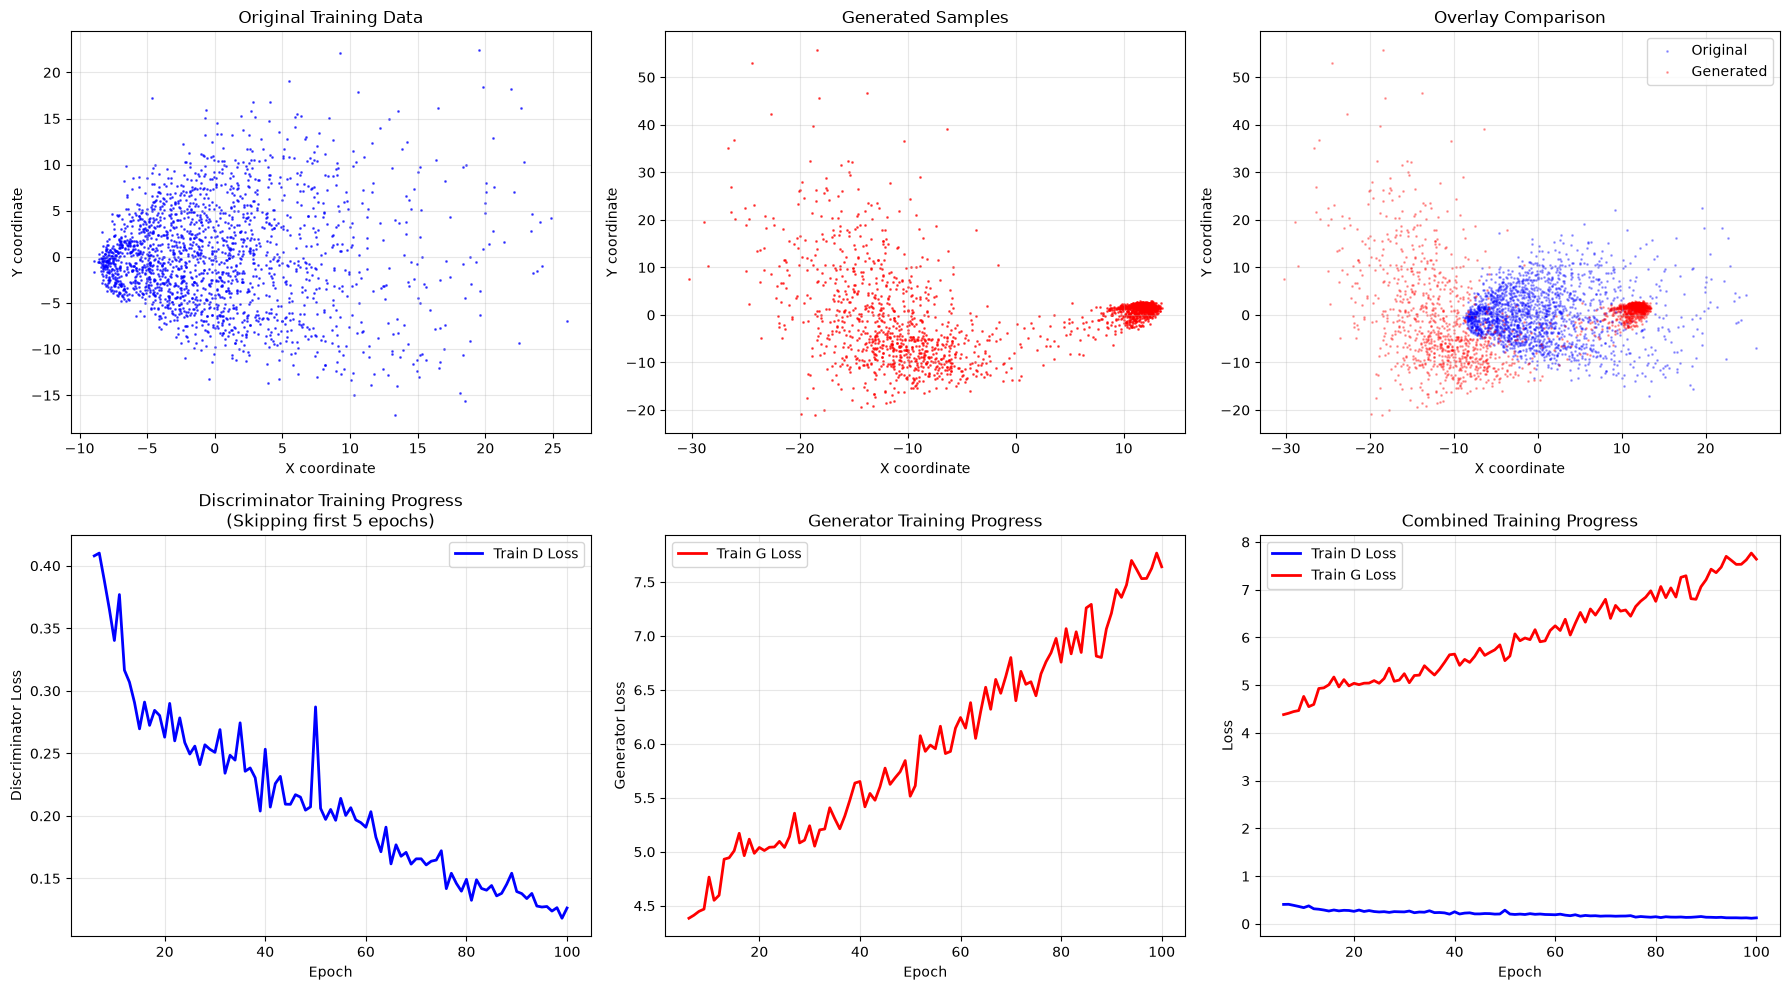

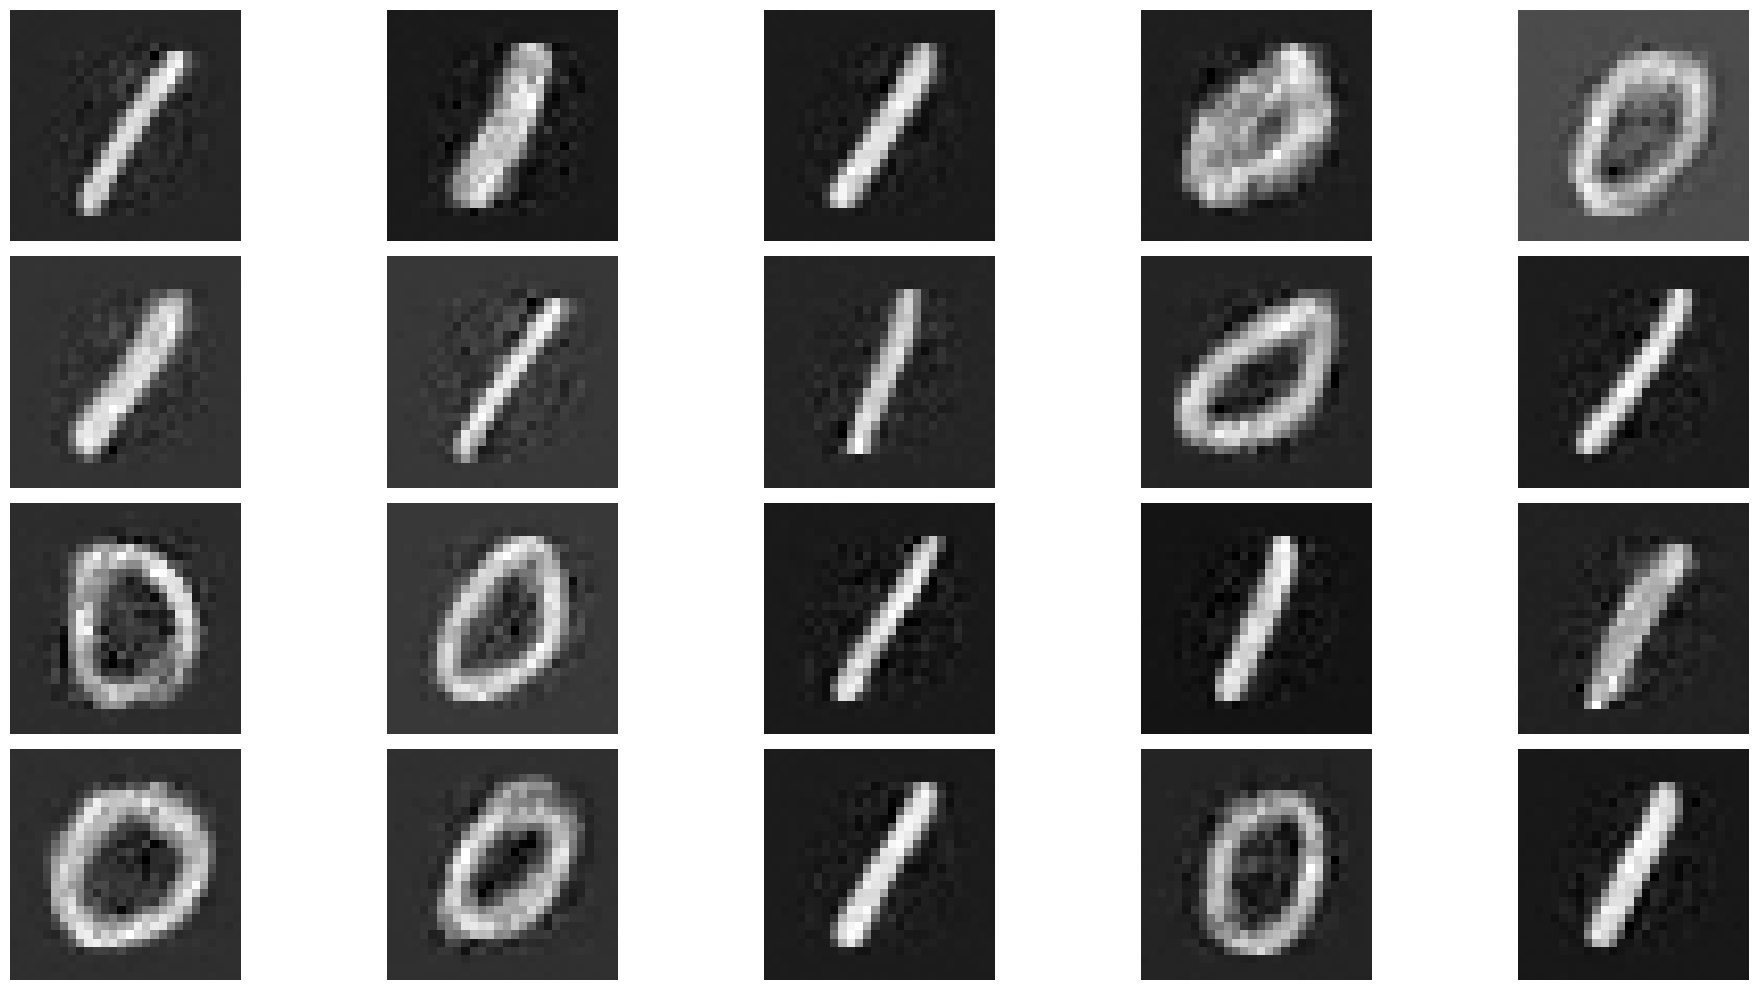

📈 Epoch 100 Summary:
   Train D Loss: 0.1263, Val D Loss: 0.1134
   Train G Loss: 7.6411, Val G Loss: 8.2949

🎉 Training completed!

🎨 Final comprehensive visualization:


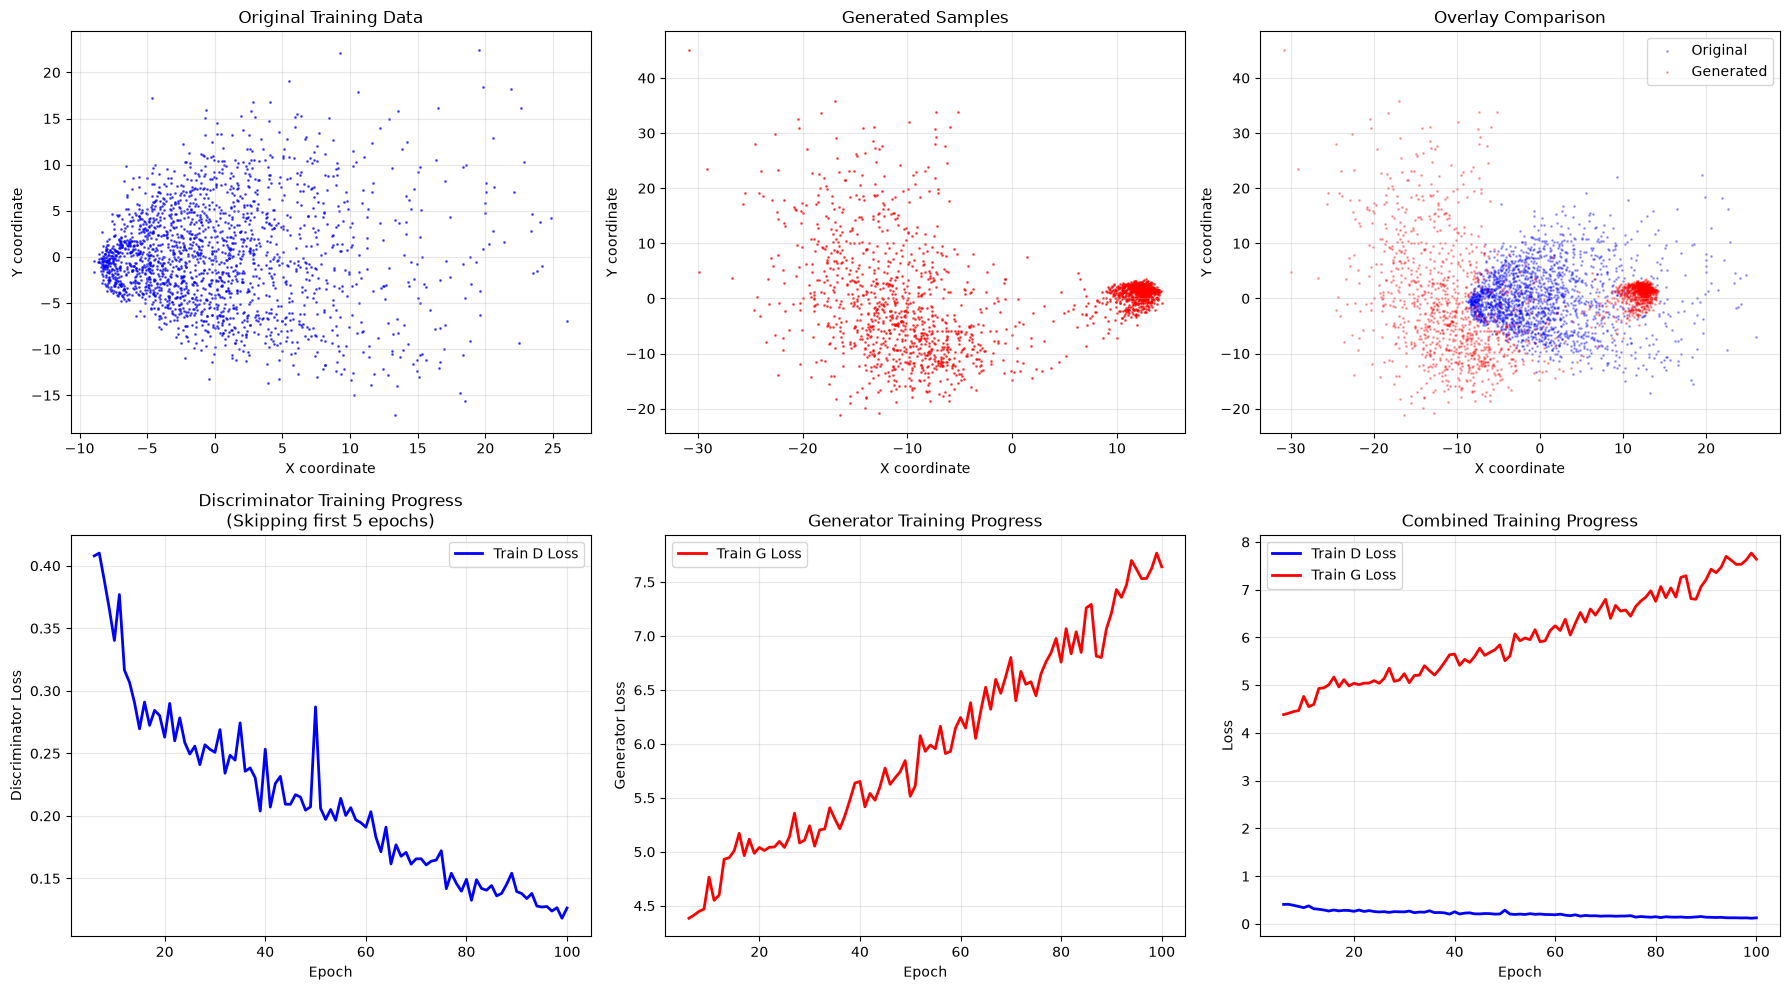

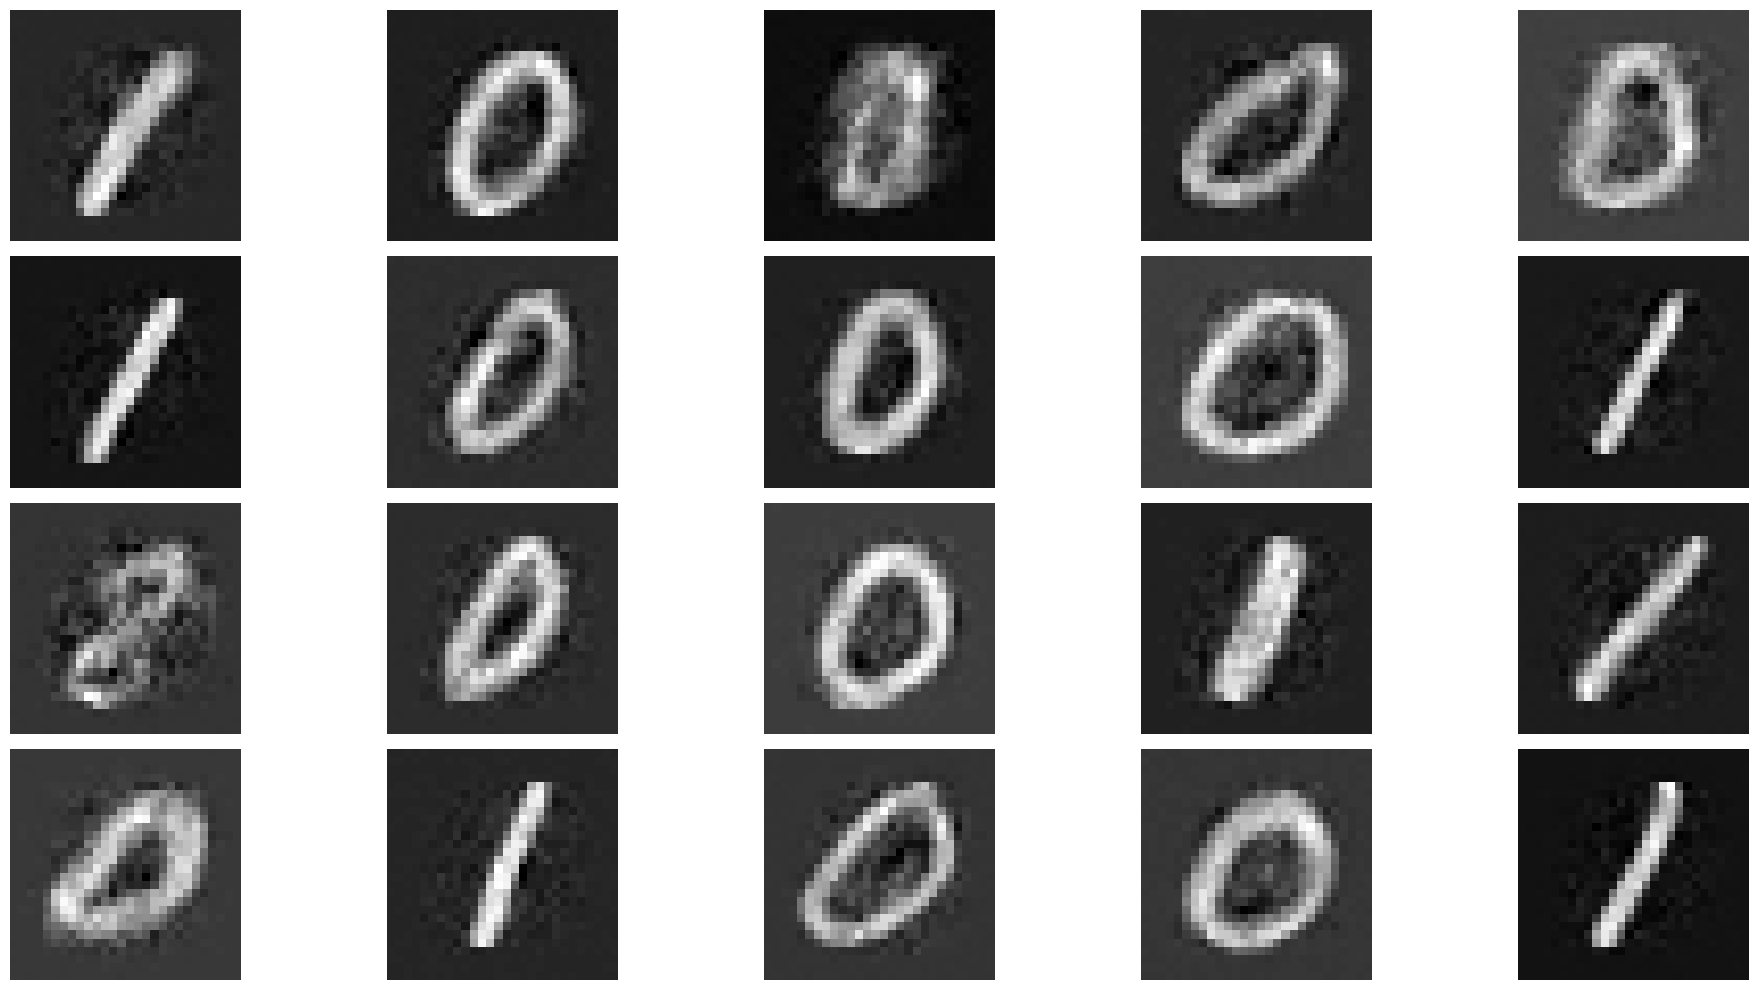

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


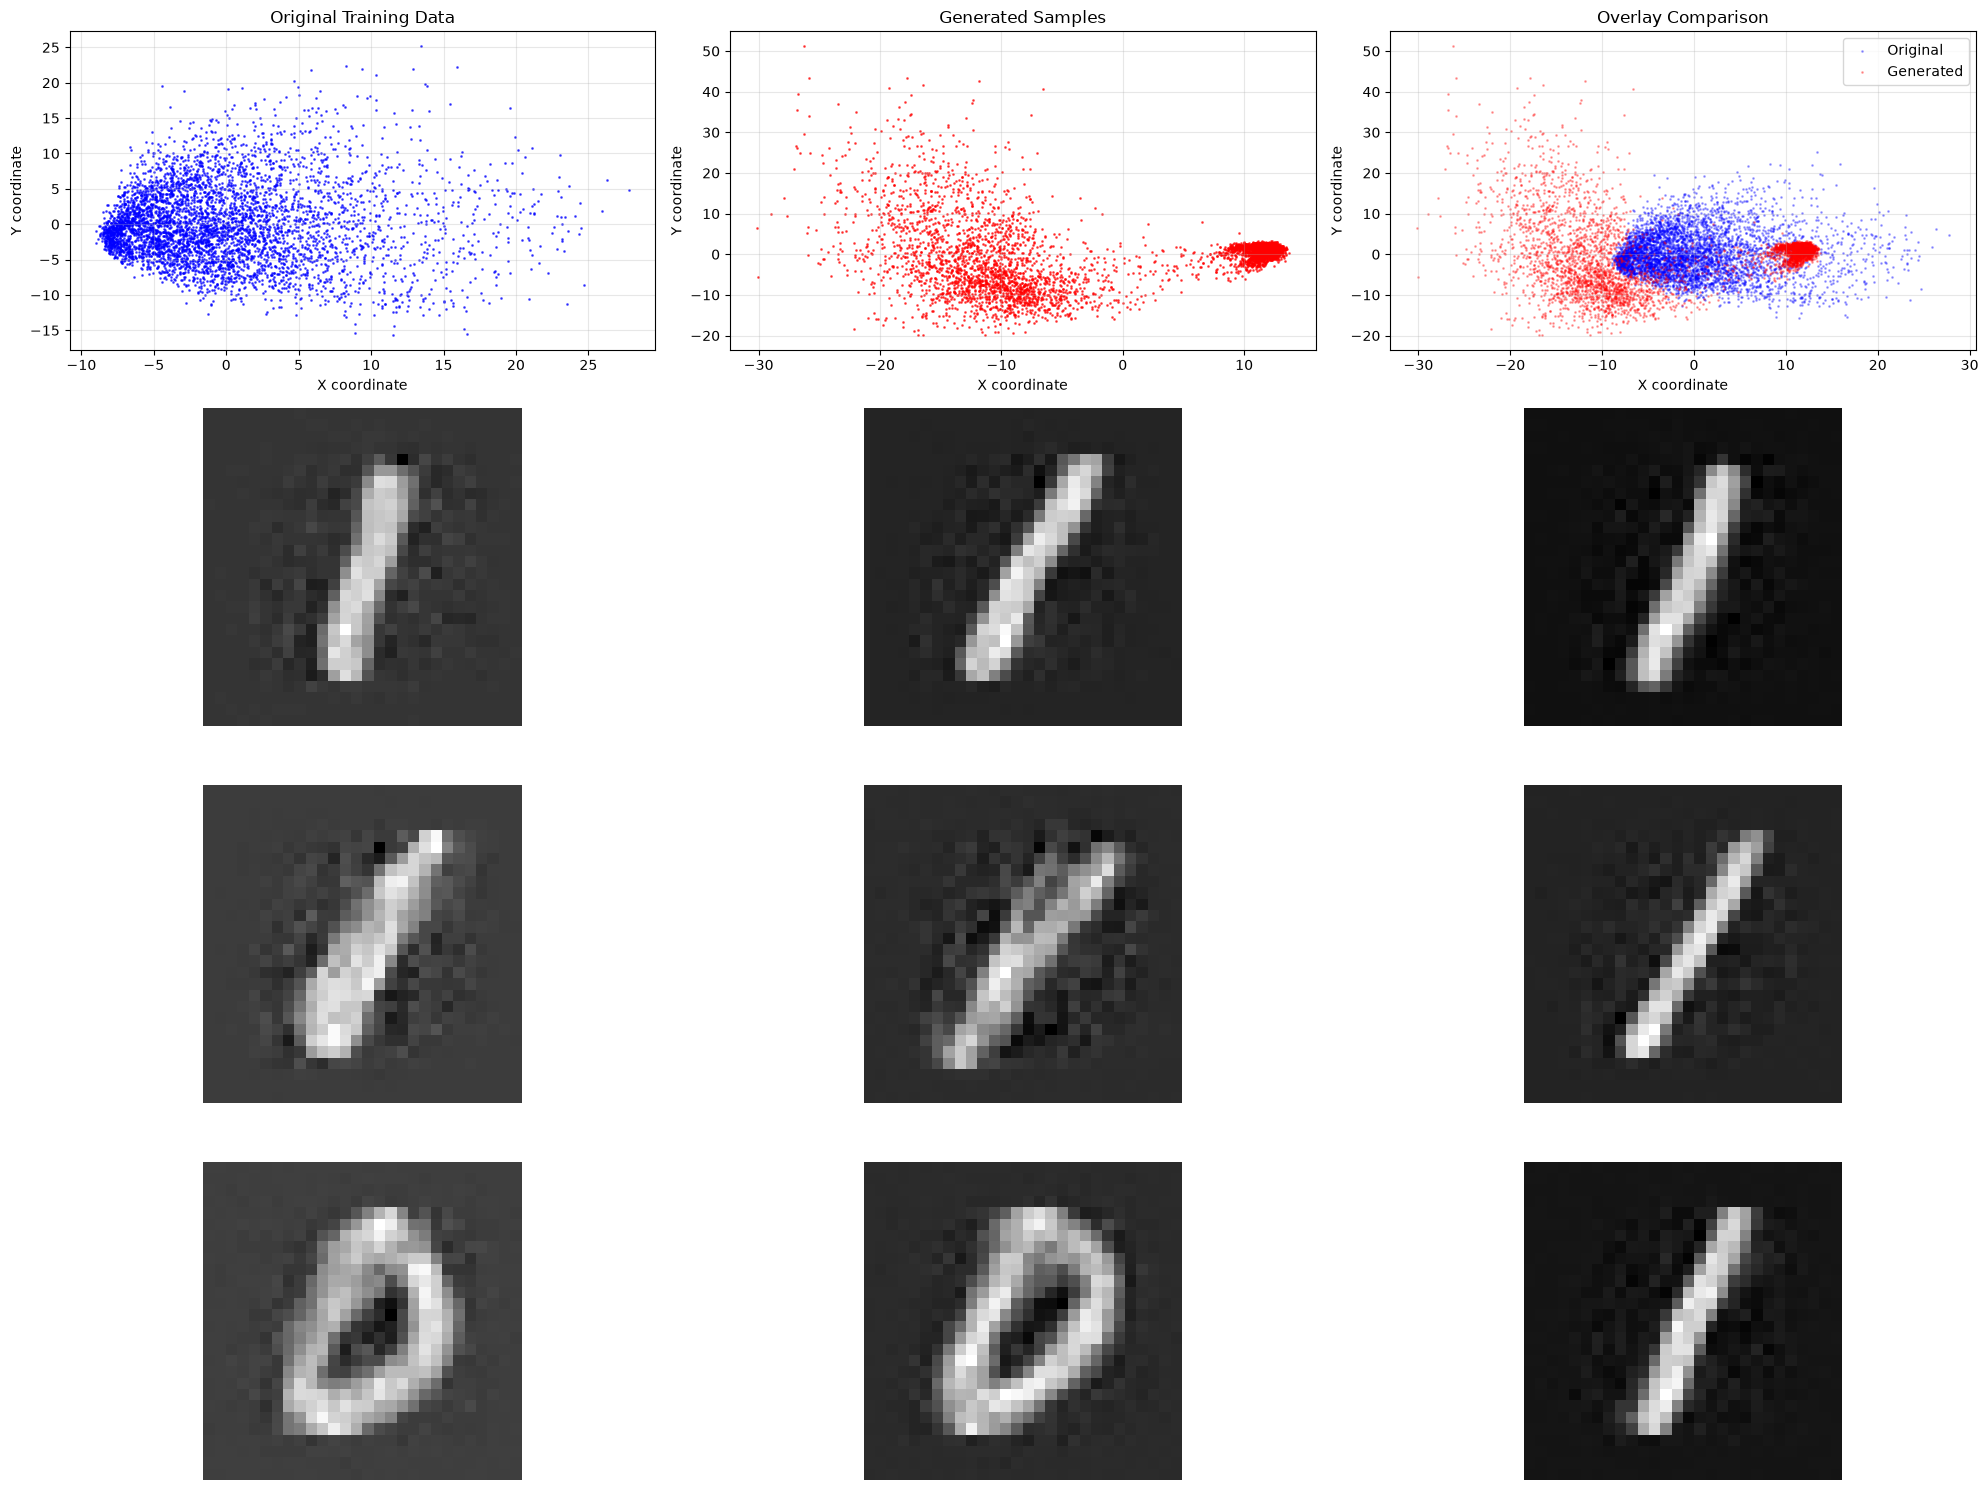

Real data confidence: 0.130
Fake data confidence: 0.004


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
